## Import libraries

In [1]:
import numpy as np
import pandas as pd
from utils_cp import *
from collections import defaultdict
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
import json

## Read data

In [2]:
flopp_df_trans = pd.read_csv('flopp_data_ir_final_transmission.csv')
del flopp_df_trans['Unnamed: 0']

flopp_df = pd.read_csv('flopp_data_ir_final.csv')
del flopp_df['Unnamed: 0']
flopp_df.columns = list(np.float64(flopp_df.columns[:-4])) + list(flopp_df.columns[-4:])
flopp_df = flopp_df.query('polymer != "Cotton"').reset_index(drop=True)
flopp_df.columns = list(np.float64(flopp_df.columns[:-4])) + list(flopp_df.columns[-4:])

rebecca_df = pd.read_csv('rebecca_data_ir_final.csv')
del rebecca_df['Unnamed: 0']
rebecca_df.columns = list(np.float64(rebecca_df.columns[:-4])) + list(rebecca_df.columns[-4:])

stearates_df = pd.read_csv('stearates_data_ir_final.csv')
del stearates_df['Unnamed: 0']
stearates_df.columns = list(np.float64(stearates_df.columns[:-4])) + list(stearates_df.columns[-4:])

gloves_data_ir = pd.read_csv('gloves_data_ir_final.csv')
del gloves_data_ir['Unnamed: 0']
gloves_data_ir.columns = list(np.float64(gloves_data_ir.columns[:-4])) + list(gloves_data_ir.columns[-4:])
gloves_data_ir = gloves_data_ir.query('background == "no_background"').reset_index(drop=True)
gloves_data_ir['polymer'] = ''
gloves_data_ir['label'] = ''

In [3]:
gloves_data_ir.iloc[:,:-6]

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2951.0,2953.0,2955.0,2957.0,2959.0,2961.0,2963.0,2965.0,2967.0,2969.0
0,-1.444414,-1.307010,-1.371832,-1.024954,-0.614494,0.270626,0.360522,0.094041,0.472373,0.795927,...,1.211754,2.338121,1.399338,1.266952,0.074343,-0.758612,2.714175,8.194293,8.400804,5.630272
1,0.556217,-0.203218,-0.583122,-0.405186,-1.206693,-1.637765,-1.226802,-0.892569,-1.203896,-0.140439,...,2.804698,3.915601,2.683937,1.452257,1.718368,2.620480,5.050317,6.560156,5.280068,5.047384
2,0.460728,0.560144,0.656702,0.753825,0.854252,0.966307,1.088735,1.207926,1.325836,1.443126,...,0.889379,0.860236,0.827233,0.795930,0.764099,0.744401,0.743679,0.754220,0.752570,0.718876
3,0.450756,0.969158,1.413329,0.299431,-1.093930,-0.885051,-0.536277,-1.359166,-1.961817,-0.640585,...,0.300995,-0.517416,1.258307,2.798382,6.769918,9.987707,3.877588,-0.803265,2.047189,5.136967
4,-0.983209,-0.977079,-0.931675,-0.885621,-0.865748,-0.839986,-0.824942,-0.825400,-0.823768,-0.814618,...,2.008903,1.930066,1.872083,1.916036,1.958294,1.926608,1.868649,1.815011,1.720470,1.662378
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1209,-0.274678,-0.281003,-0.293222,-0.296954,-0.289273,-0.292848,-0.307613,-0.306951,-0.304668,-0.308887,...,0.587366,0.670153,0.730057,0.743854,0.657752,0.468088,0.286158,0.142908,0.056841,0.013463
1210,-0.293702,-0.290652,-0.277945,-0.267897,-0.278808,-0.290650,-0.291072,-0.288077,-0.285583,-0.284491,...,0.161583,0.180894,0.171051,0.133545,0.098572,0.054644,0.000310,-0.012789,-0.059711,-0.145868
1211,-1.140195,-1.842988,-1.359896,-1.392234,-1.312760,-0.924788,-0.592540,-0.337486,-0.043262,0.332178,...,-2.442312,-2.206943,0.145074,1.326099,-1.265191,-4.446140,-5.600053,-6.732099,-5.423588,-0.511792
1212,-0.436087,-0.435424,-0.435905,-0.436370,-0.435995,-0.435432,-0.435597,-0.435938,-0.435990,-0.436146,...,1.642059,1.804439,1.933676,2.008744,2.008326,1.926425,1.764828,1.518719,1.225571,0.937810


In [4]:
stearates_df.iloc[:,:-4]

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2951.0,2953.0,2955.0,2957.0,2959.0,2961.0,2963.0,2965.0,2967.0,2969.0
0,-0.677401,-0.674559,-0.675539,-0.677402,-0.676900,-0.674237,-0.673170,-0.675216,-0.676238,-0.676073,...,0.788418,0.847895,0.872413,0.846315,0.765436,0.632738,0.477322,0.318289,0.169309,0.036247
1,-0.694795,-0.695760,-0.700337,-0.705499,-0.710680,-0.715920,-0.721426,-0.724154,-0.722205,-0.719149,...,0.911799,0.937626,0.971048,1.005791,1.022697,1.006264,0.959787,0.874096,0.766650,0.664242
2,-0.691709,-0.693341,-0.689982,-0.685116,-0.682244,-0.679764,-0.680251,-0.678779,-0.674024,-0.669987,...,0.464884,0.480274,0.479712,0.452118,0.386257,0.295578,0.201722,0.097445,-0.020102,-0.134381
3,-0.939145,-0.941483,-0.940221,-0.932056,-0.917991,-0.903082,-0.893748,-0.891455,-0.896084,-0.906056,...,-0.310118,-0.250581,-0.175607,-0.107451,-0.005029,0.015257,-0.096123,-0.162365,-0.188113,-0.222345
4,-0.634486,-0.635811,-0.640758,-0.643067,-0.638302,-0.627853,-0.618465,-0.609649,-0.597240,-0.579334,...,-0.140956,-0.109062,-0.104957,-0.134354,-0.202254,-0.293547,-0.380311,-0.456547,-0.526444,-0.599874
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311,-0.604275,-0.600061,-0.606922,-0.609094,-0.600970,-0.596870,-0.593745,-0.588321,-0.591672,-0.598449,...,-0.264617,-0.213607,-0.218182,-0.265578,-0.312244,-0.327162,-0.356168,-0.418304,-0.451800,-0.468151
312,-0.691918,-0.698956,-0.696708,-0.699151,-0.699851,-0.691112,-0.692729,-0.695796,-0.698092,-0.699189,...,-0.096812,-0.001852,0.037025,0.055600,0.024423,-0.097797,-0.230621,-0.276041,-0.323878,-0.424988
313,-0.657931,-0.664685,-0.670745,-0.666269,-0.654655,-0.648431,-0.646318,-0.638957,-0.635207,-0.633452,...,0.830017,0.905034,0.915179,0.843338,0.725898,0.578960,0.442156,0.313410,0.163015,-0.002627
314,-0.746639,-0.746865,-0.747420,-0.748362,-0.749498,-0.750597,-0.751979,-0.753504,-0.754063,-0.753687,...,1.732115,1.791201,1.843408,1.843685,1.779603,1.672405,1.532769,1.370672,1.191086,0.991604


In [5]:
rebecca_df.iloc[:,:-4]

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2951.0,2953.0,2955.0,2957.0,2959.0,2961.0,2963.0,2965.0,2967.0,2969.0
0,-0.406216,-0.431924,-0.456876,-0.470193,-0.484782,-0.466454,-0.447103,-0.469819,-0.469329,-0.411256,...,0.098746,-0.053528,-0.181155,-0.274170,-0.368259,-0.388913,-0.449819,-0.538098,-0.521346,-0.484559
1,-0.385213,-0.332119,-0.293794,-0.330109,-0.343308,-0.287789,-0.233314,-0.261990,-0.344962,-0.368998,...,0.422954,0.356287,0.403204,0.371947,0.094877,-0.153086,-0.140465,-0.248723,-0.424777,-0.529156
2,-0.435317,-0.358338,-0.362767,-0.411997,-0.409764,-0.412623,-0.433729,-0.421248,-0.392247,-0.394206,...,0.530626,0.162017,0.072579,0.121223,-0.101304,-0.328963,-0.352206,-0.308009,-0.239551,-0.242815
3,-0.166157,-0.219938,-0.237203,-0.358353,-0.311266,-0.197020,-0.315760,-0.410451,-0.365159,-0.298786,...,-0.401620,-0.626078,-0.764955,-0.681588,-0.364712,-0.021036,-0.149377,-0.367894,-0.293065,-0.313678
4,-0.444779,-0.433871,-0.436594,-0.454987,-0.467662,-0.471039,-0.466131,-0.453796,-0.444250,-0.440439,...,0.906030,0.748207,0.582144,0.424724,0.336559,0.270754,0.163493,0.043230,-0.068643,-0.107847
5,-0.461390,-0.462484,-0.424458,-0.445486,-0.363786,-0.306715,-0.416399,-0.418559,-0.385579,-0.381898,...,0.099458,0.236498,0.048018,-0.104568,-0.267653,-0.267981,-0.117526,-0.238113,-0.331153,-0.288431
6,-0.289230,-0.395668,-0.456623,-0.479612,-0.467724,-0.488288,-0.579639,-0.616961,-0.571039,-0.520873,...,-0.075303,-0.233711,-0.247350,0.050686,0.048301,-0.097526,-0.054621,-0.035145,-0.121181,-0.124386
7,-0.360817,-0.384711,-0.387412,-0.376193,-0.374977,-0.380428,-0.370800,-0.369368,-0.371826,-0.374912,...,0.886408,0.661568,0.440865,0.316472,0.267277,0.162661,0.062422,0.051280,0.023412,-0.029050
8,-0.342585,-0.340815,-0.314168,-0.307530,-0.305066,-0.318285,-0.338967,-0.346296,-0.344564,-0.340809,...,0.914939,0.770545,0.647265,0.512772,0.383630,0.273768,0.184909,0.087362,0.008294,-0.077176
9,-0.417538,-0.476062,-0.501116,-0.493714,-0.479888,-0.470955,-0.457619,-0.461593,-0.455466,-0.394108,...,0.101529,-0.127682,-0.373234,-0.437141,-0.498964,-0.508035,-0.392341,-0.323162,-0.356884,-0.324044


In [39]:
seed = 0

#data = rebecca_df.copy()#
#label_table = label_table_st.copy()


def gen_data_sets(data_1, data_2, data_test, seed):
    
    np.random.seed(seed)
    #idx_ref = np.random.rand(data_2.shape[0]) > .50
    
    poly_list_data_2 = np.unique(data_2['polymer'])
    idx_strat = [np.where(data_2['polymer'] == p)[0] for p in poly_list_data_2]
    ids_ref = np.concatenate([np.random.choice(x, size=int(x.shape[0]/2), replace=False) for x in idx_strat])
    idx_ref = np.array([i in ids_ref for i in range(data_2.shape[0])])
    
    data_ref = pd.concat([data_1, data_2.loc[idx_ref,:]], axis=0).reset_index(drop=True)
    data_rest = data_2.loc[~idx_ref,:].reset_index(drop=True)
    
    poly_list = np.unique(data_ref['polymer'])
    label_table = pd.DataFrame({'label':np.arange(poly_list.shape[0]),
                                'polymer':poly_list})
    data_ref = data_ref.merge(label_table)
    data_rest = data_rest.merge(label_table)

    
    reference_library = (data_ref.
                         iloc[:,[-2,-3,-1]+list(range(data_ref.shape[1]-5))].
                         #loc[idx_ref,:].
                         reset_index(drop=True))

    calibration_set = (data_rest.
                         iloc[:,[-2,-3,-1]+list(range(data_rest.shape[1]-5))].
                         #loc[~idx_ref,:].
                         reset_index(drop=True))

    gloves_data_ir.iloc[:,[-4,-2,-1]+list(range(gloves_data_ir.shape[1]-6))]
    
    test_set = (data_test.
                         iloc[:,[-4,-2,-1]+list(range(data_test.shape[1]-6))].
                         reset_index(drop=True))

    return reference_library, calibration_set, test_set, label_table

def process_data(reference_library,
                 calibration_set,
                 test_set):

    # store labels/polymer for reference library
    y_train = reference_library.iloc[:,1].to_numpy()
    label_train = reference_library.iloc[:,2].to_numpy()
    # store spectra for reference library
    X_train = reference_library.iloc[:,3:].to_numpy()
    wl_list = np.float64(reference_library.columns[3:])

    # Perform SNV normalization
    X_train = (X_train - X_train.mean(1)[:, None]) / X_train.std(1)[:, None]

    # store labels/polymer for calibration set
    y_cal = calibration_set.iloc[:,1].to_numpy()
    label_cal = calibration_set.iloc[:,2].to_numpy()
    # store spectra for calibration set
    X_cal = calibration_set.iloc[:,3:].to_numpy()

    # Perform SNV normalization
    X_cal = (X_cal - X_cal.mean(1)[:, None]) / X_cal.std(1)[:, None]


    # store labels/polymer for test set
    y_test = test_set.iloc[:,1].to_numpy()
    label_test = test_set.iloc[:,2].to_numpy()
    # store spectra for calibration set
    X_test = test_set.iloc[:,3:].to_numpy()

    # Perform SNV normalization
    X_test = (X_test - X_test.mean(1)[:, None]) / X_test.std(1)[:, None]
    n_test = X_test.shape[0]

    return X_train, X_cal, X_test, y_train, y_cal, y_test, label_train, label_cal, label_test, n_test, wl_list


# Flopp

In [80]:
reference_library, calibration_set, test_set, label_table = gen_data_sets(#rebecca_df,
                                                                          flopp_df,
                                                                          stearates_df,
                                                                          gloves_data_ir,
                                                                          seed)

## Process spectral data

In [81]:
#calibration_set, test_set = hom_data(reference_library, calibration_set, test_set)

In [82]:
(X_train, X_cal, X_test, 
 y_train, y_cal, y_test, 
 label_train, label_cal, label_test, 
 n_test, wl_list) = process_data(reference_library,
                 calibration_set,
                 test_set)

In [83]:
X_test.shape, X_train.shape, X_cal.shape

((1214, 535), (512, 535), (159, 535))

Acrylonitrile Butadiene Styrene


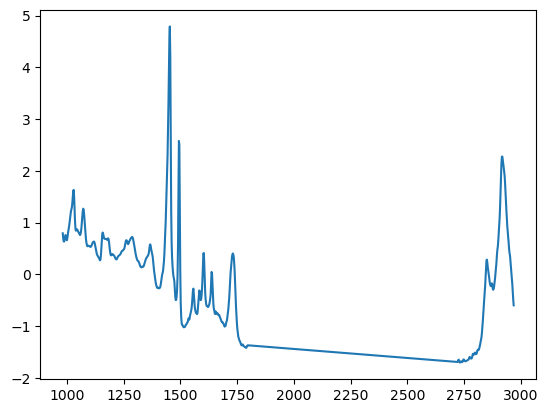

In [84]:
print(y_train[10])
_ = plt.plot(wl_list, X_train[2,:])

## Calculate HQI

In [92]:
# Nearest Neighbor

# Calculate HQI for calibration set
smx_cal = smx_nn(X_train, X_cal, label_train)

# Calculate HQI for test set
smx_test = smx_nn(X_train, X_test, label_train)

(array([70.44882129, 20.52256975, 13.80172819,  9.72121725,  8.16102189,
         7.56094675,  6.84085658,  4.56057105,  2.28028553,  1.80022542]),
 array([0.90484103, 0.91170453, 0.91856803, 0.92543153, 0.93229503,
        0.93915853, 0.94602203, 0.95288553, 0.95974903, 0.96661253,
        0.97347603]),
 <BarContainer object of 10 artists>)

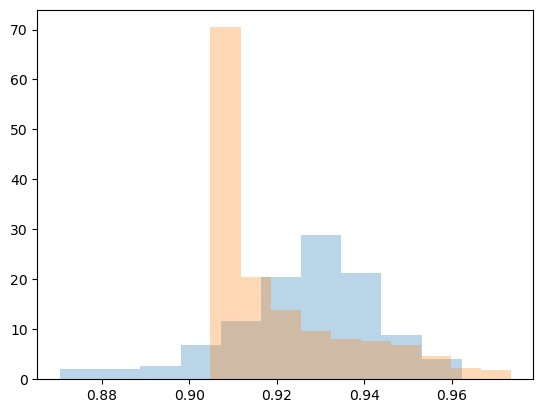

In [93]:
plt.hist(smx_cal[np.arange(X_cal.shape[0]),label_cal], density=True, alpha=.3)
plt.hist(smx_test.max(1), density=True, alpha=.3)

## Perform Conformal Prediction over the test set

In [86]:
# Set confidence level 1 - alpha
n = smx_cal.shape[0]
alpha = 0.1
for alpha in [alpha]:#np.linspace(0.01,.2):
    prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)

    # If we know to true labels of the test set, calculate the empirical confidence 
    if label_test[0] != '' and not np.isnan(label_test[0]):
        empirical_confidence = prediction_sets[np.arange(n_test),label_test].mean()
    else:
        empirical_confidence = None
    
    print('Theo Confidence: '+str(1-alpha))
    print('Threshold(s) used: '+str(np.int64(100*(1-qhat))/100))
    if empirical_confidence is not None:
        print('Empirical confidence: '+str(int(100*empirical_confidence)/100))
    print('Mean prediction set size: '+str(np.round(prediction_sets.sum(1).mean(), 2)))
    print('')

Theo Confidence: 0.9
Threshold(s) used: 0.91
Mean prediction set size: 1.45



In [87]:
prediction_sets_n = [list(label_table.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n])

In [88]:
zero_label = np.where(prediction_sets_size == 0)[0]
single_label = np.where(prediction_sets_size == 1)[0]
mult_label = np.where(prediction_sets_size > 1)[0]

print('Sets with zero labels: ' + str(zero_label.shape[0]))
print('Sets with one label: ' + str(single_label.shape[0]))
print('Sets with >1 labels: ' + str(mult_label.shape[0]))

Sets with zero labels: 695
Sets with one label: 78
Sets with >1 labels: 441


In [52]:
if y_test[0] != '' and not np.isnan(label_test[0]):
    print('accuracy of single labels: ' +str(np.mean([prediction_sets_n[i][0]==y_test[i] for i in single_label])))

In [58]:
output = [prediction_sets_n[i][0] if i in single_label else 
          '--outlier--' if i in zero_label else 
          '--manual check!--' for i in range(label_test.shape[0])]
output_df = pd.DataFrame({'id':test_set['id'],
                          'prection_set':prediction_sets_n,
                          'output':output})
output_df.to_csv('results/test_set_predictions_flopp_stearate.csv')
output_df

,id,prection_set,output
0,MF_L_01_0514_2,"[Calcium Stearate, Magnesium Stearate v2, Poly...",--manual check!--
1,MF_L_01_0514_9,"[Calcium Stearate, Magnesium Stearate v2, Poly...",--manual check!--
2,MF_L_01_0514_12,"[Polyethylene, Rubber]",--manual check!--
3,MF_L_01_0514_14,[Polycarbonate],Polycarbonate
4,MF_L_01_0514_17,[Magnesium Stearate v2],Magnesium Stearate v2
...,...,...,...
1209,KC_N_02_0328_28,[Calcium Stearate],Calcium Stearate
1210,KC_N_02_0328_29,[Zinc Stearate],Zinc Stearate
1211,KC_N_02_0328_30,[Polyethylene],Polyethylene
1212,KC_N_02_0328_31,[Calcium Stearate],Calcium Stearate


## Manual check

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Polycarbonate', 'Polypropylene']


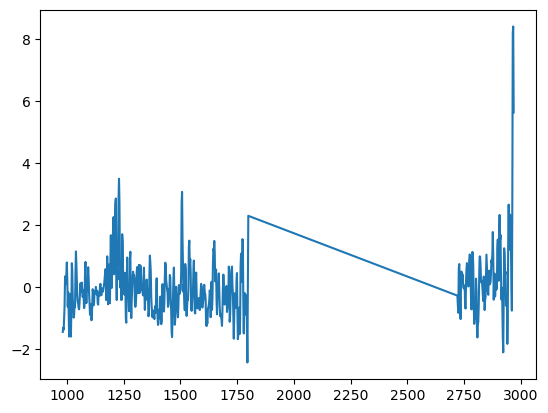

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Polypropylene']


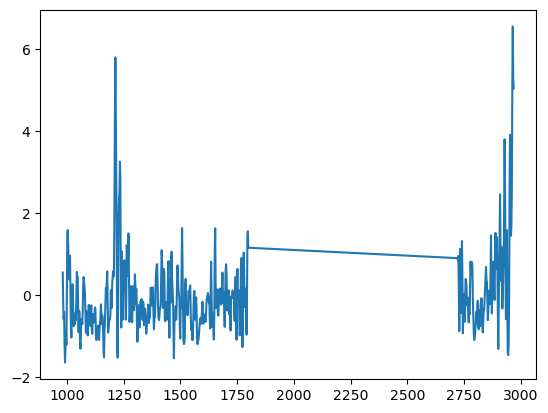

Prediction Set:  ['Polyethylene', 'Rubber']


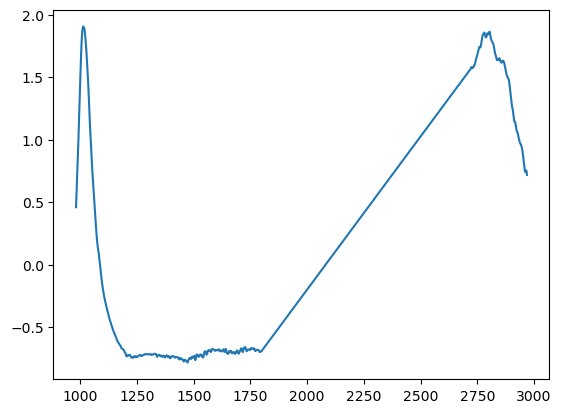

Prediction Set:  ['Cellulose Acetate', 'Polycarbonate']


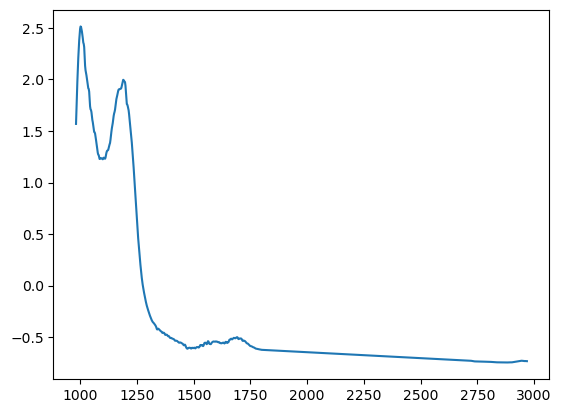

Prediction Set:  ['Polyethylene', 'Polystyrene']


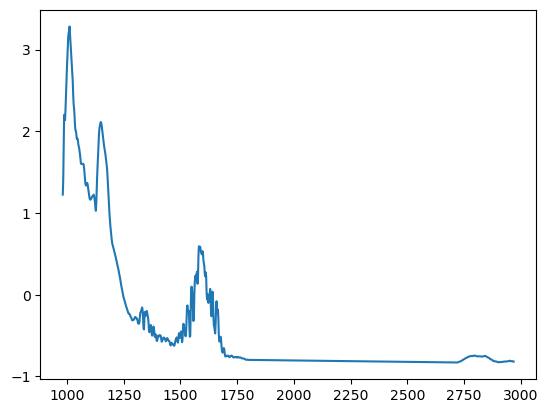

Prediction Set:  ['Polyamide', 'Polyethylene', 'Polypropylene', 'Polystyrene', 'Polyurethane']


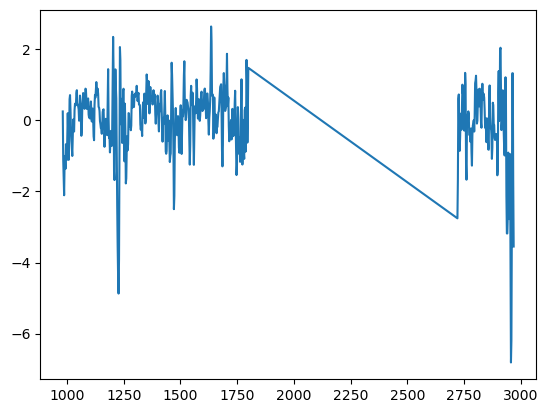

Prediction Set:  ['Magnesium Stearate v2', 'Rubber']


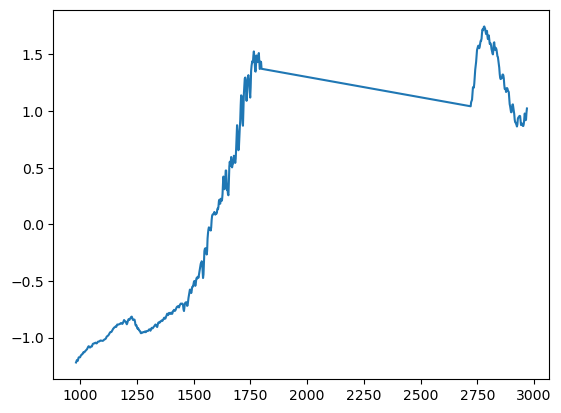

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Polypropylene', 'Zinc Stearate']


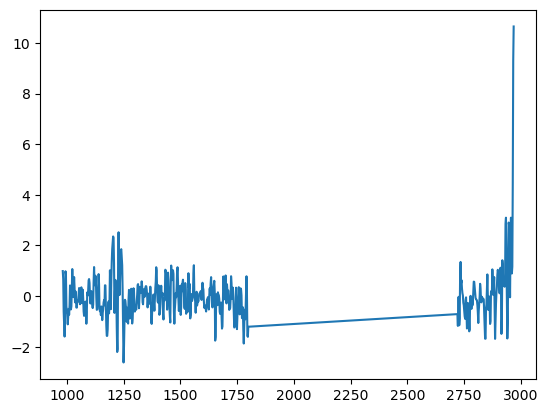

Prediction Set:  ['Magnesium Stearate v2', 'Polyethylene']


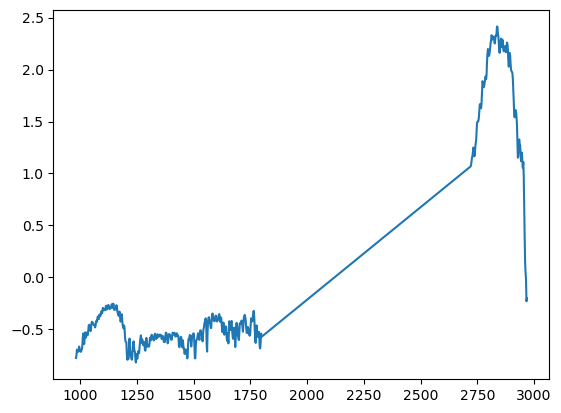

Prediction Set:  ['Polyethylene Adipate', 'Polyethylene Terephthalate', 'Polyurethane']


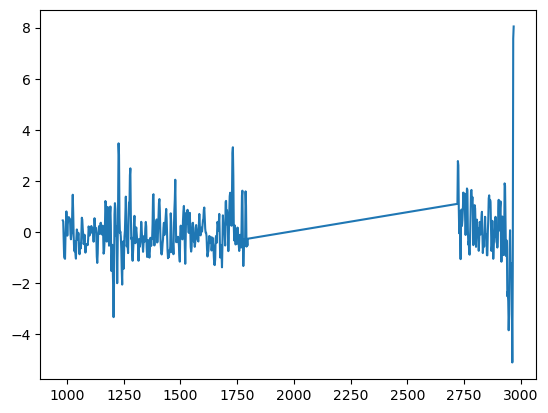

Prediction Set:  ['Magnesium Stearate v2', 'Polypropylene']


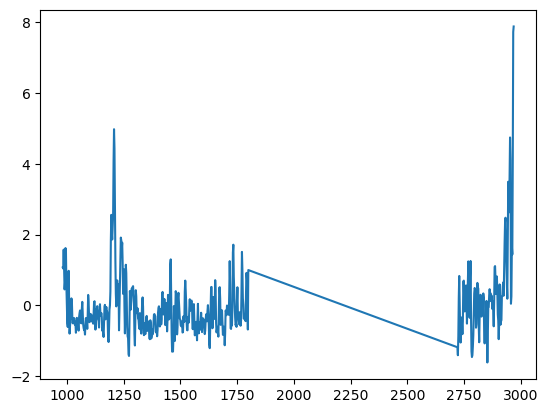

Prediction Set:  ['Polycarbonate', 'Polyurethane']


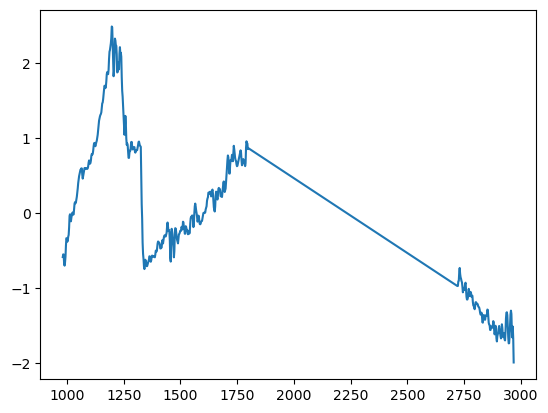

Prediction Set:  ['Polyethylene', 'Polystyrene']


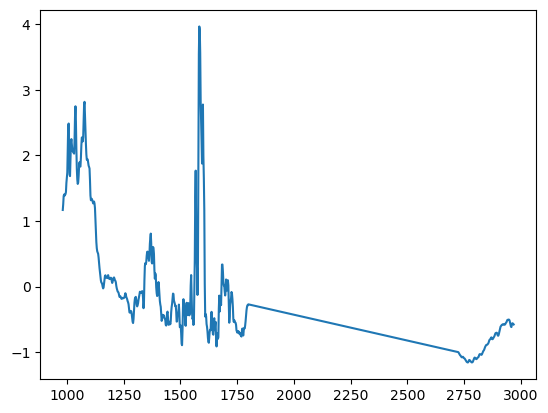

Prediction Set:  ['Polypropylene', 'Polystyrene', 'Rubber']


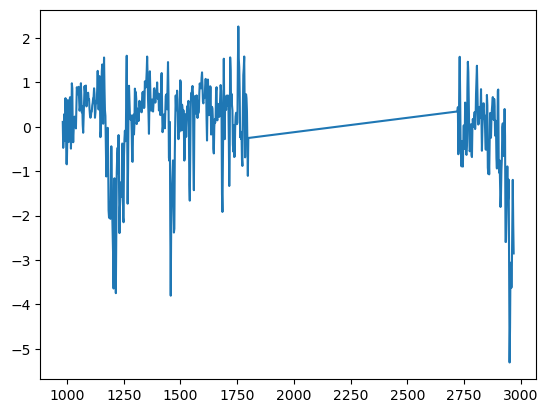

Prediction Set:  ['Magnesium Stearate v2', 'Polypropylene']


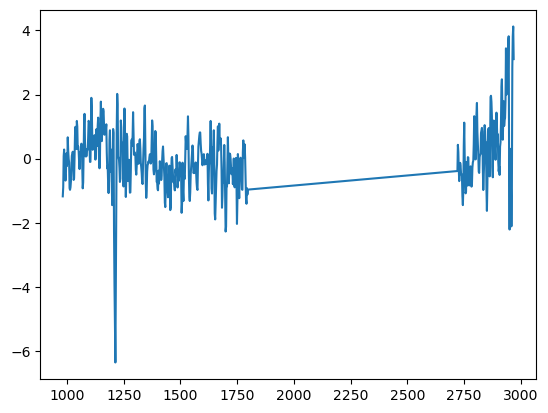

Prediction Set:  ['Magnesium Stearate v2', 'Rubber']


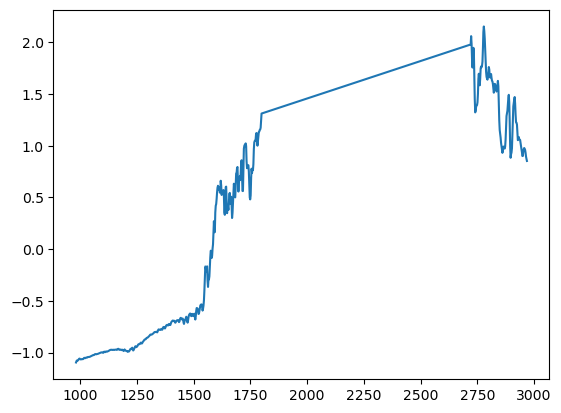

Prediction Set:  ['Polystyrene', 'Polyvinyl Chloride', 'Rubber', 'Sodium Stearate', 'Zinc Stearate']


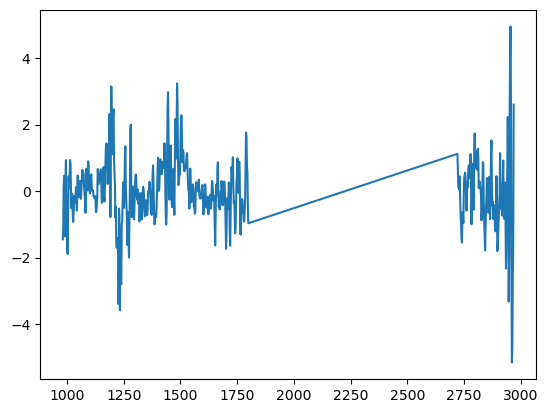

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Zinc Stearate']


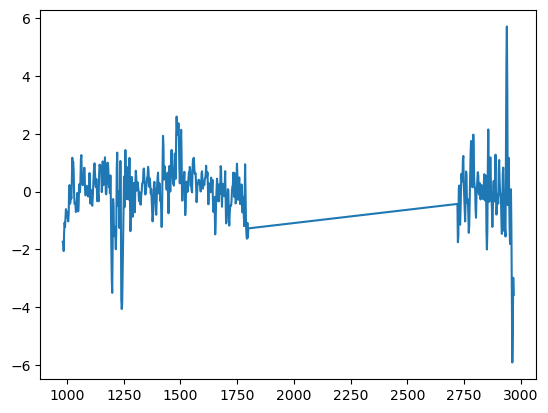

Prediction Set:  ['Polycarbonate', 'Polyethylene Vinyl Acetate', 'Polypropylene']


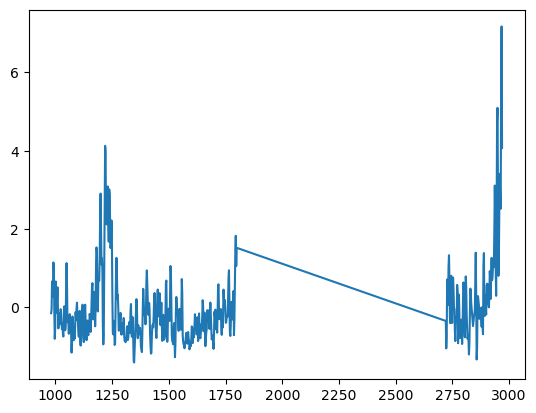

Prediction Set:  ['Polyethylene', 'Polypropylene', 'Polystyrene', 'Polyurethane']


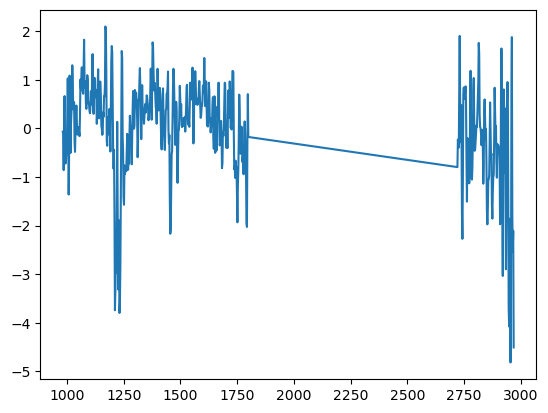

Prediction Set:  ['Polyethylene Terephthalate', 'Polyethylene Vinyl Acetate', 'Polypropylene', 'Polyvinyl Chloride']


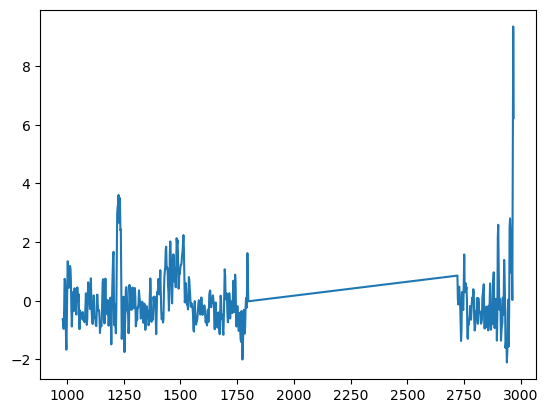

Prediction Set:  ['Calcium Stearate', 'Polypropylene', 'Rubber', 'Sodium Stearate']


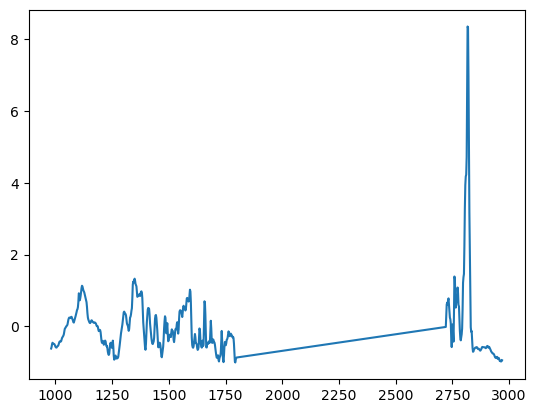

Prediction Set:  ['Polyethylene', 'Polyethylene Terephthalate', 'Rubber']


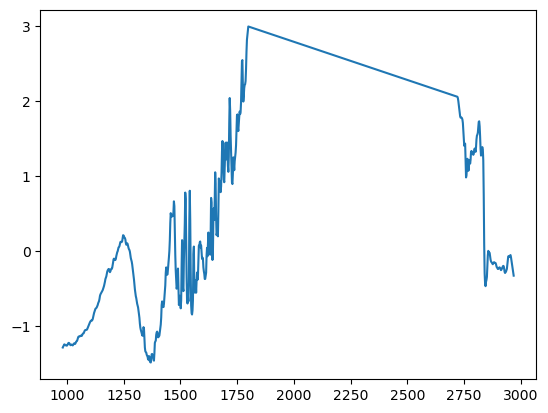

Prediction Set:  ['Magnesium Stearate v2', 'Polyethylene']


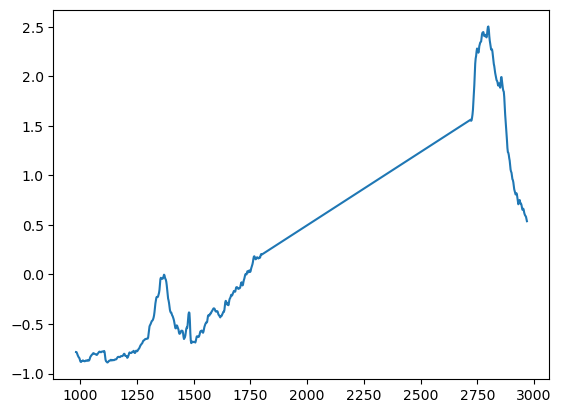

Prediction Set:  ['Polycarbonate', 'Polyurethane']


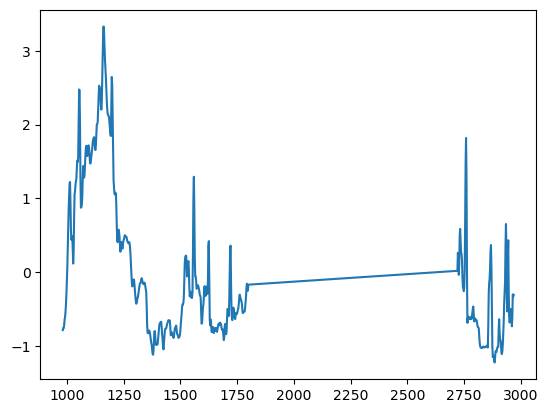

Prediction Set:  ['Magnesium Stearate v2', 'Sodium Stearate', 'Zinc Stearate']


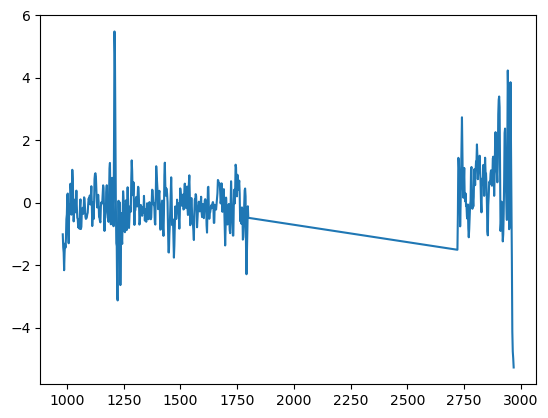

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Polyethylene', 'Zinc Stearate']


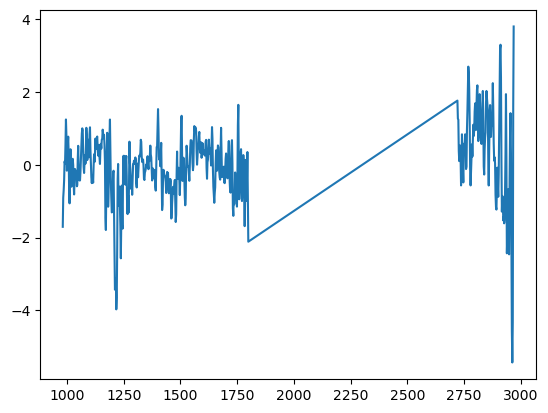

Prediction Set:  ['Magnesium Stearate v2', 'Polyethylene', 'Rubber', 'Zinc Stearate']


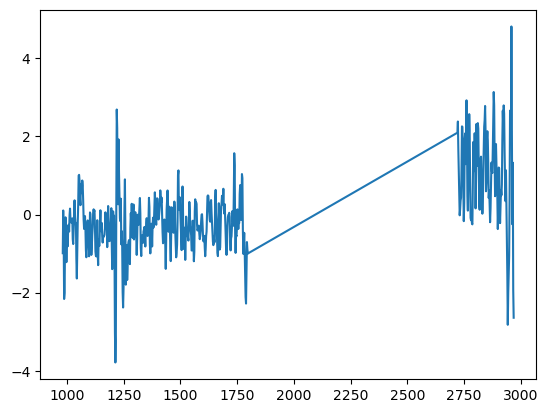

Prediction Set:  ['Magnesium Stearate v2', 'Polycarbonate', 'Polyethylene Vinyl Acetate', 'Polypropylene', 'Polyvinyl Chloride']


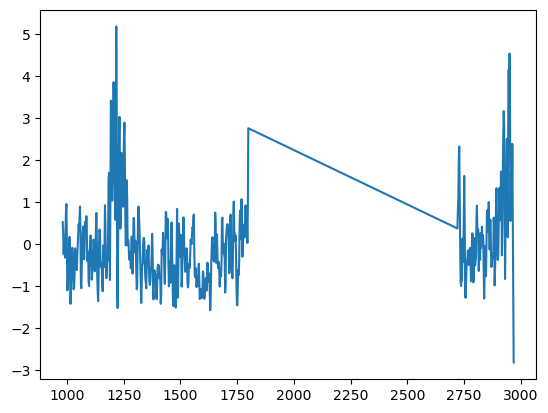

Prediction Set:  ['Polystyrene', 'Polyurethane']


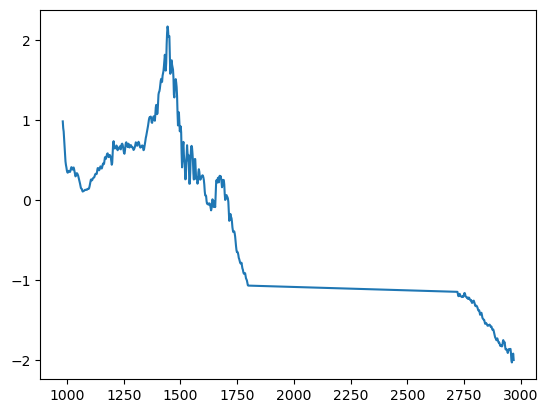

Prediction Set:  ['Calcium Stearate', 'Polyethylene', 'Rubber', 'Zinc Stearate']


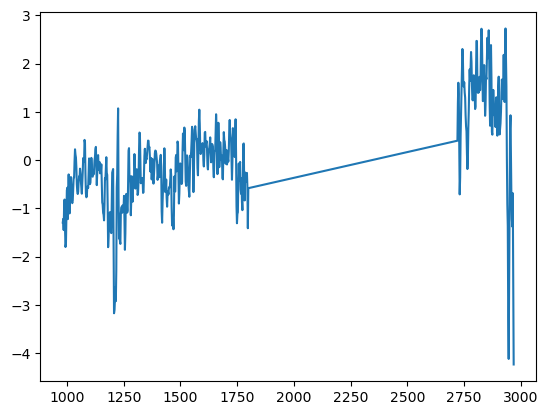

Prediction Set:  ['Magnesium Stearate v2', 'Polyethylene', 'Zinc Stearate']


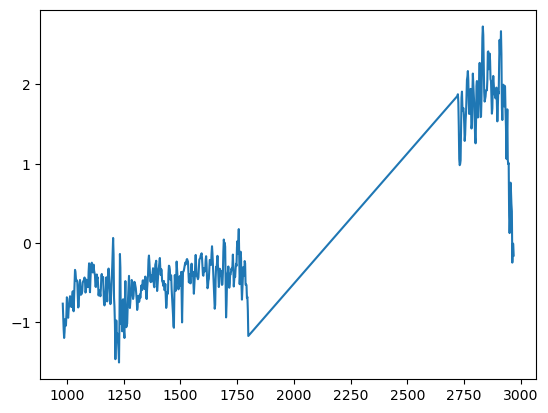

Prediction Set:  ['Polyethylene Terephthalate', 'Polystyrene']


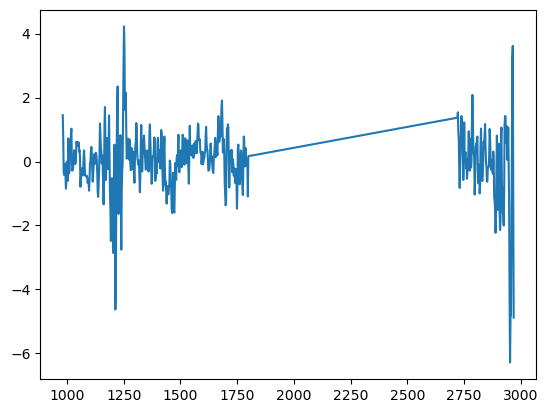

Prediction Set:  ['Cellulose Acetate', 'Polycarbonate']


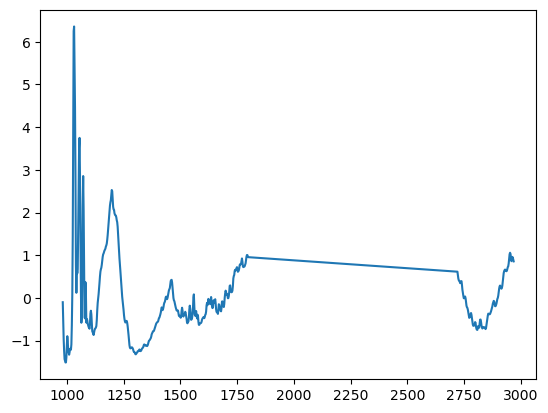

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2']


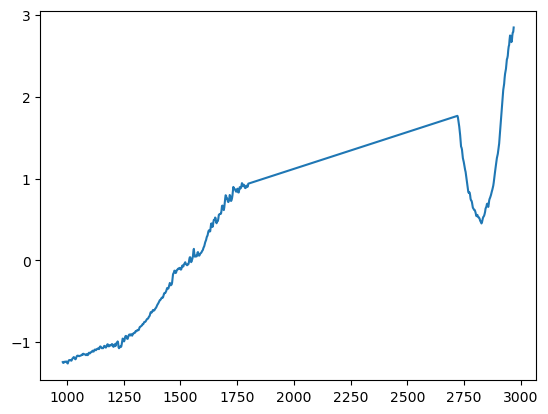

Prediction Set:  ['Acrylic', 'Polyurethane']


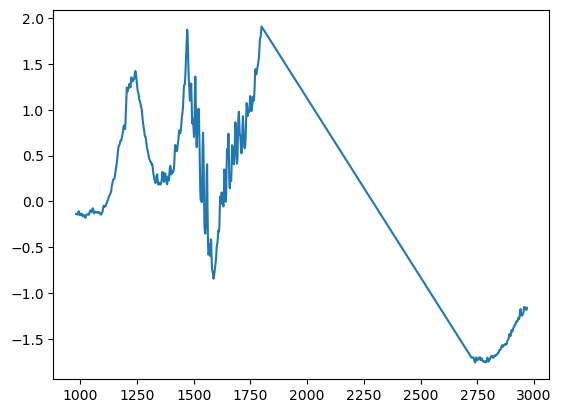

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2']


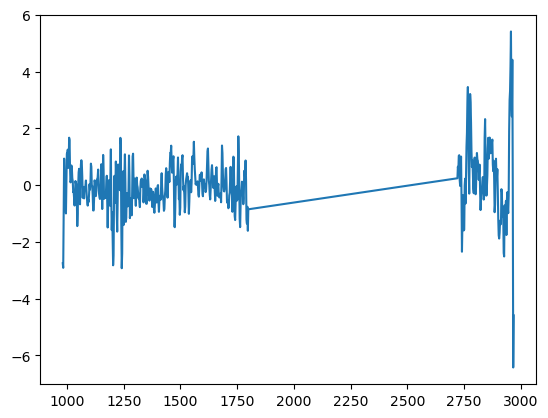

Prediction Set:  ['Magnesium Stearate v2', 'Polyvinyl Chloride', 'Zinc Stearate']


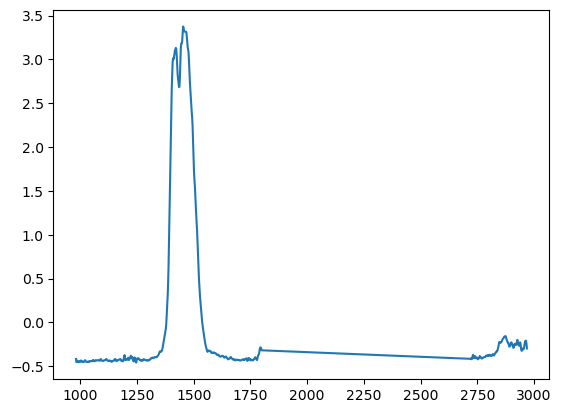

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Polypropylene', 'Rubber', 'Sodium Stearate', 'Zinc Stearate']


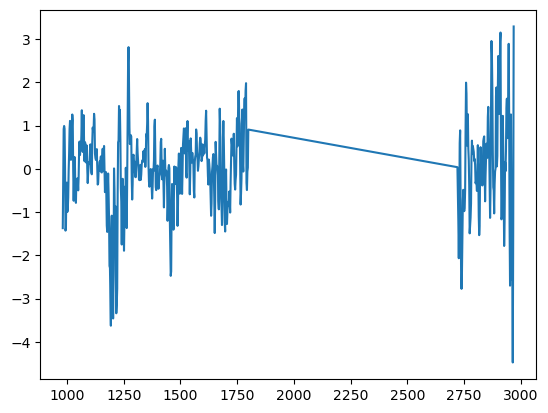

Prediction Set:  ['Polystyrene', 'Rubber']


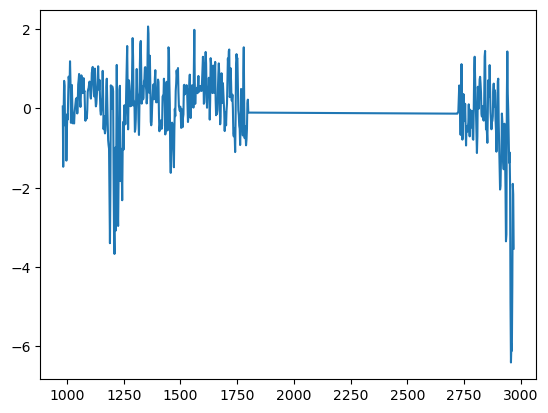

Prediction Set:  ['Calcium Stearate', 'Rubber', 'Zinc Stearate']


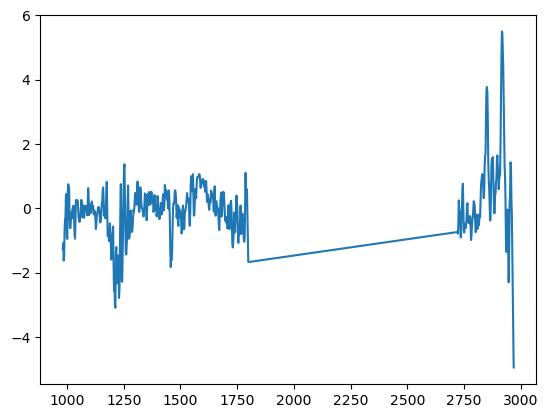

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Polypropylene']


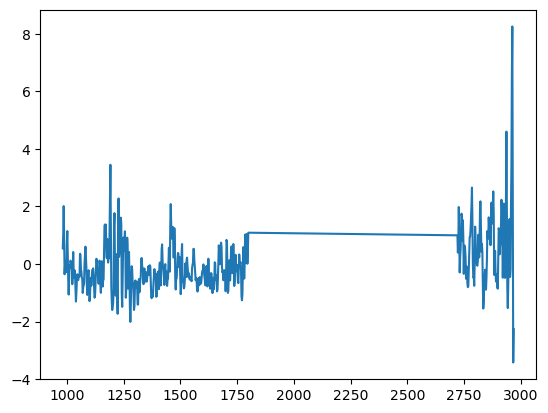

Prediction Set:  ['Magnesium Stearate v2', 'Polyethylene', 'Polypropylene', 'Rubber']


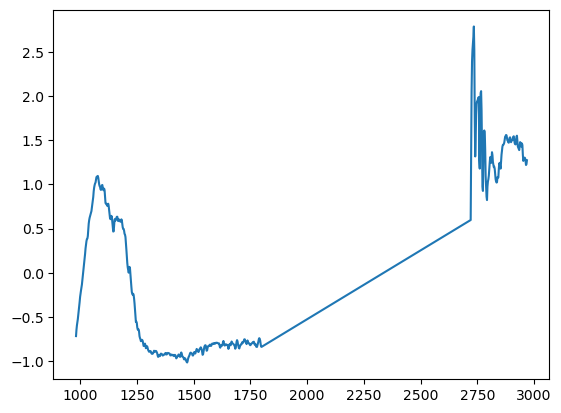

Prediction Set:  ['Calcium Stearate', 'Polyethylene', 'Rubber']


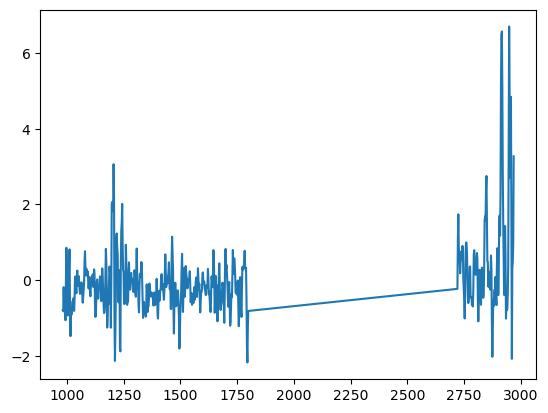

Prediction Set:  ['Polyethylene', 'Polystyrene', 'Polyurethane', 'Rubber']


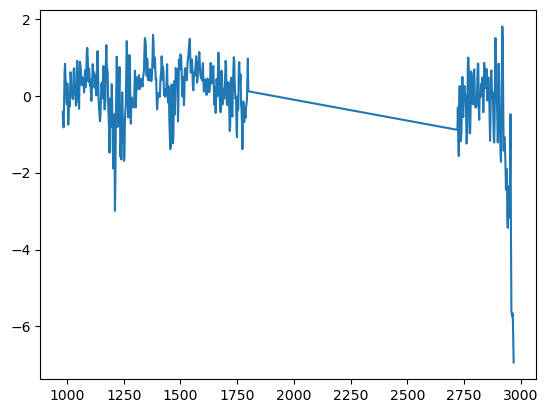

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Polypropylene']


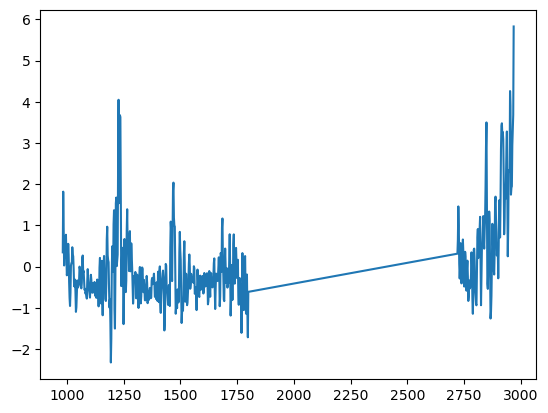

Prediction Set:  ['Calcium Stearate', 'Polyethylene', 'Rubber']


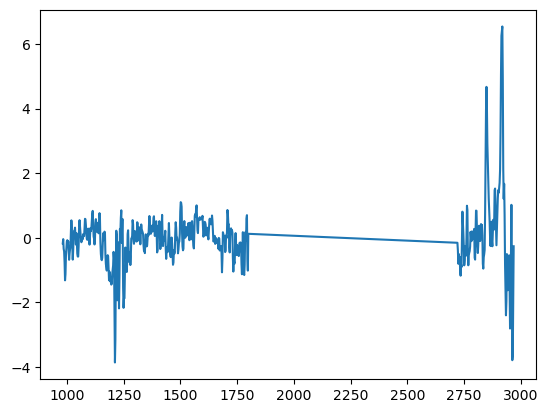

Prediction Set:  ['Polyethylene Vinyl Acetate', 'Zinc Stearate']


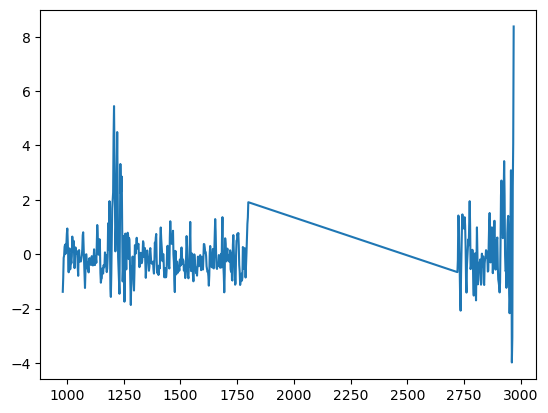

Prediction Set:  ['Calcium Stearate', 'Zinc Stearate']


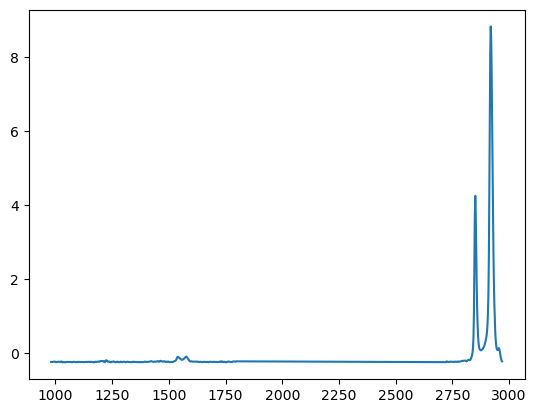

Prediction Set:  ['Calcium Stearate', 'Zinc Stearate']


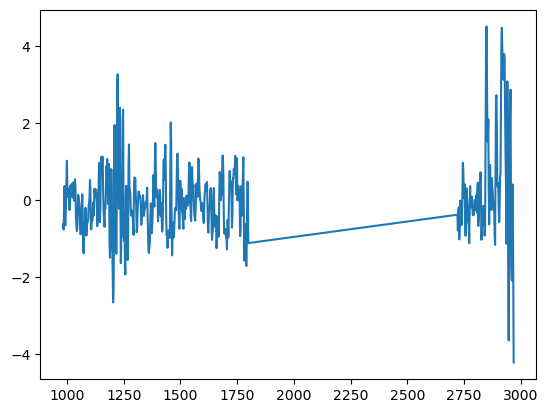

Prediction Set:  ['Calcium Stearate', 'Polyethylene', 'Rubber', 'Zinc Stearate']


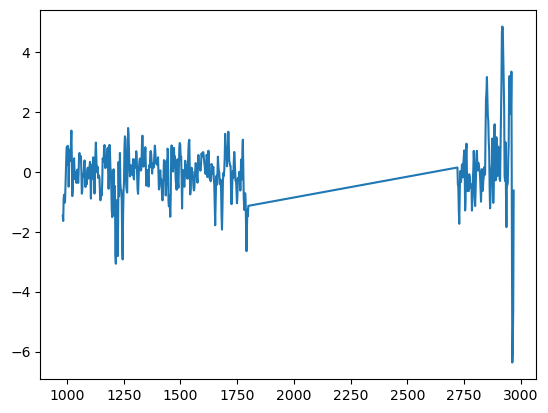

Prediction Set:  ['Polycarbonate', 'Polypropylene']


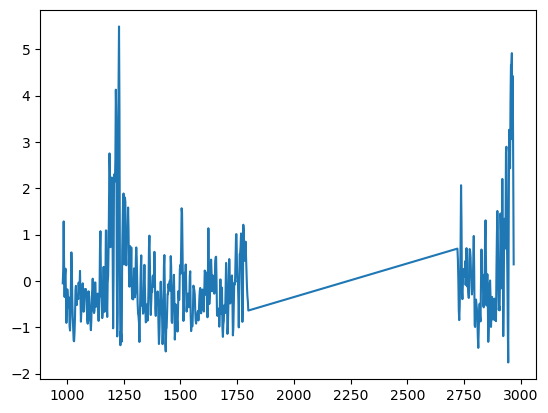

Prediction Set:  ['Polypropylene', 'Polystyrene']


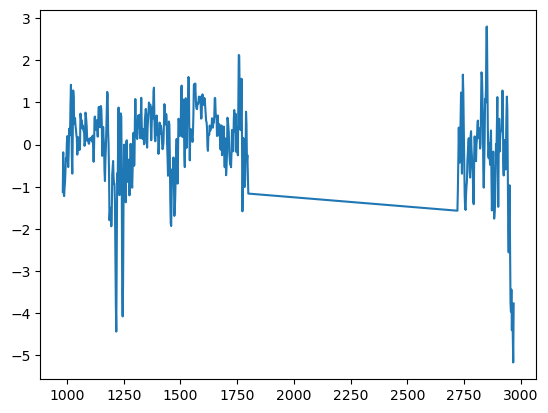

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Zinc Stearate']


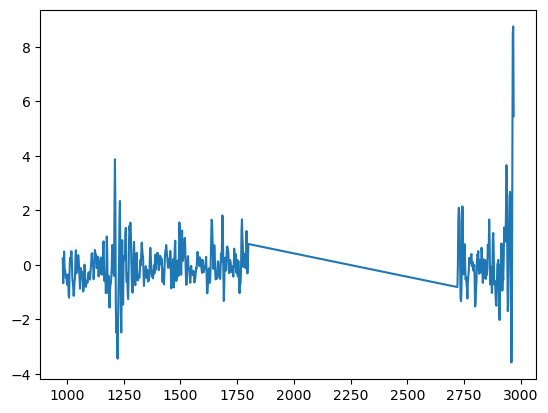

Prediction Set:  ['Acrylonitrile Butadiene Styrene', 'Polyamide', 'Polyethylene', 'Polystyrene', 'Rubber']


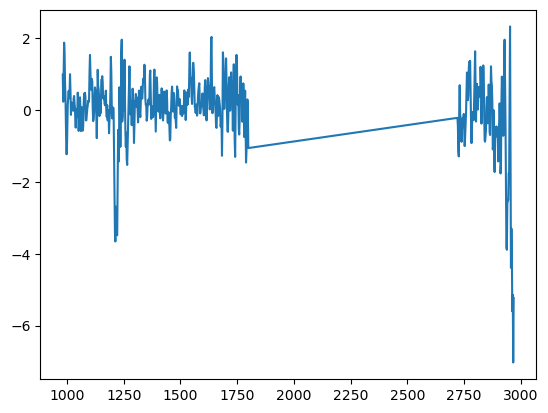

Prediction Set:  ['Polyethylene', 'Polystyrene', 'Rubber']


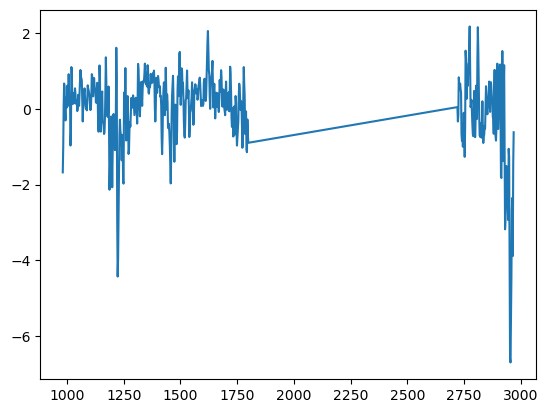

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


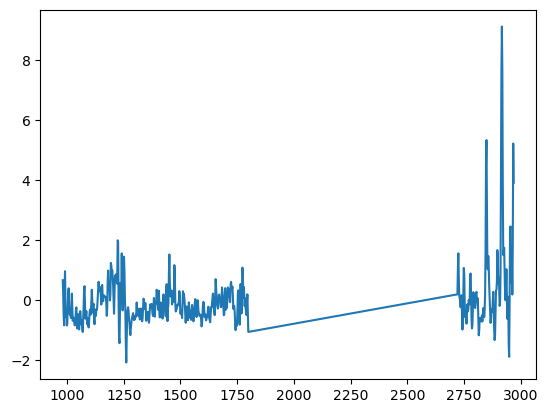

Prediction Set:  ['Calcium Stearate', 'Polypropylene']


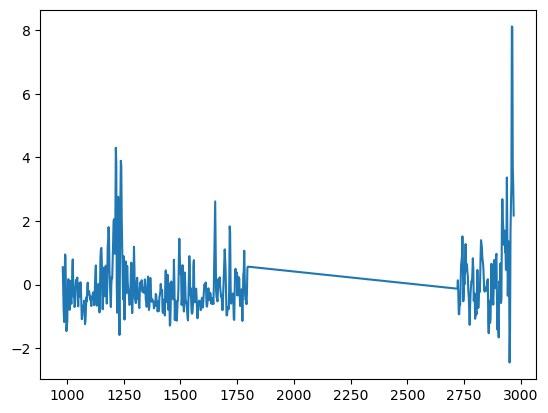

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2']


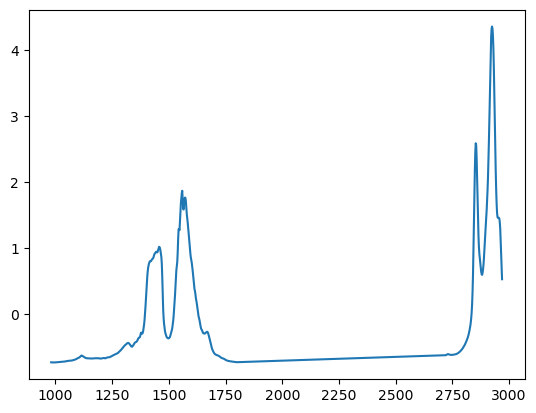

Prediction Set:  ['Calcium Stearate', 'Rubber']


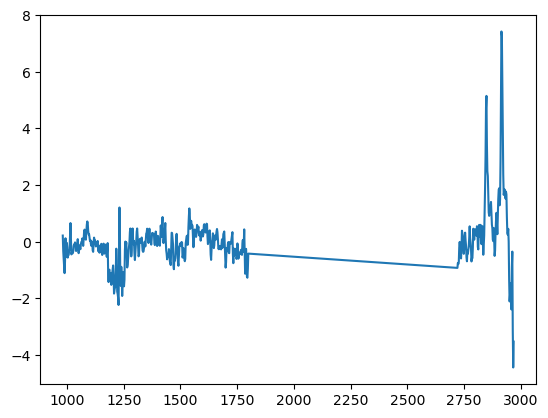

Prediction Set:  ['Calcium Stearate', 'Zinc Stearate']


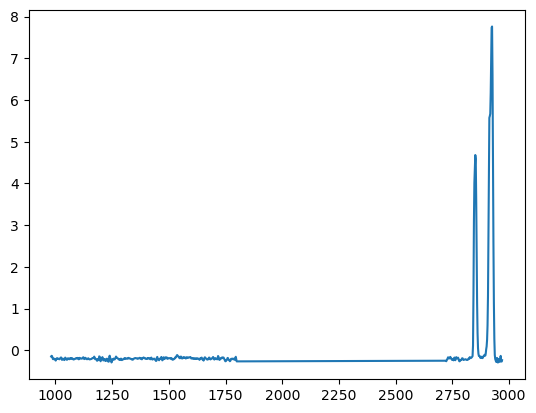

Prediction Set:  ['Polypropylene', 'Polystyrene', 'Rubber']


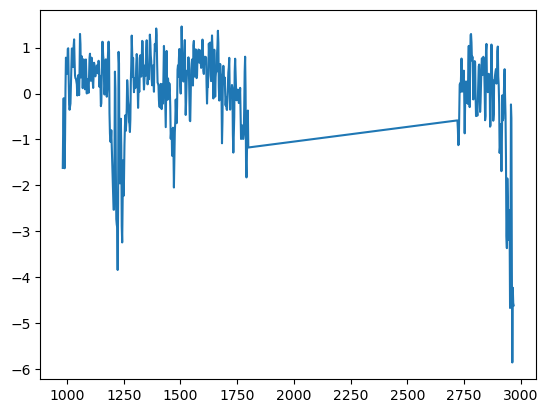

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Zinc Stearate']


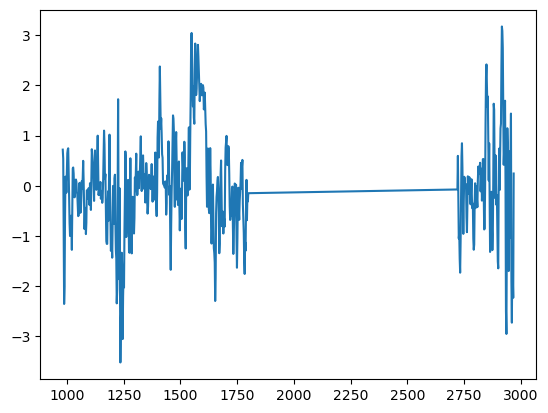

Prediction Set:  ['Calcium Stearate', 'Polyethylene', 'Rubber']


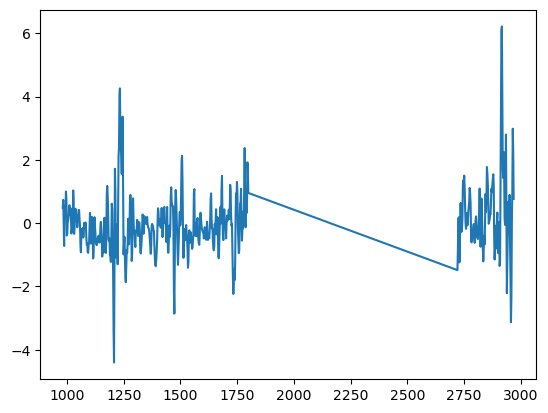

Prediction Set:  ['Polyethylene', 'Rubber']


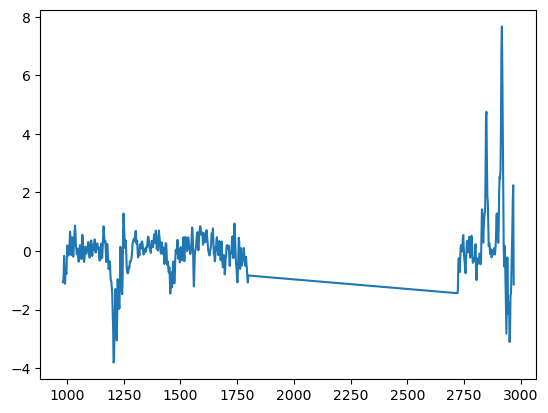

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Polypropylene']


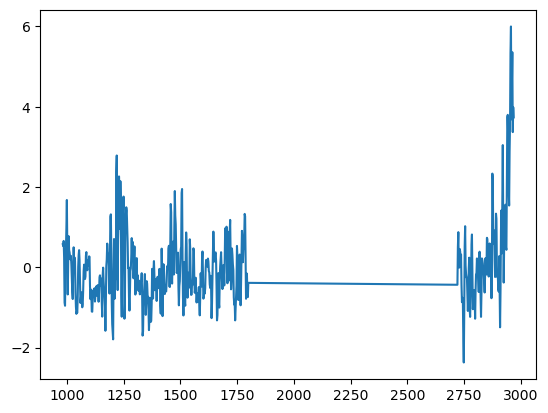

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Polypropylene']


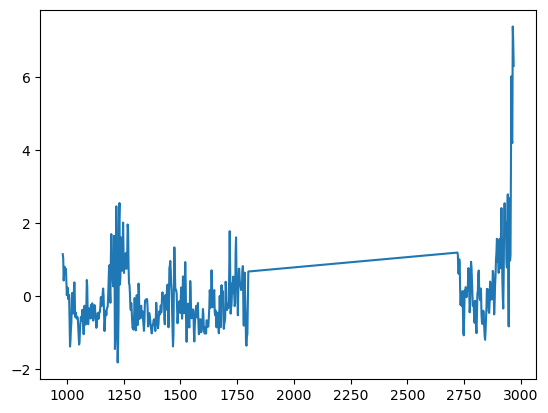

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


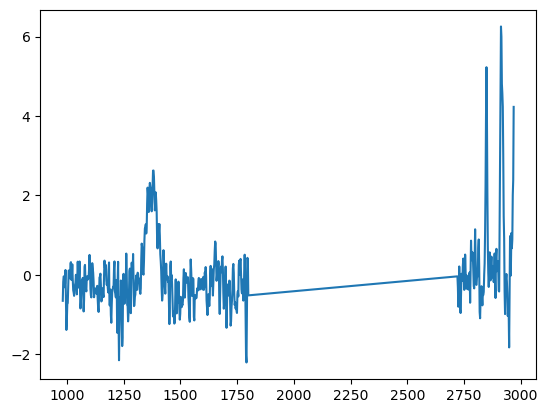

Prediction Set:  ['Calcium Stearate', 'Rubber']


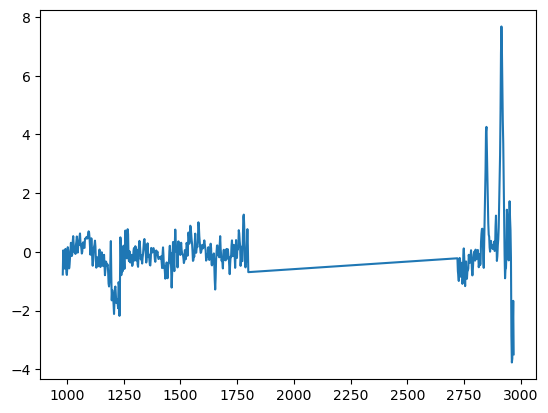

Prediction Set:  ['Polyethylene', 'Polystyrene', 'Polyurethane', 'Zinc Stearate']


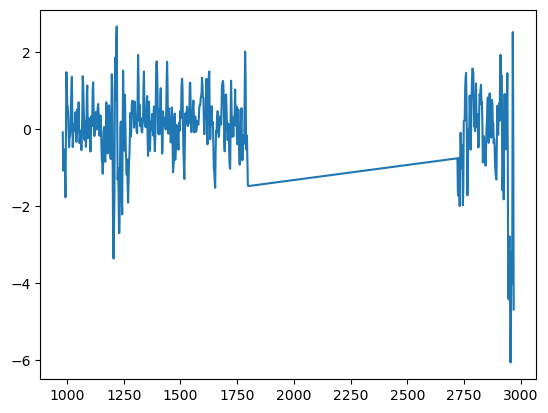

Prediction Set:  ['Calcium Stearate', 'Sodium Stearate']


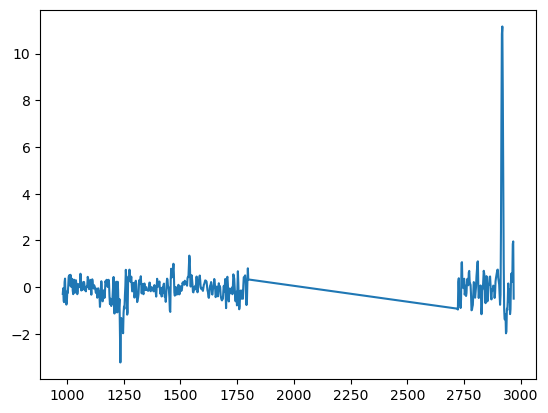

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


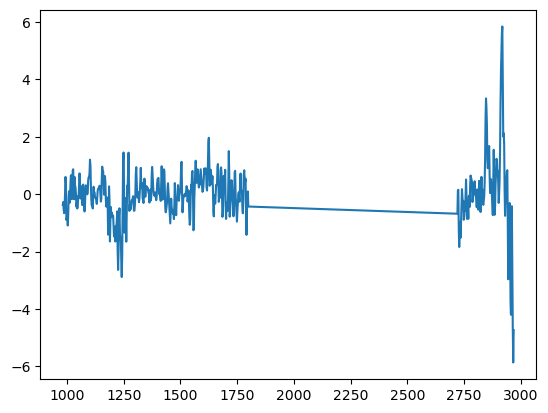

Prediction Set:  ['Polypropylene', 'Rubber']


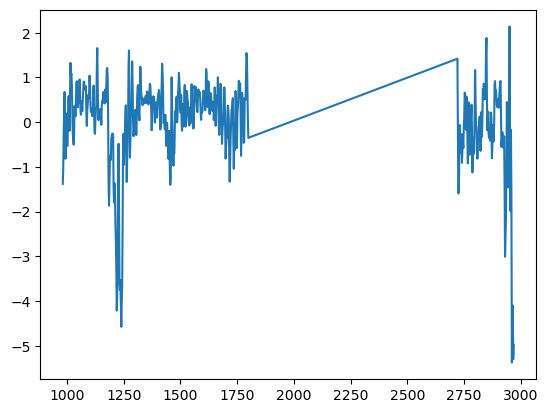

Prediction Set:  ['Calcium Stearate', 'Polyethylene', 'Zinc Stearate']


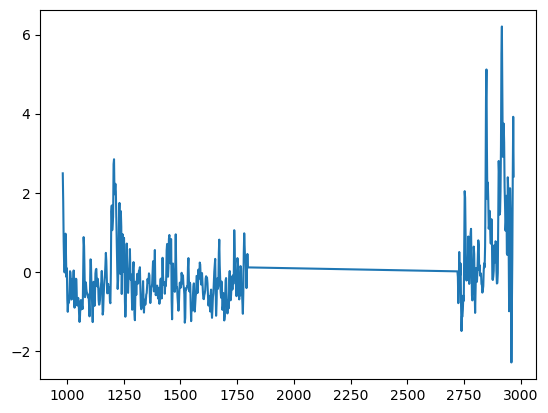

Prediction Set:  ['Magnesium Stearate v2', 'Polyethylene']


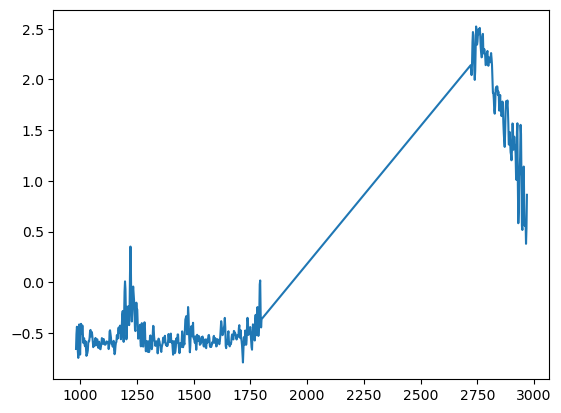

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Polypropylene', 'Polystyrene', 'Rubber', 'Sodium Stearate', 'Zinc Stearate']


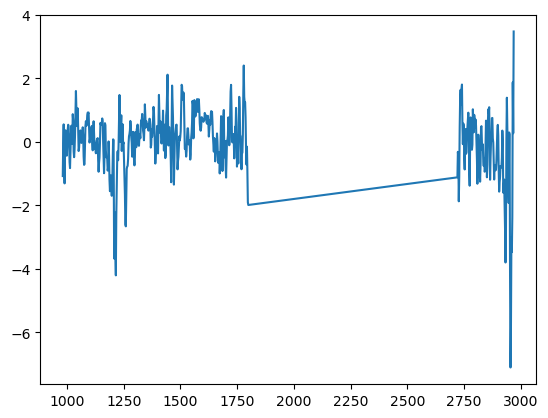

Prediction Set:  ['Polyethylene Vinyl Acetate', 'Polypropylene']


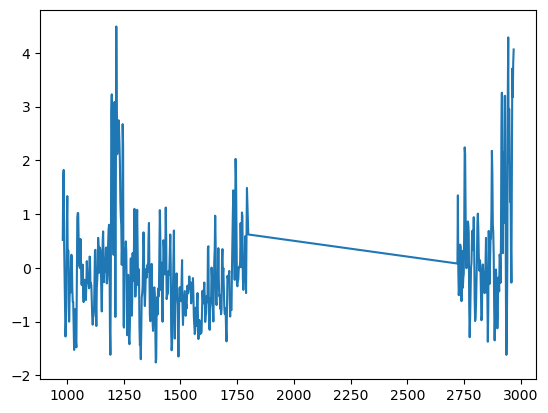

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Zinc Stearate']


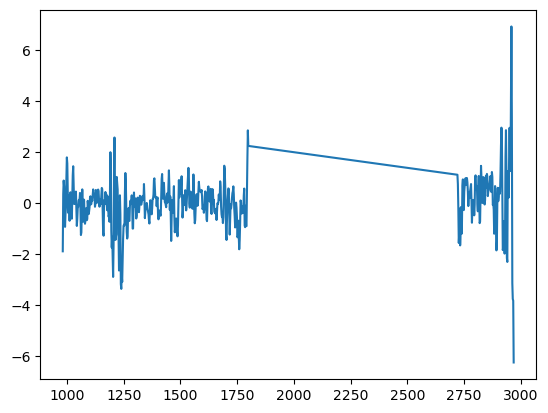

Prediction Set:  ['Calcium Stearate', 'Polyethylene', 'Polypropylene', 'Zinc Stearate']


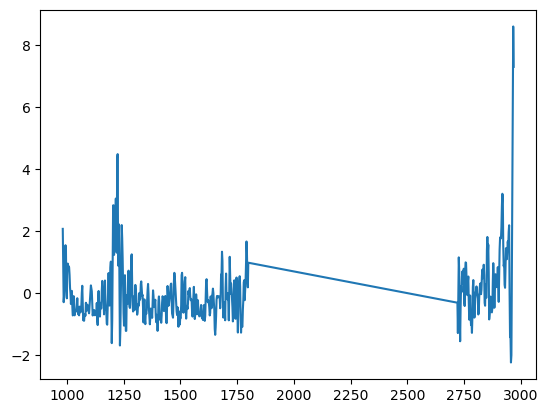

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


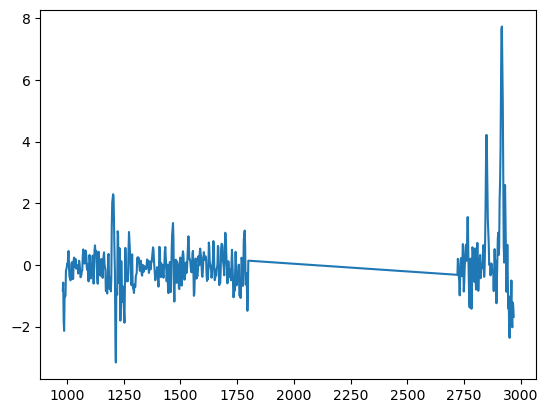

Prediction Set:  ['Polypropylene', 'Zinc Stearate']


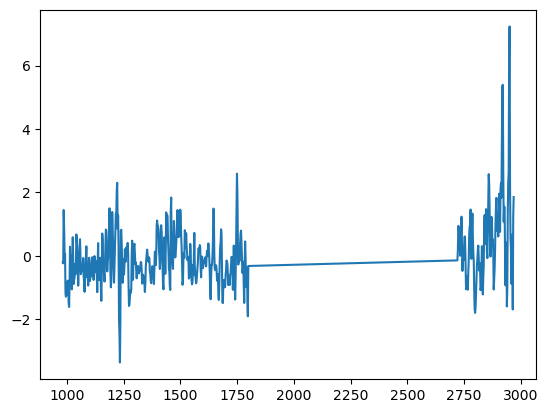

Prediction Set:  ['Magnesium Stearate v2', 'Sodium Stearate']


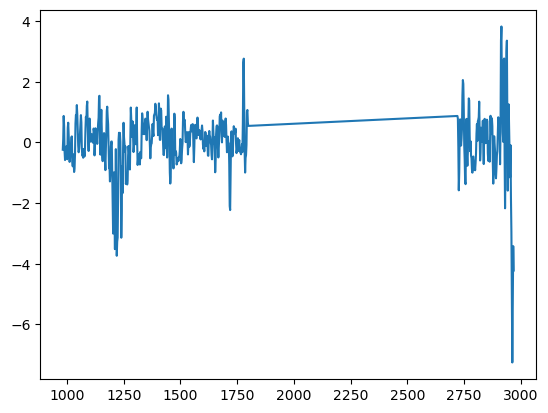

Prediction Set:  ['Polyethylene', 'Sodium Stearate']


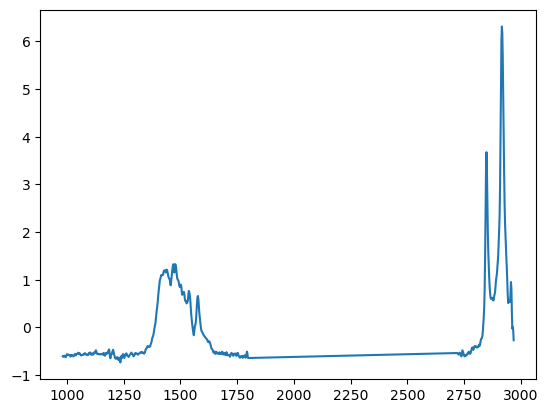

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Sodium Stearate']


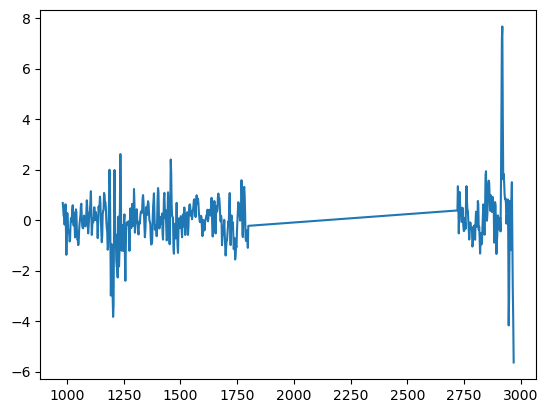

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


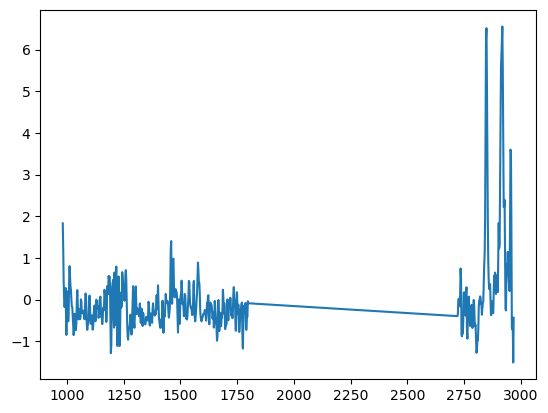

Prediction Set:  ['Polystyrene', 'Rubber']


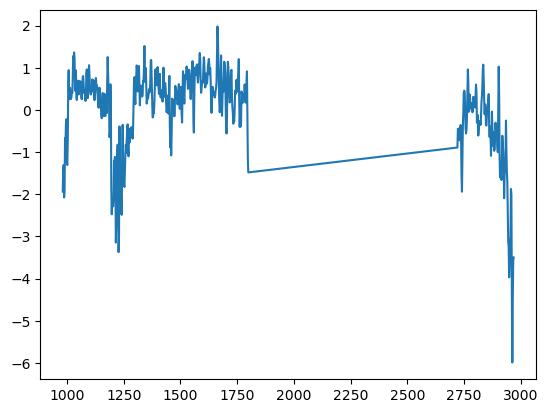

Prediction Set:  ['Magnesium Stearate v2', 'Zinc Stearate']


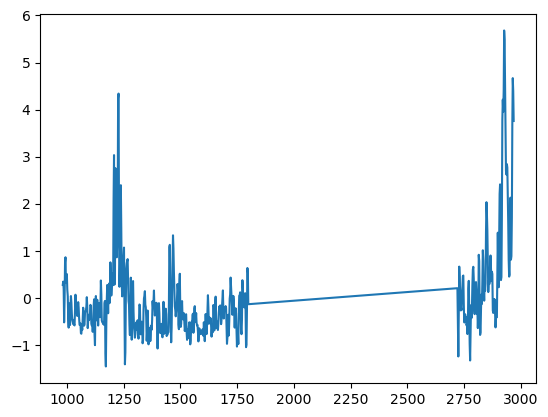

Prediction Set:  ['Polyethylene', 'Polyethylene Vinyl Acetate']


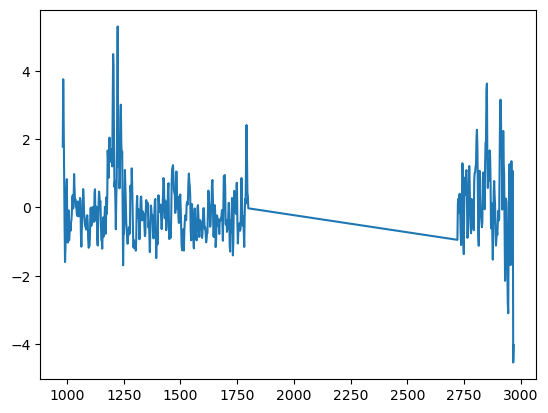

Prediction Set:  ['Polyethylene', 'Polystyrene', 'Zinc Stearate']


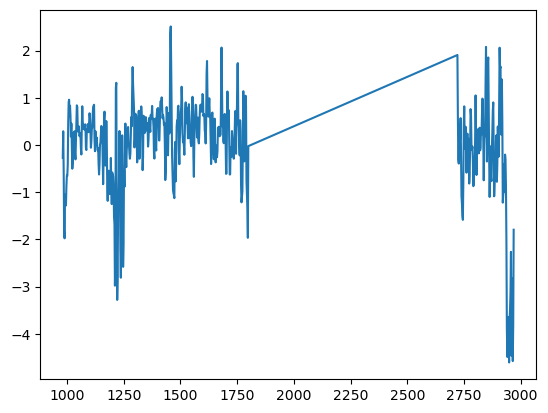

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


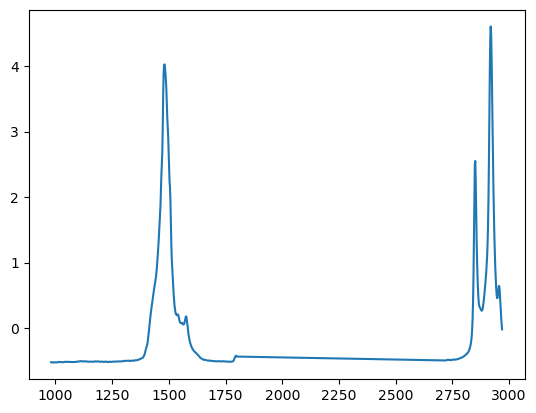

Prediction Set:  ['Polyethylene', 'Polypropylene', 'Polystyrene', 'Rubber']


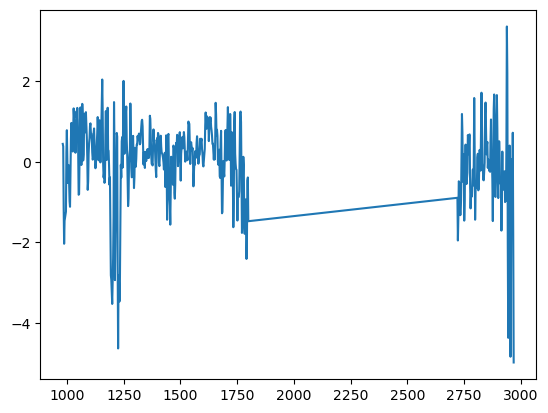

Prediction Set:  ['Calcium Stearate', 'Polypropylene']


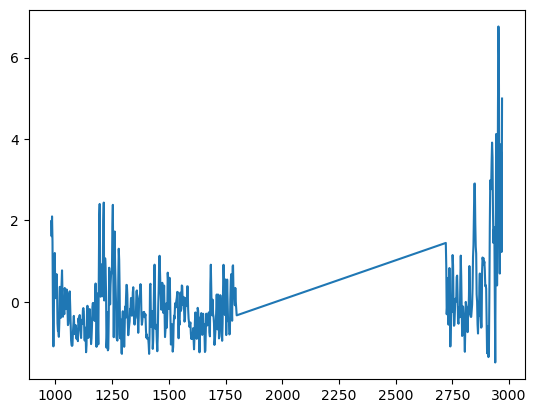

Prediction Set:  ['Magnesium Stearate v2', 'Polyvinyl Chloride']


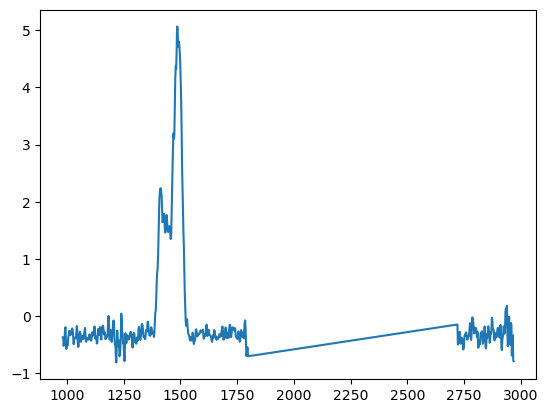

Prediction Set:  ['Calcium Stearate', 'Zinc Stearate']


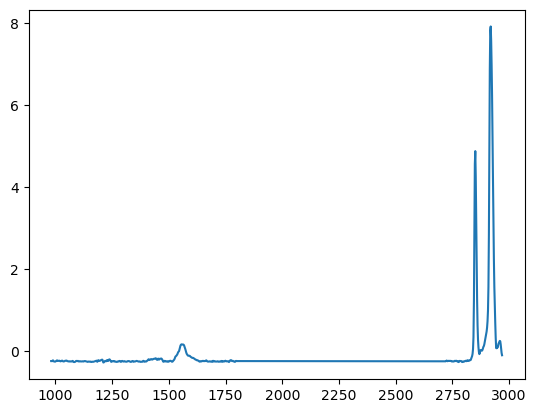

Prediction Set:  ['Calcium Stearate', 'Polypropylene', 'Zinc Stearate']


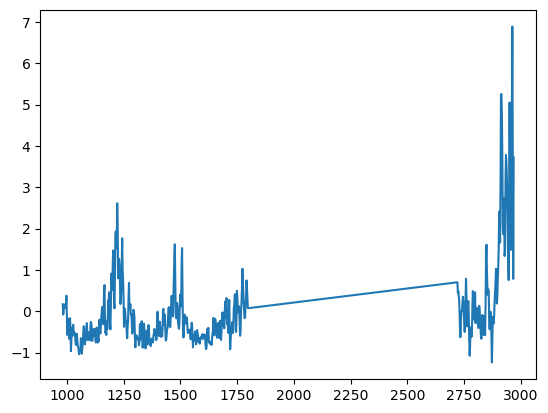

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


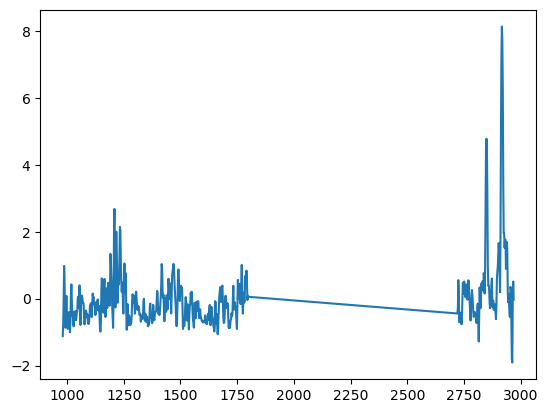

Prediction Set:  ['Magnesium Stearate v2', 'Polycarbonate', 'Polypropylene']


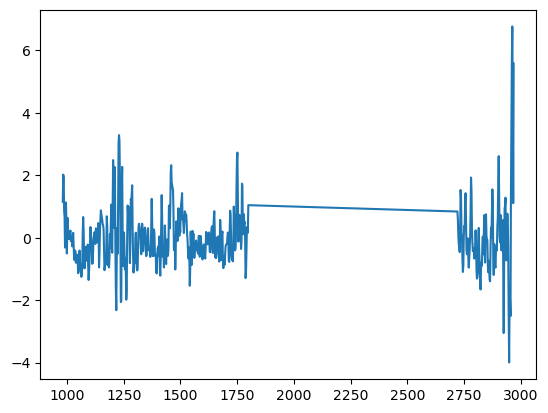

Prediction Set:  ['Calcium Stearate', 'Rubber']


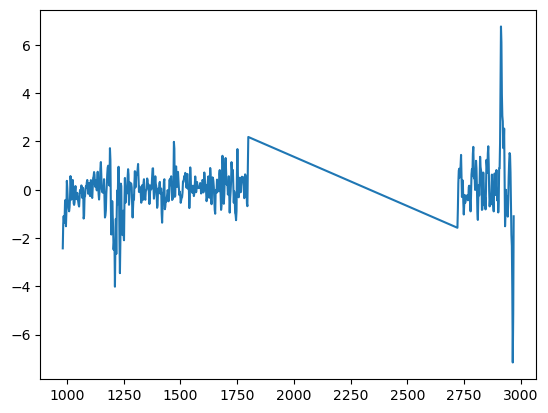

Prediction Set:  ['Polyethylene', 'Polypropylene', 'Polystyrene', 'Rubber']


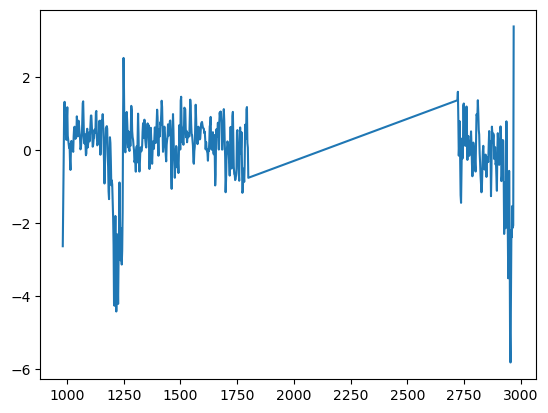

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


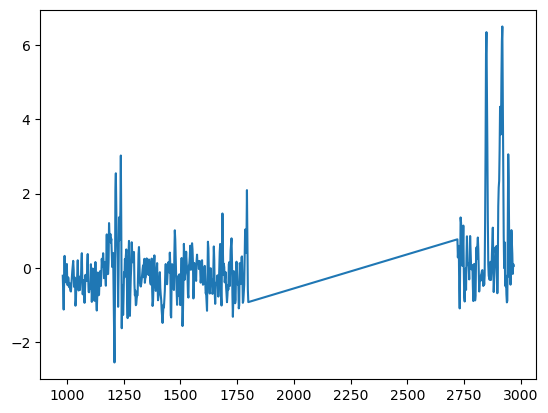

Prediction Set:  ['Calcium Stearate', 'Polyethylene', 'Polypropylene', 'Rubber']


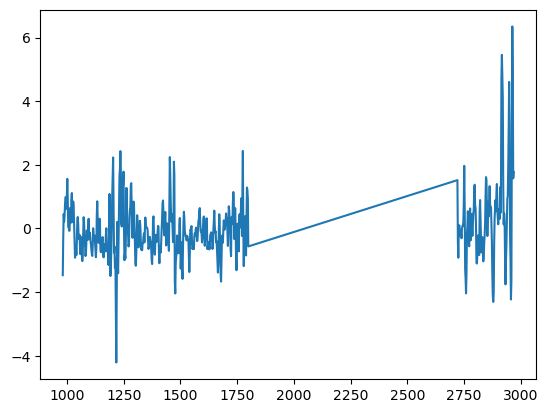

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Polypropylene']


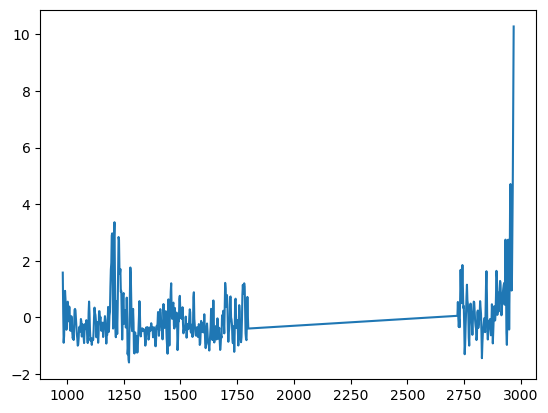

Prediction Set:  ['Calcium Stearate', 'Zinc Stearate']


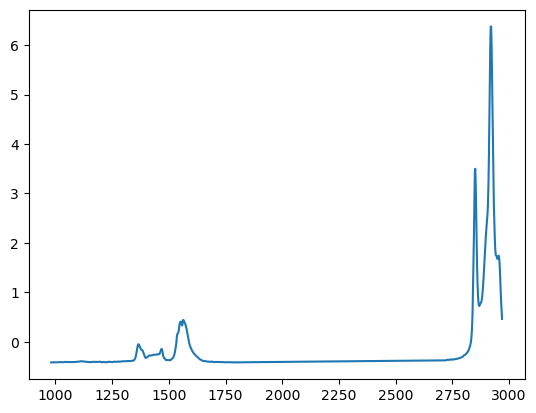

Prediction Set:  ['Magnesium Stearate v2', 'Polypropylene']


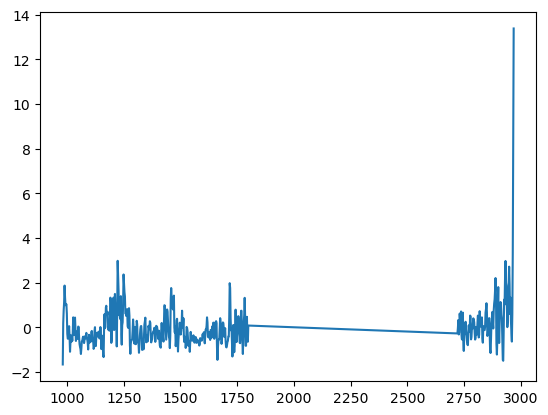

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


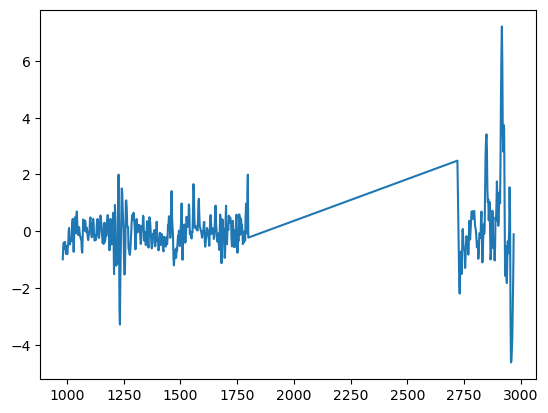

Prediction Set:  ['Calcium Stearate', 'Polyethylene', 'Rubber']


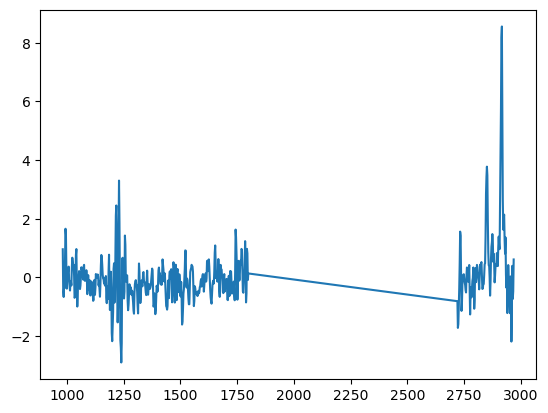

Prediction Set:  ['Calcium Stearate', 'Rubber', 'Sodium Stearate', 'Zinc Stearate']


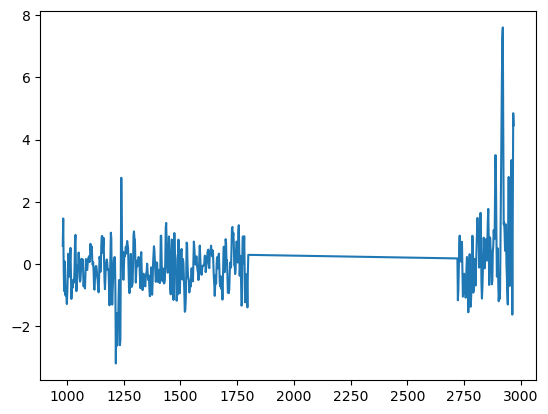

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Zinc Stearate']


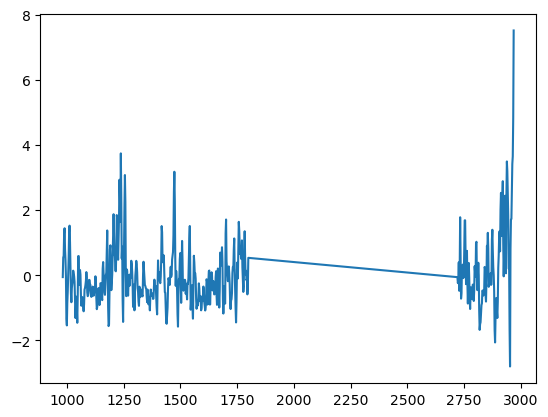

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


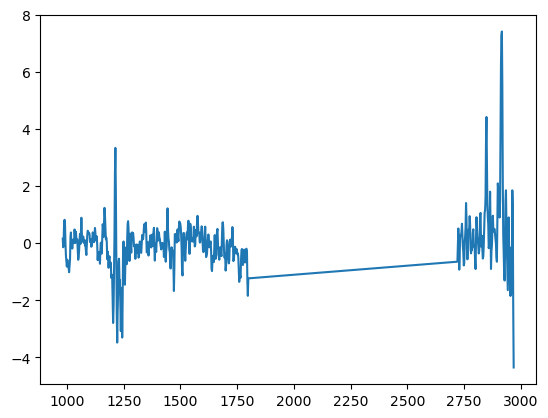

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


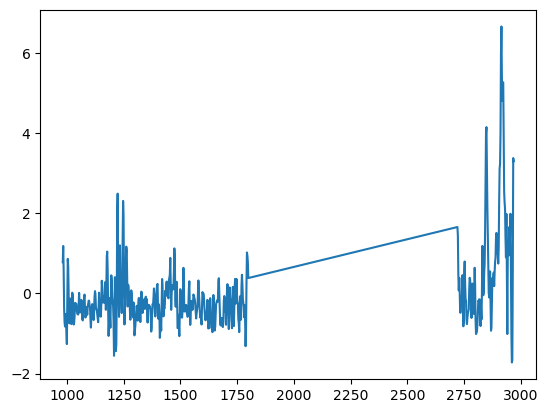

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


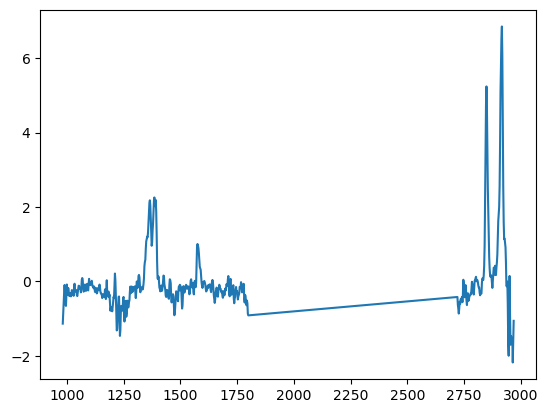

Prediction Set:  ['Polyethylene Terephthalate', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride']


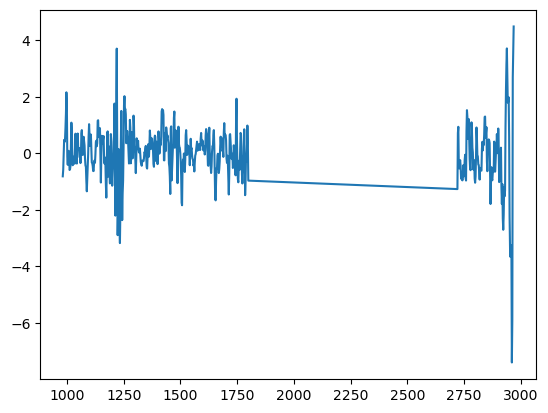

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Polypropylene']


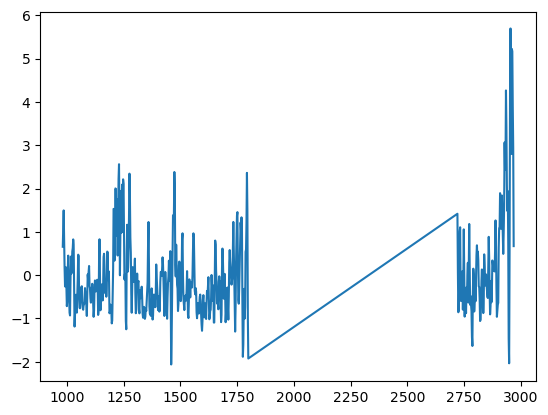

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Polyamide', 'Polyethylene', 'Polypropylene', 'Sodium Stearate', 'Zinc Stearate']


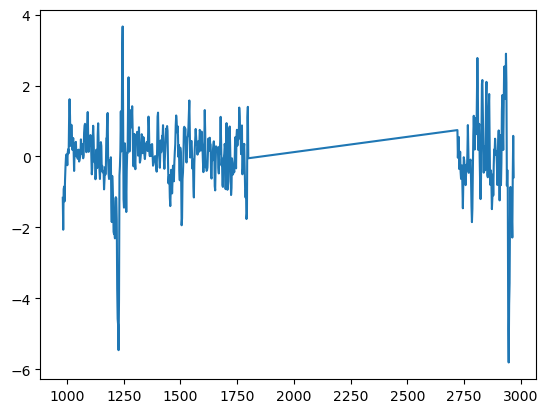

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Polypropylene']


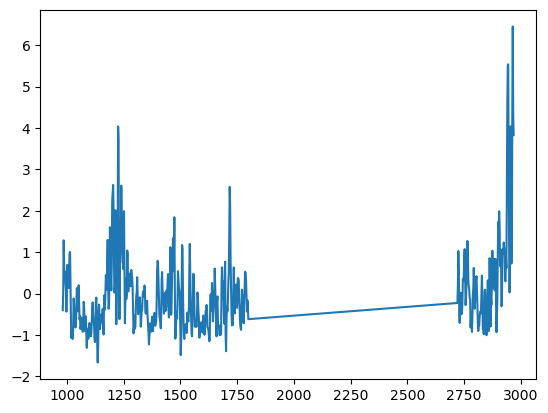

Prediction Set:  ['Calcium Stearate', 'Rubber']


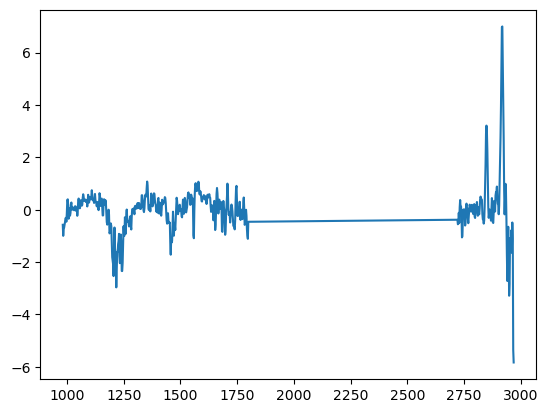

Prediction Set:  ['Calcium Stearate', 'Polyethylene', 'Rubber']


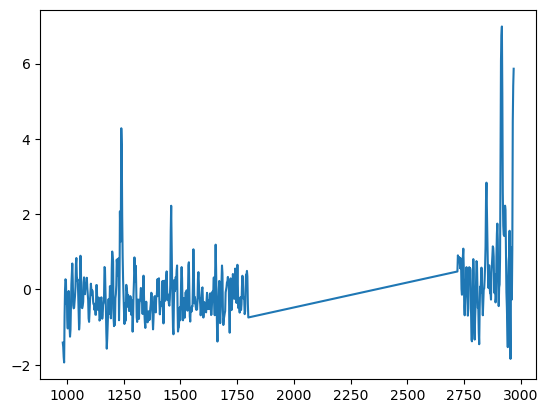

Prediction Set:  ['Polycarbonate', 'Polyethylene Terephthalate']


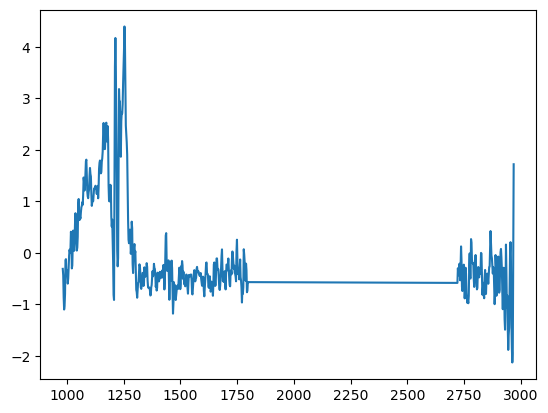

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2']


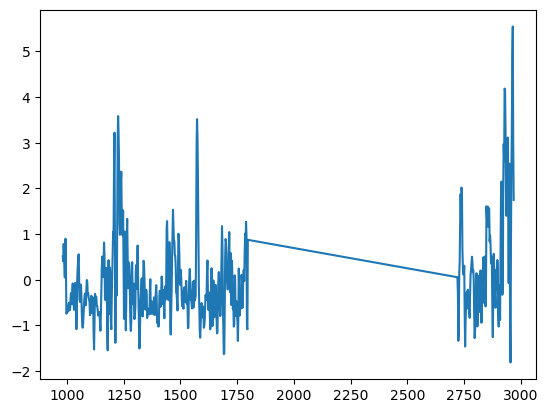

Prediction Set:  ['Polypropylene', 'Polystyrene', 'Polyurethane', 'Rubber']


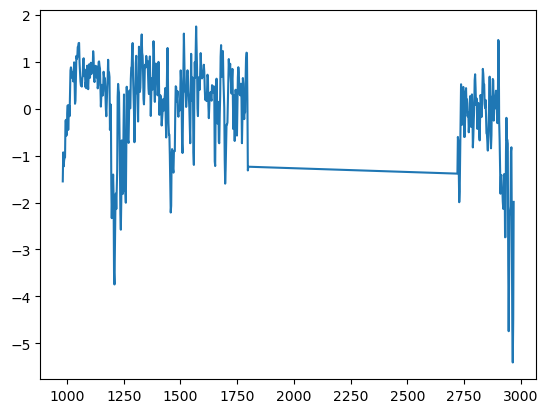

Prediction Set:  ['Acrylonitrile Butadiene Styrene', 'Polyethylene', 'Polystyrene', 'Rubber']


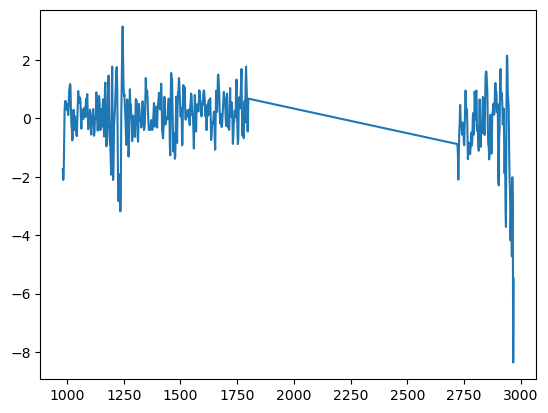

Prediction Set:  ['Calcium Stearate', 'Zinc Stearate']


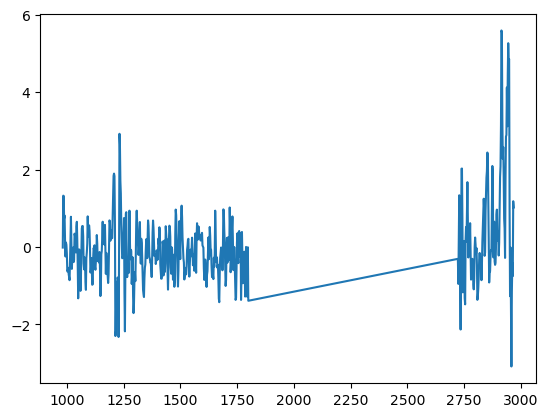

Prediction Set:  ['Polystyrene', 'Polyurethane', 'Rubber']


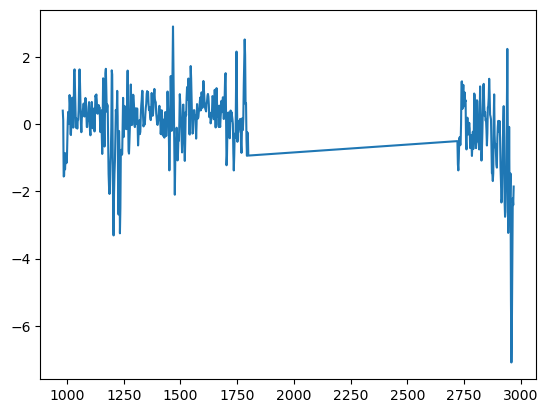

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2']


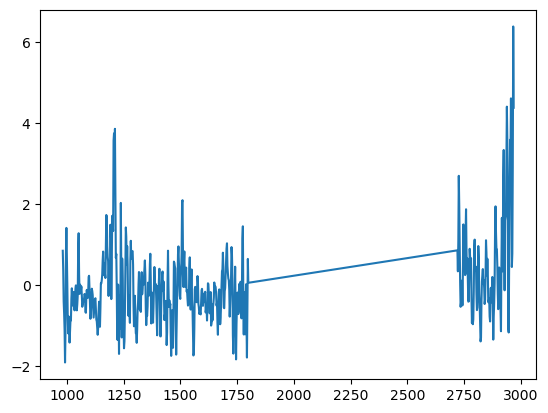

Prediction Set:  ['Polycarbonate', 'Polyethylene Vinyl Acetate', 'Polypropylene']


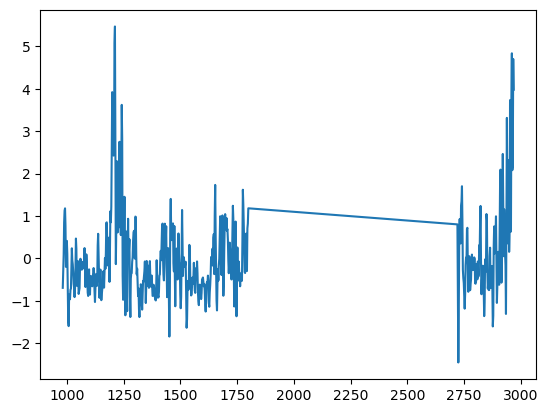

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Polyethylene Adipate', 'Polypropylene', 'Zinc Stearate']


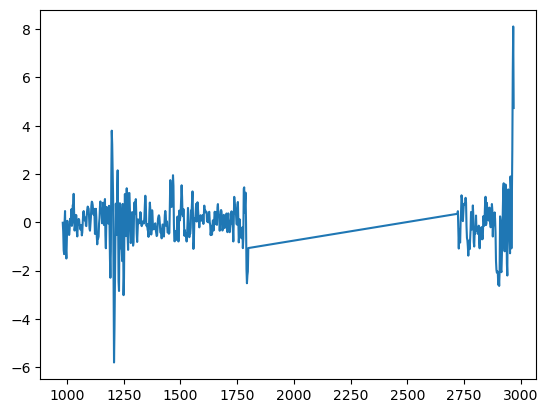

Prediction Set:  ['Polyamide', 'Polystyrene', 'Polyurethane', 'Rubber', 'Silicone Rubber', 'Sodium Stearate']


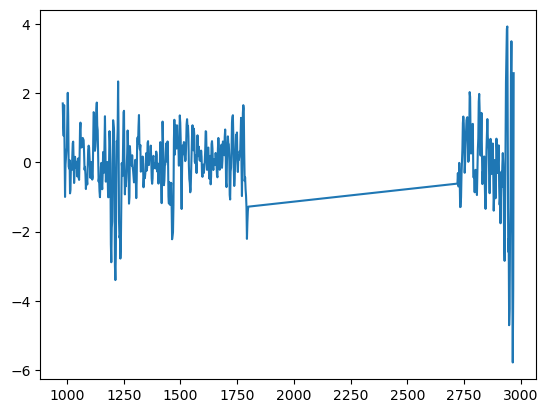

Prediction Set:  ['Polyethylene', 'Polypropylene', 'Polystyrene', 'Rubber']


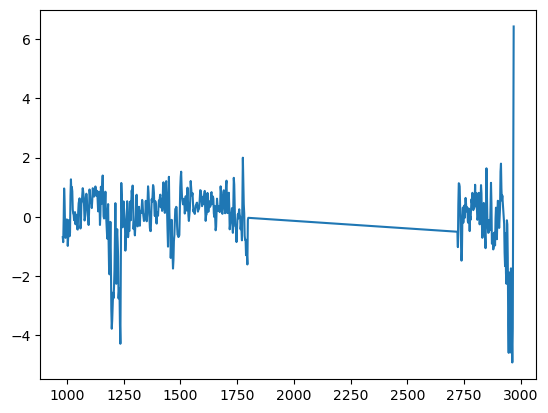

Prediction Set:  ['Polyethylene', 'Polystyrene', 'Polyurethane', 'Rubber']


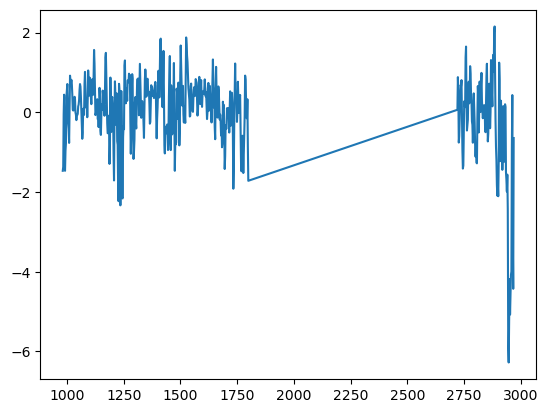

Prediction Set:  ['Polypropylene', 'Polystyrene', 'Rubber']


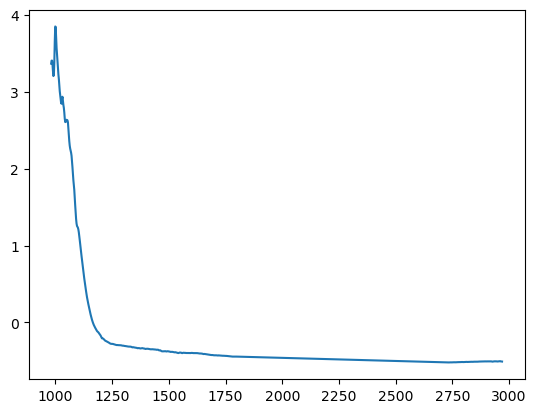

Prediction Set:  ['Polystyrene', 'Rubber']


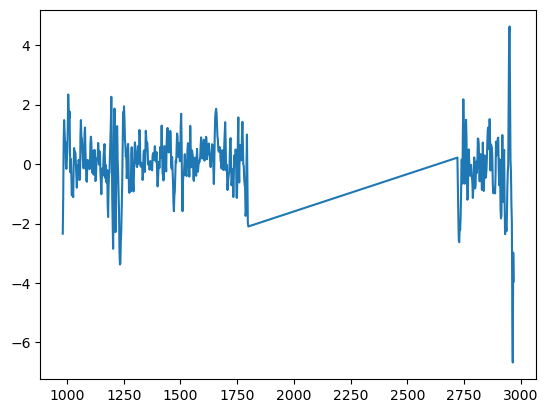

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


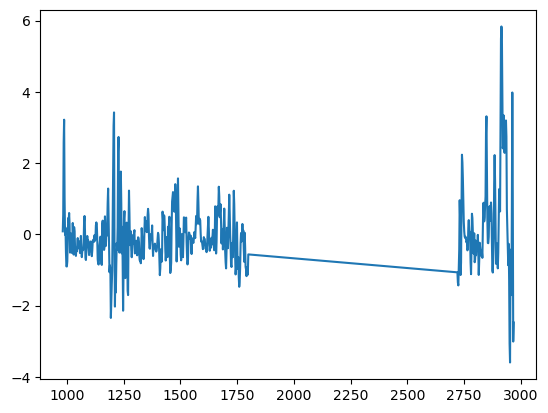

Prediction Set:  ['Calcium Stearate', 'Zinc Stearate']


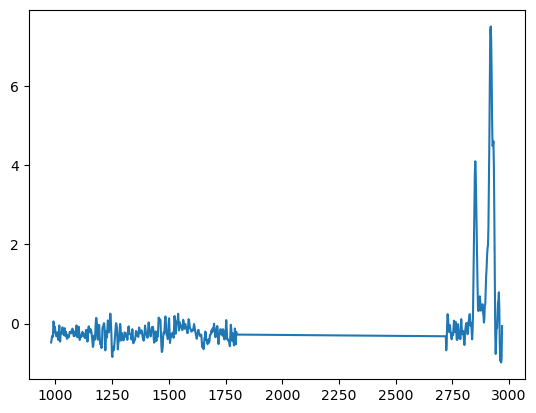

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


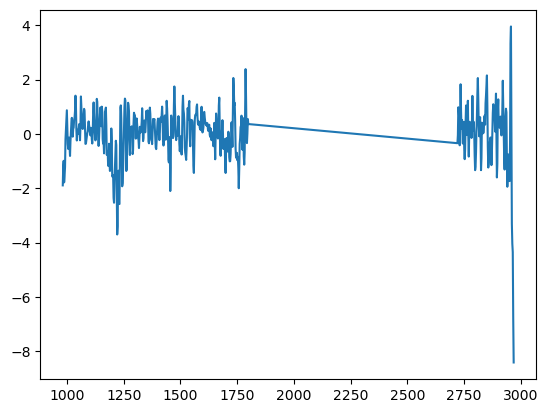

Prediction Set:  ['Calcium Stearate', 'Polyurethane']


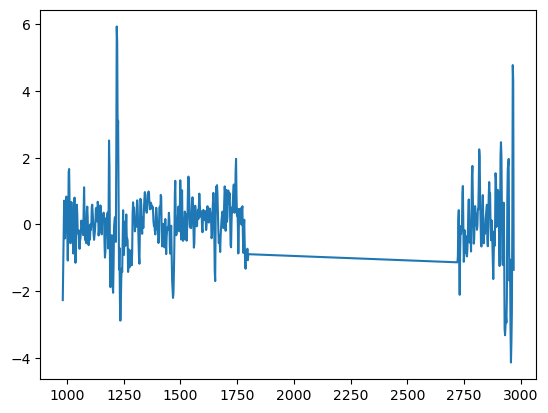

Prediction Set:  ['Calcium Stearate', 'Rubber']


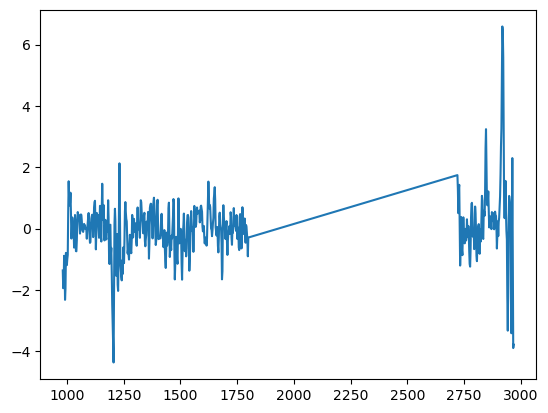

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


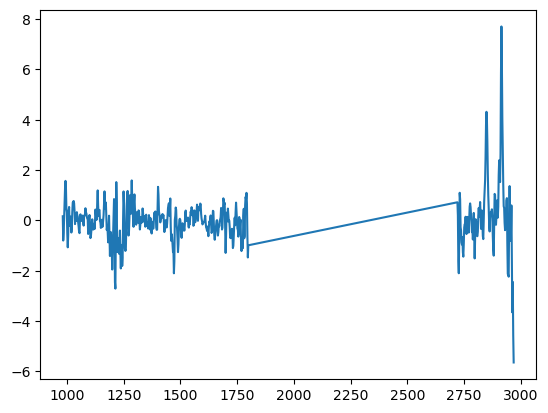

Prediction Set:  ['Calcium Stearate', 'Polypropylene', 'Polystyrene']


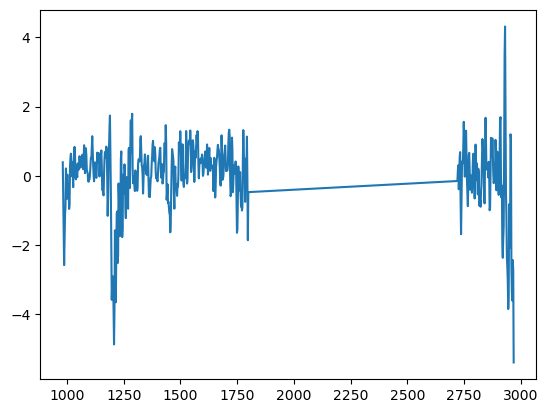

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2']


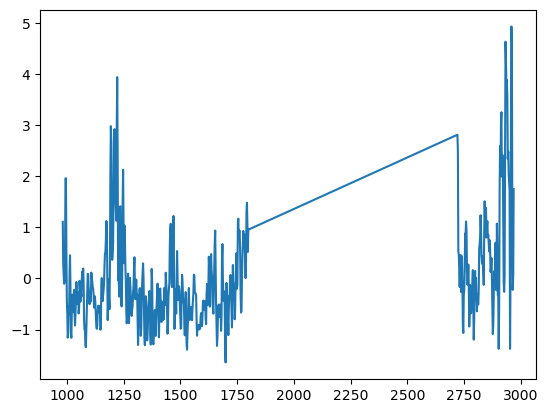

Prediction Set:  ['Acrylonitrile Butadiene Styrene', 'Polyethylene', 'Polystyrene', 'Polyurethane', 'Rubber']


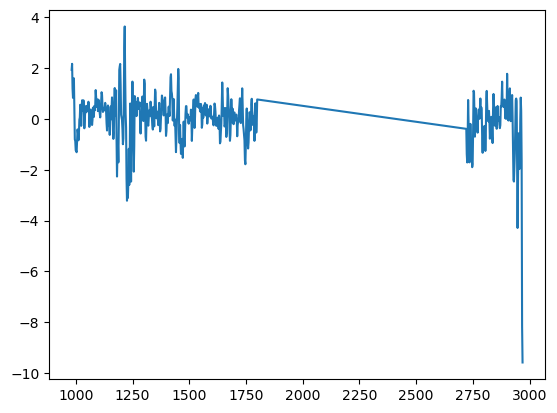

Prediction Set:  ['Calcium Stearate', 'Polyethylene', 'Polyethylene Vinyl Acetate']


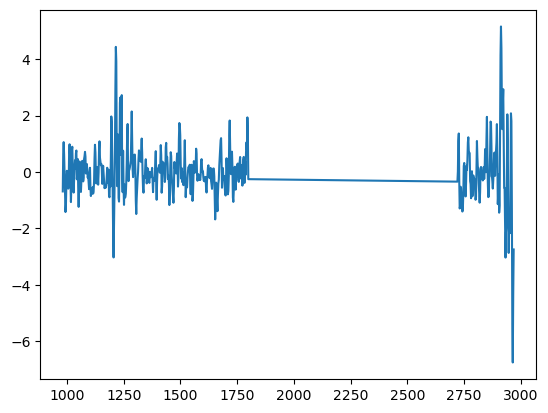

Prediction Set:  ['Polypropylene', 'Polystyrene', 'Rubber']


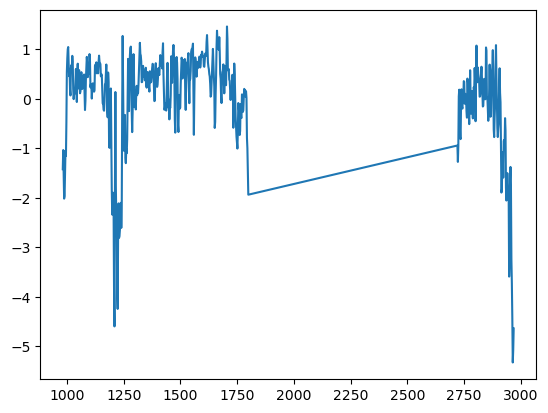

Prediction Set:  ['Magnesium Stearate v2', 'Polypropylene', 'Rubber']


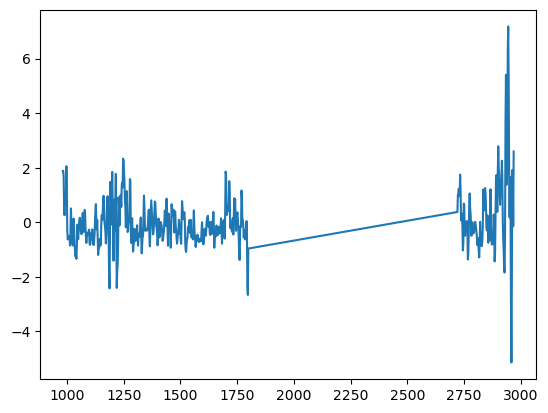

Prediction Set:  ['Calcium Stearate', 'Zinc Stearate']


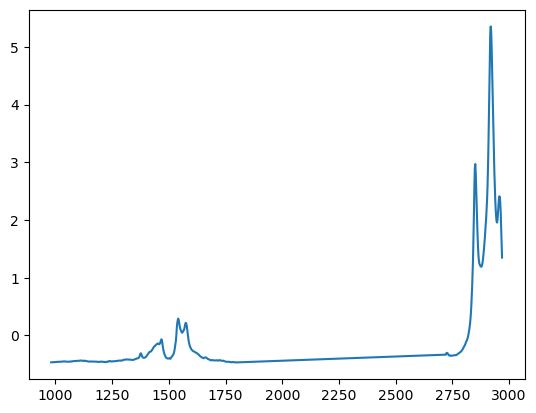

Prediction Set:  ['Magnesium Stearate v2', 'Polyvinyl Chloride']


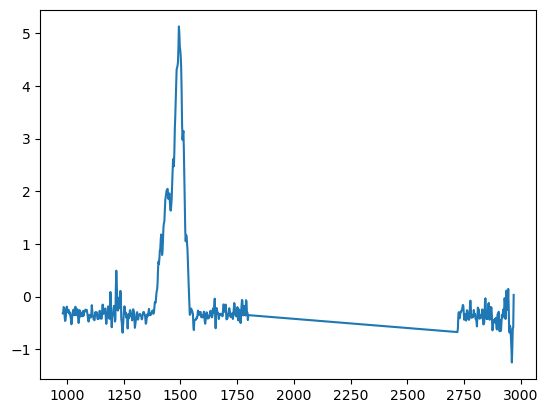

Prediction Set:  ['Polypropylene', 'Polystyrene', 'Rubber']


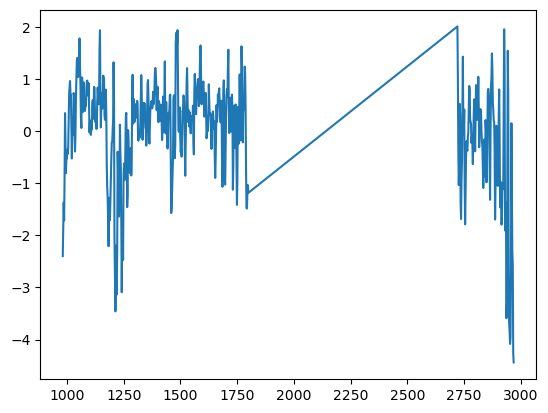

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Polypropylene', 'Zinc Stearate']


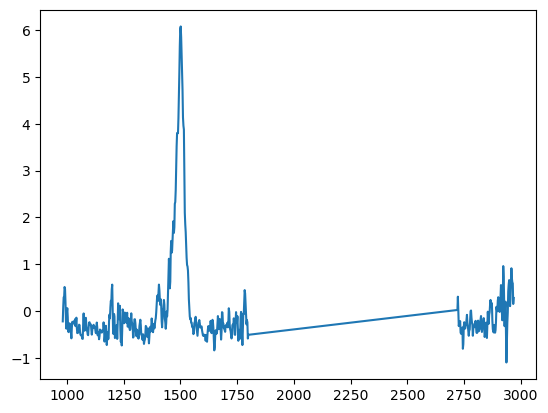

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Polycarbonate', 'Polyethylene Adipate', 'Polyethylene Vinyl Acetate', 'Polypropylene']


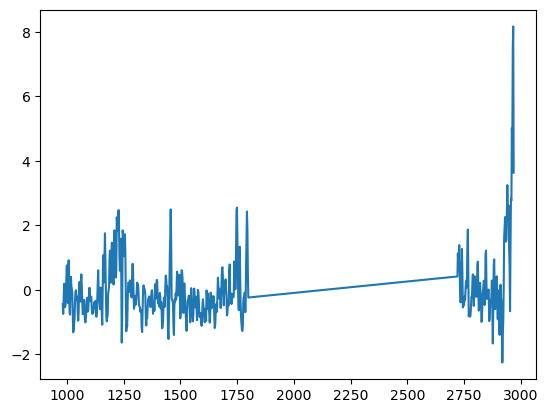

Prediction Set:  ['Polystyrene', 'Polyvinyl Chloride']


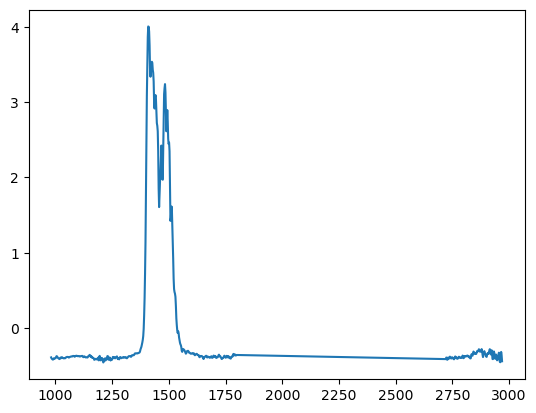

Prediction Set:  ['Polystyrene', 'Zinc Stearate']


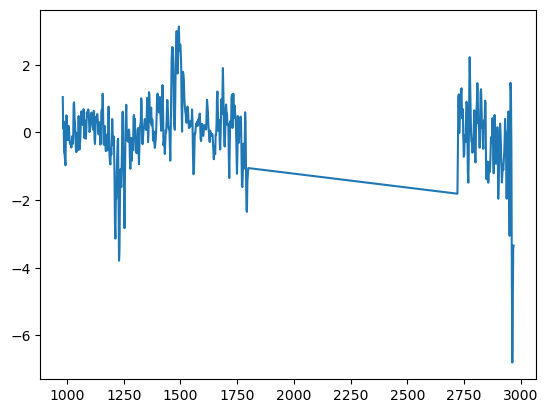

Prediction Set:  ['Magnesium Stearate v2', 'Zinc Stearate']


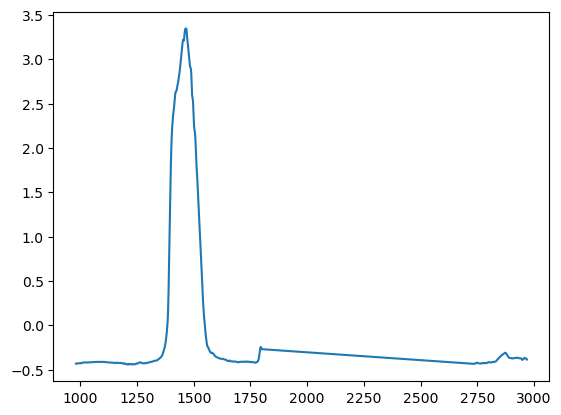

Prediction Set:  ['Polyethylene Terephthalate', 'Polyvinyl Chloride']


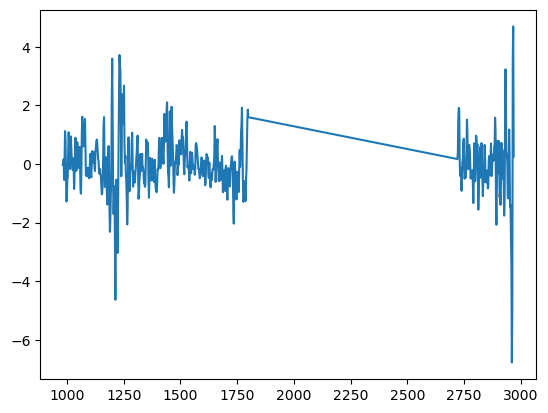

Prediction Set:  ['Calcium Stearate', 'Polypropylene', 'Polystyrene']


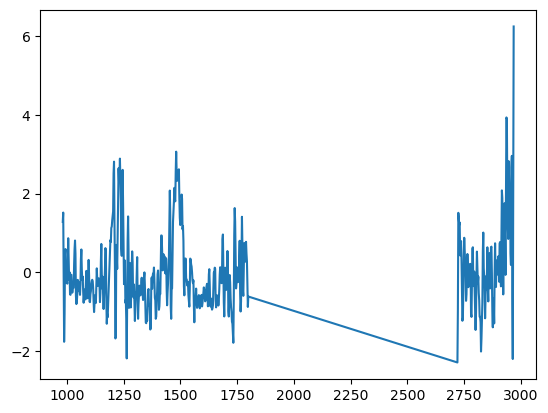

Prediction Set:  ['Magnesium Stearate v2', 'Polystyrene', 'Polyvinyl Chloride', 'Zinc Stearate']


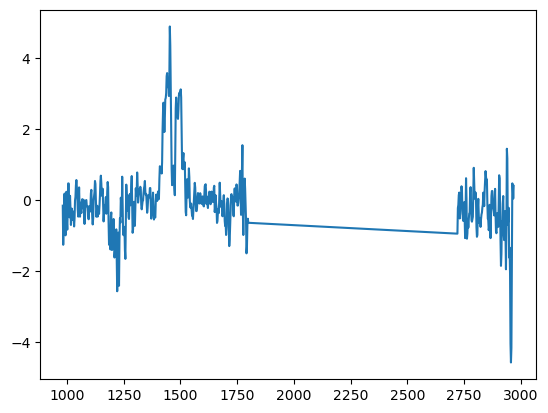

Prediction Set:  ['Magnesium Stearate v2', 'Sodium Stearate']


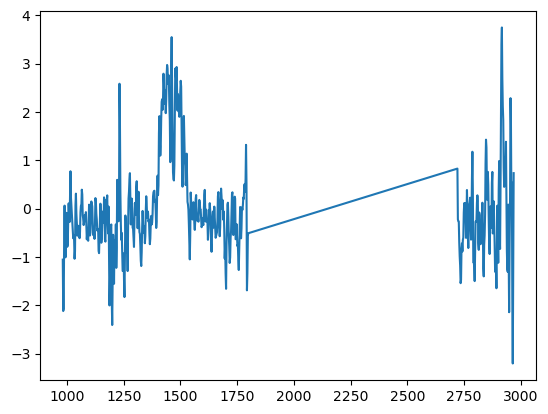

Prediction Set:  ['Magnesium Stearate v2', 'Polyvinyl Chloride', 'Zinc Stearate']


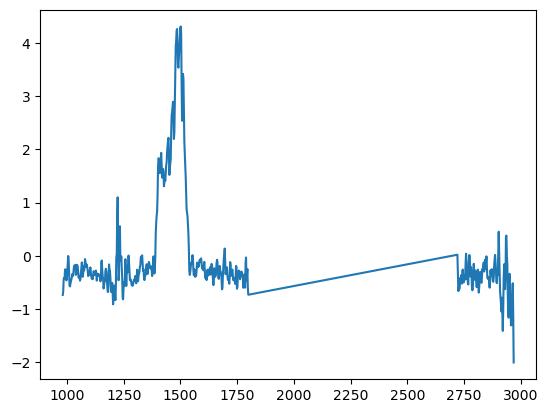

Prediction Set:  ['Magnesium Stearate v2', 'Zinc Stearate']


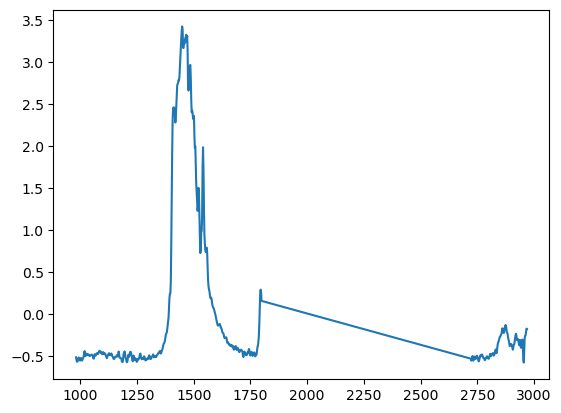

Prediction Set:  ['Magnesium Stearate v2', 'Polyethylene', 'Rubber', 'Zinc Stearate']


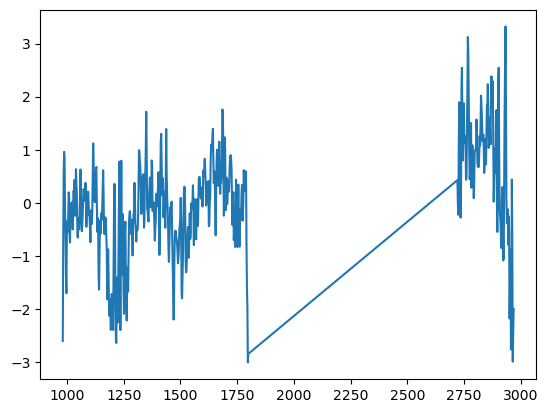

Prediction Set:  ['Magnesium Stearate v2', 'Polypropylene']


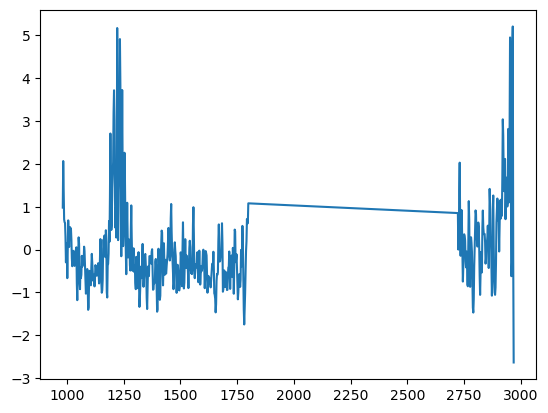

Prediction Set:  ['Polyethylene', 'Polypropylene', 'Rubber']


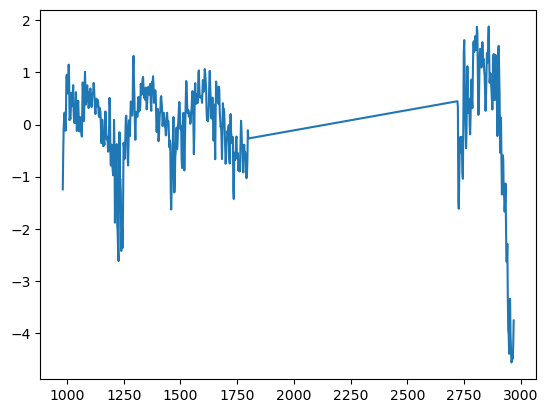

Prediction Set:  ['Polyethylene', 'Polystyrene']


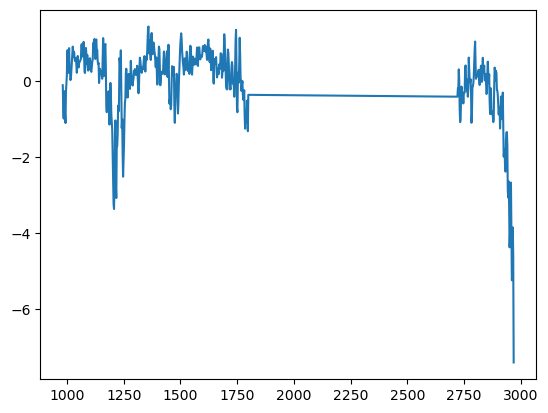

Prediction Set:  ['Polystyrene', 'Polyurethane']


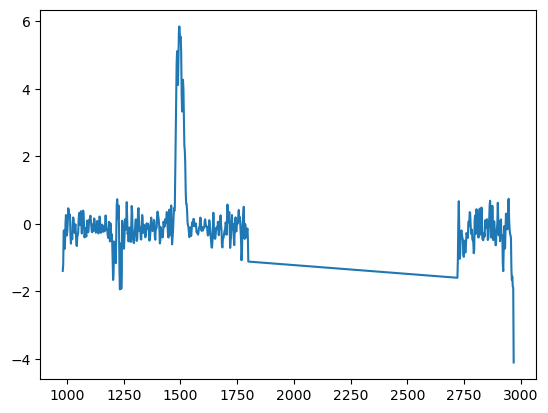

Prediction Set:  ['Magnesium Stearate v2', 'Polyvinyl Chloride', 'Zinc Stearate']


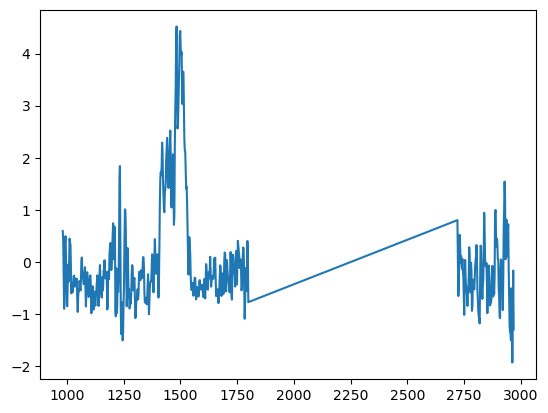

Prediction Set:  ['Magnesium Stearate v2', 'Polyvinyl Chloride', 'Zinc Stearate']


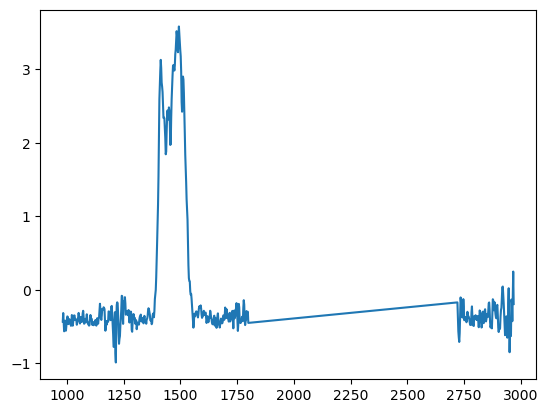

Prediction Set:  ['Polystyrene', 'Zinc Stearate']


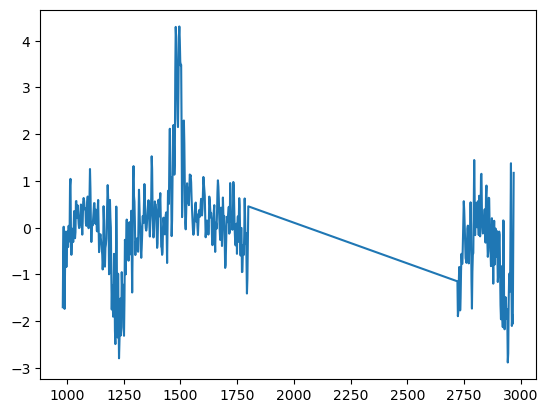

Prediction Set:  ['Magnesium Stearate v2', 'Polypropylene']


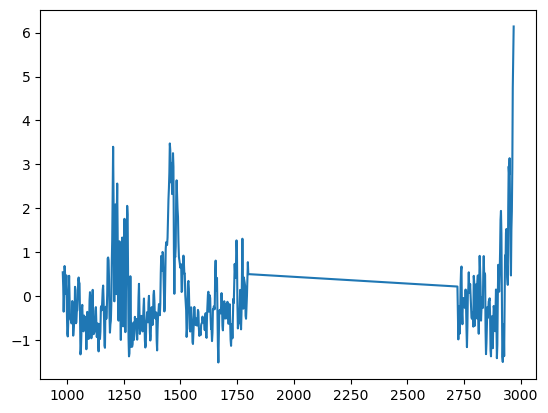

Prediction Set:  ['Magnesium Stearate v2', 'Polyvinyl Chloride', 'Zinc Stearate']


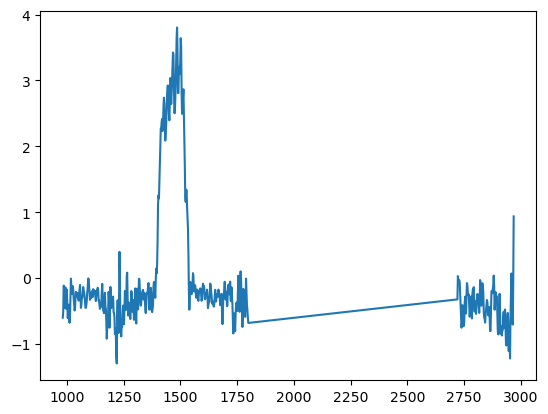

Prediction Set:  ['Magnesium Stearate v2', 'Polyethylene', 'Polystyrene', 'Sodium Stearate', 'Zinc Stearate']


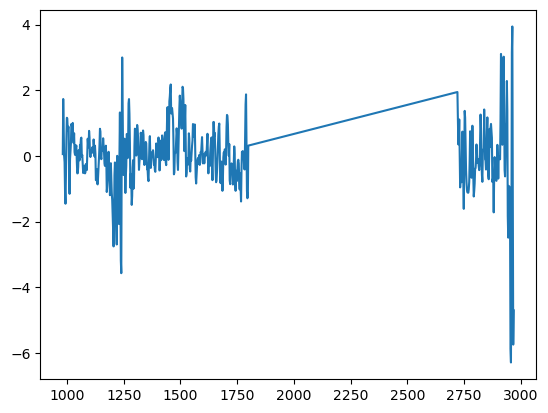

Prediction Set:  ['Polyamide', 'Polystyrene']


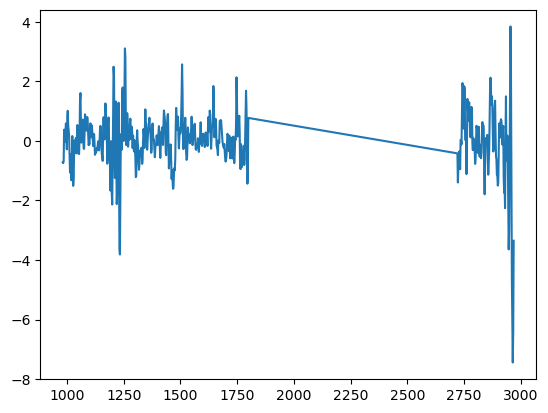

Prediction Set:  ['Magnesium Stearate v2', 'Polypropylene']


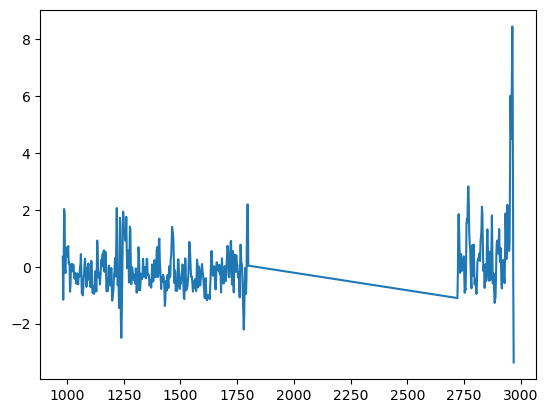

Prediction Set:  ['Polyethylene', 'Polystyrene', 'Rubber']


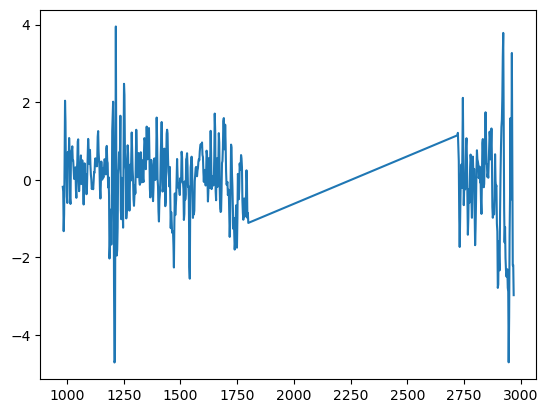

Prediction Set:  ['Calcium Stearate', 'Polyethylene', 'Polypropylene', 'Polystyrene']


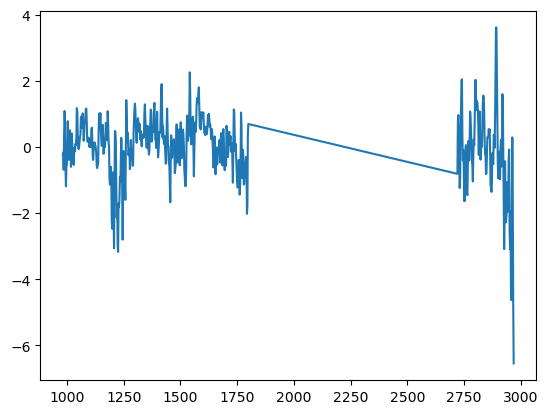

Prediction Set:  ['Polypropylene', 'Polystyrene', 'Rubber', 'Silicone Rubber']


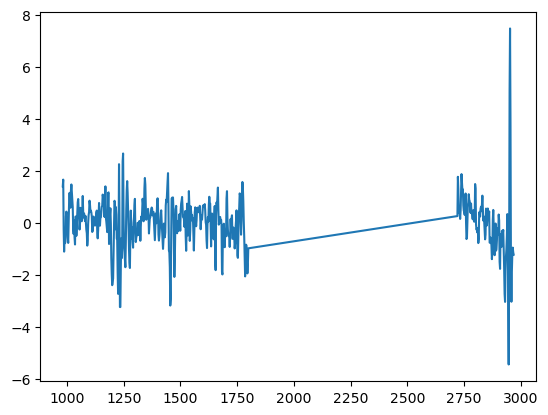

Prediction Set:  ['Polystyrene', 'Polyurethane', 'Rubber']


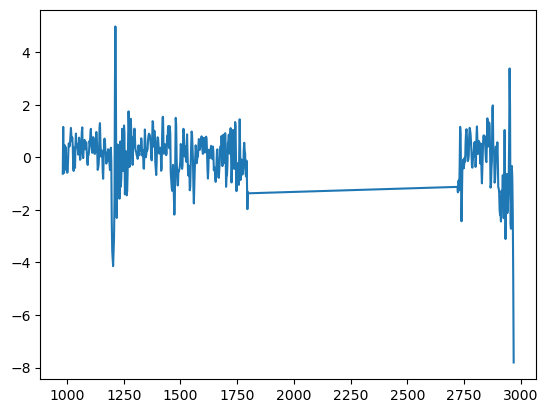

Prediction Set:  ['Polypropylene', 'Polystyrene', 'Rubber']


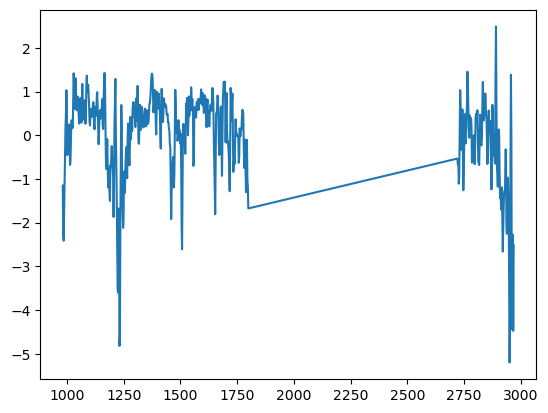

Prediction Set:  ['Polyethylene', 'Rubber']


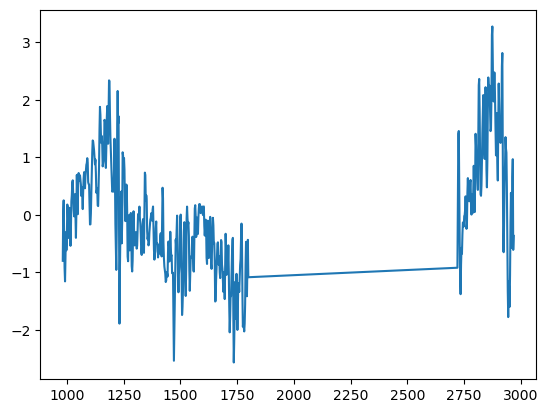

Prediction Set:  ['Magnesium Stearate v2', 'Polyethylene']


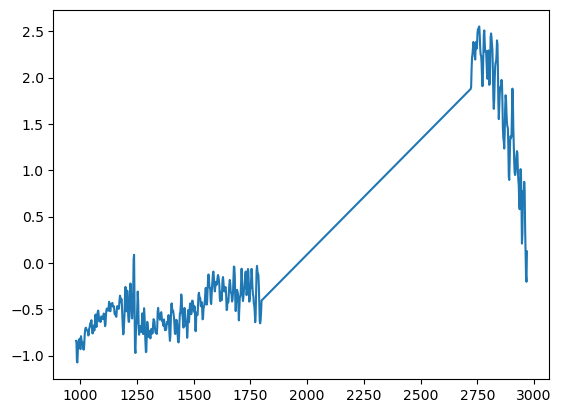

Prediction Set:  ['Cellulose Acetate', 'Polyurethane', 'Rubber']


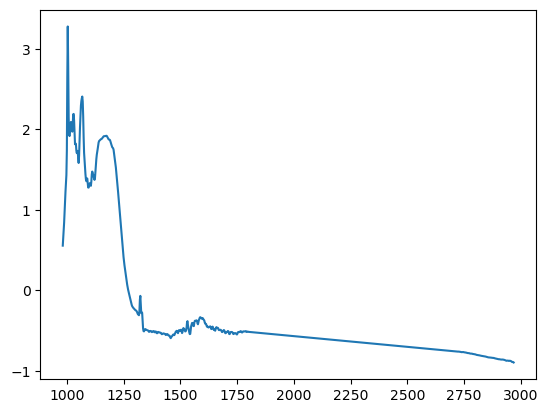

Prediction Set:  ['Magnesium Stearate v2', 'Polyethylene']


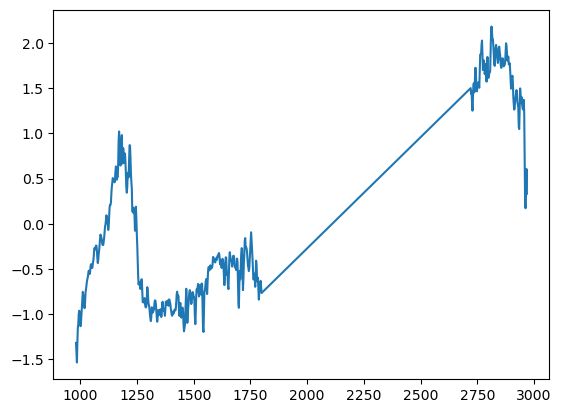

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Polyamide', 'Polypropylene', 'Zinc Stearate']


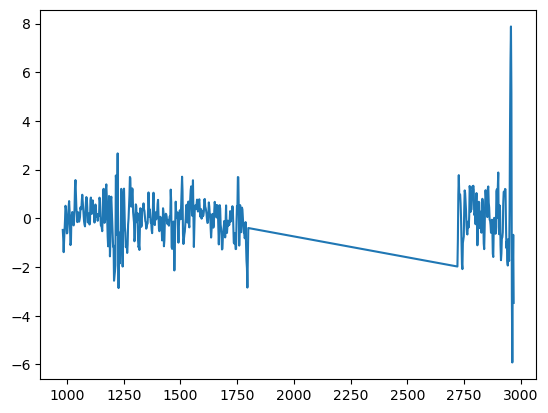

Prediction Set:  ['Magnesium Stearate v2', 'Polyethylene']


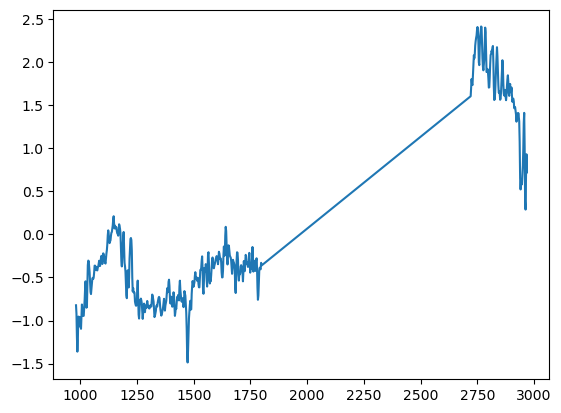

Prediction Set:  ['Polypropylene', 'Polystyrene', 'Rubber']


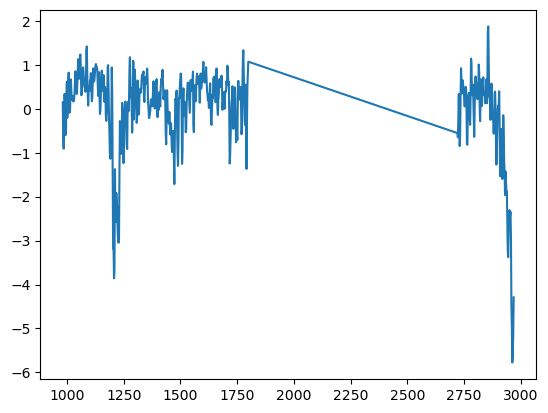

Prediction Set:  ['Polypropylene', 'Rubber']


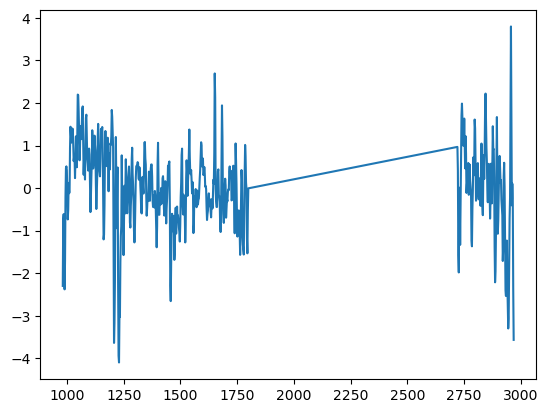

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Polyethylene', 'Sodium Stearate', 'Zinc Stearate']


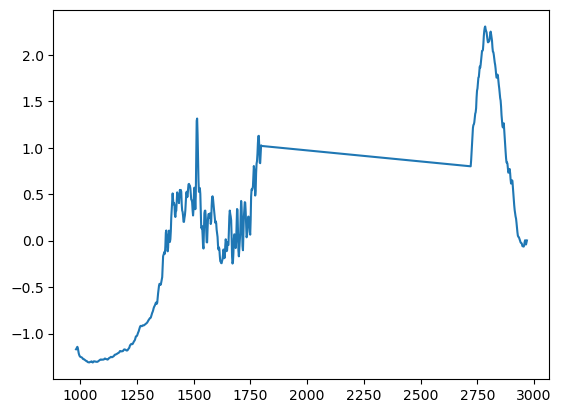

Prediction Set:  ['Calcium Stearate', 'Polypropylene']


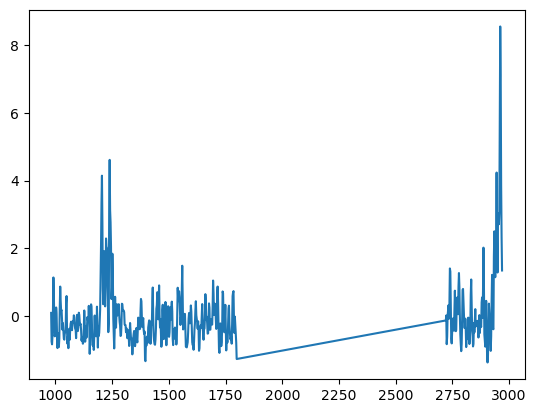

Prediction Set:  ['Polyethylene', 'Polystyrene', 'Polyurethane', 'Rubber']


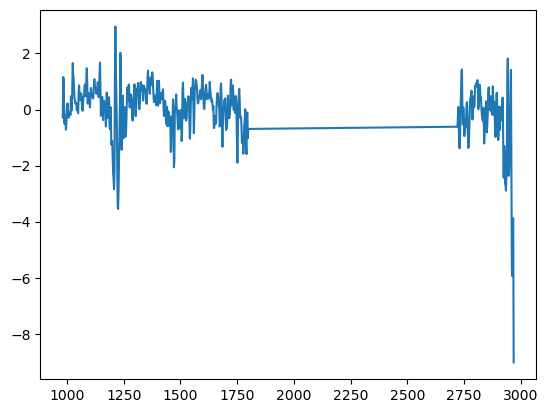

Prediction Set:  ['Polycarbonate', 'Polypropylene']


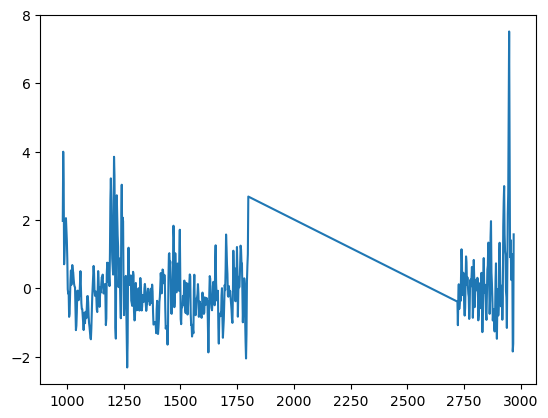

Prediction Set:  ['Magnesium Stearate v2', 'Polypropylene', 'Zinc Stearate']


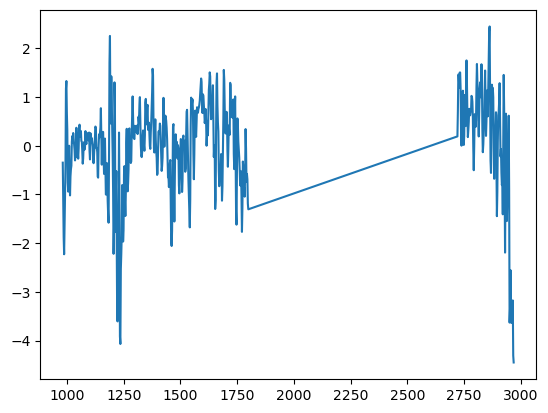

Prediction Set:  ['Polyethylene', 'Rubber']


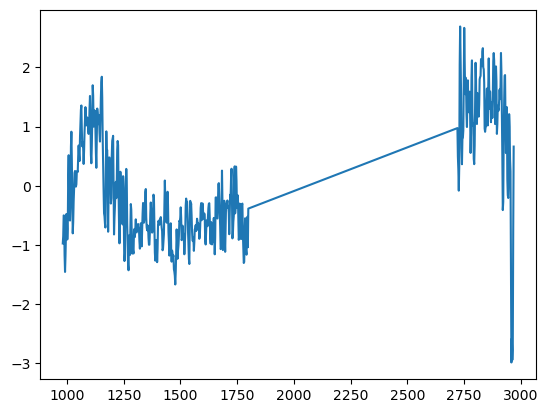

Prediction Set:  ['Polypropylene', 'Polystyrene']


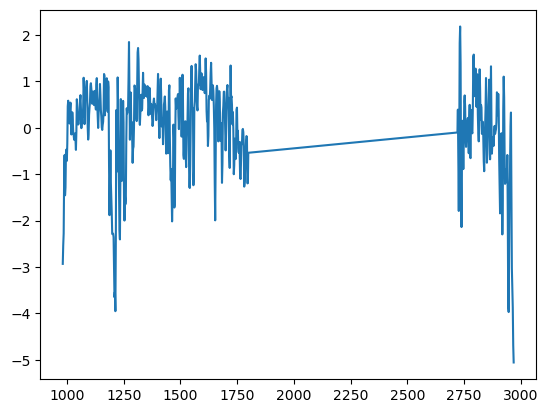

Prediction Set:  ['Magnesium Stearate v2', 'Polyethylene']


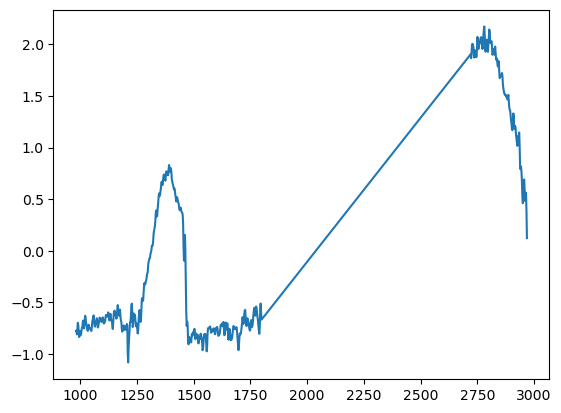

Prediction Set:  ['Polyamide', 'Polyethylene Terephthalate', 'Polyethylene Vinyl Acetate']


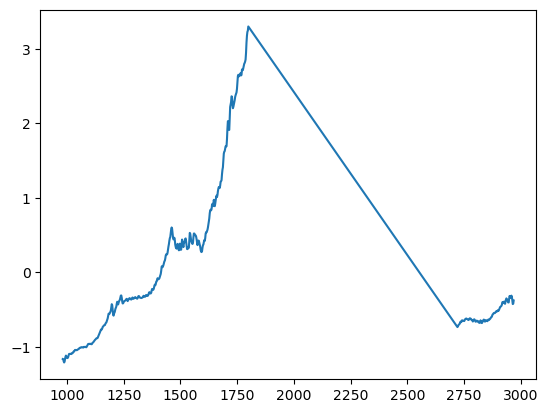

Prediction Set:  ['Calcium Stearate', 'Zinc Stearate']


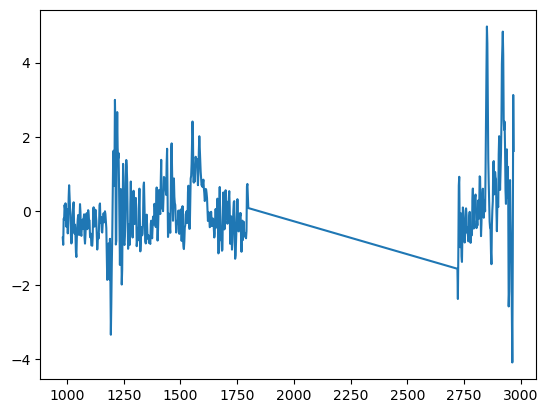

Prediction Set:  ['Calcium Stearate', 'Zinc Stearate']


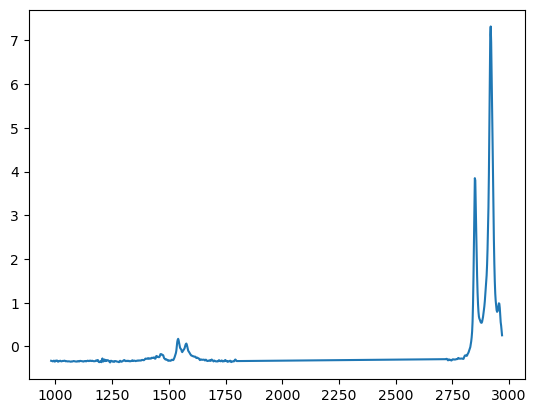

Prediction Set:  ['Calcium Stearate', 'Zinc Stearate']


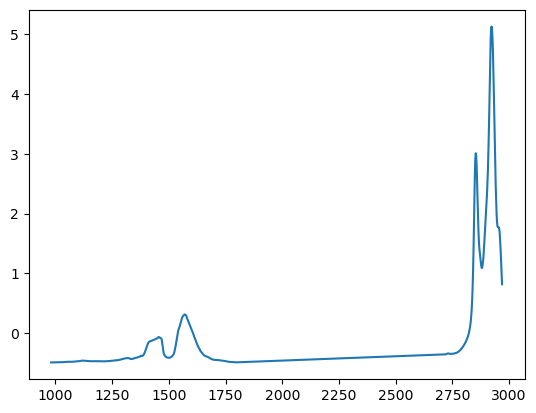

Prediction Set:  ['Magnesium Stearate v2', 'Polypropylene']


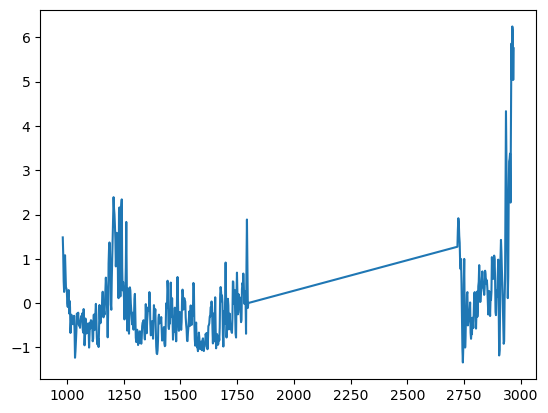

Prediction Set:  ['Magnesium Stearate v2', 'Zinc Stearate']


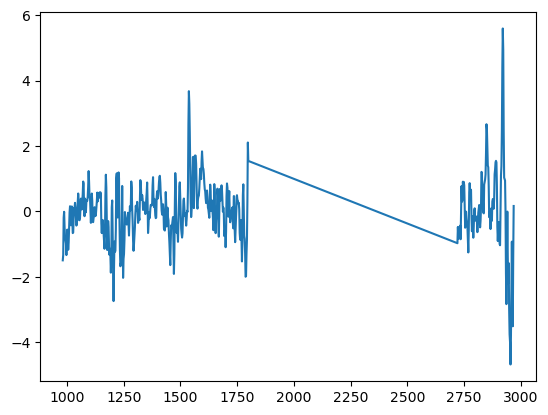

Prediction Set:  ['Calcium Stearate', 'Rubber']


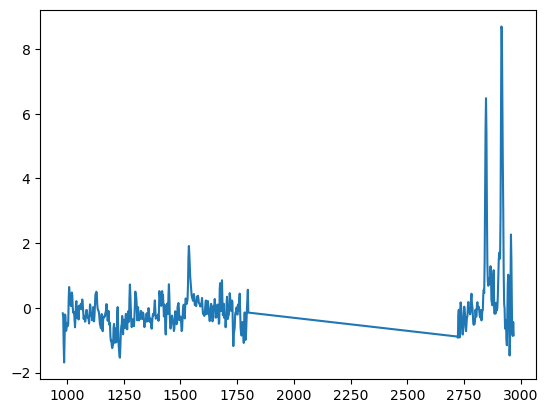

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


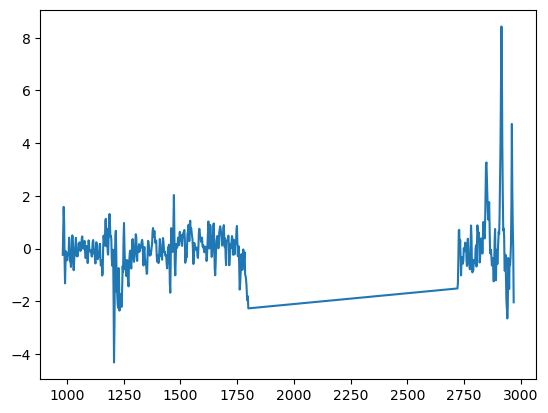

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Polypropylene']


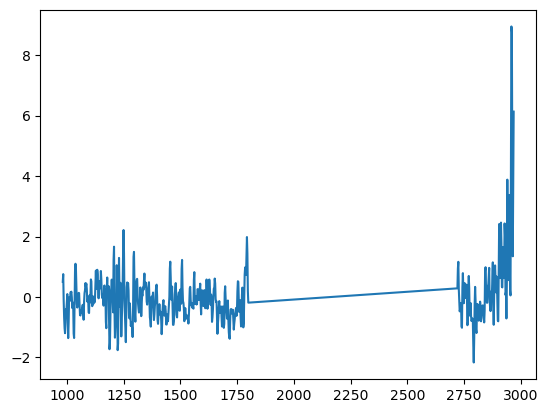

Prediction Set:  ['Polycarbonate', 'Polyvinyl Chloride']


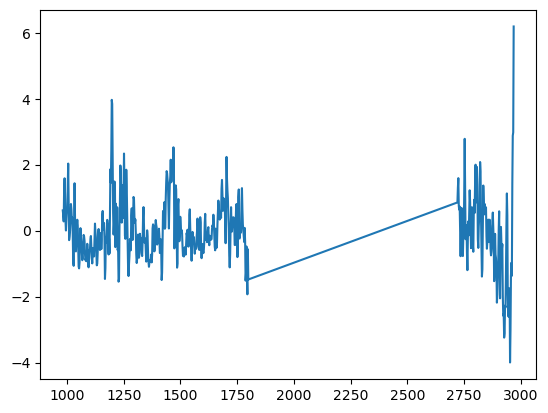

Prediction Set:  ['Polycarbonate', 'Polyethylene Vinyl Acetate']


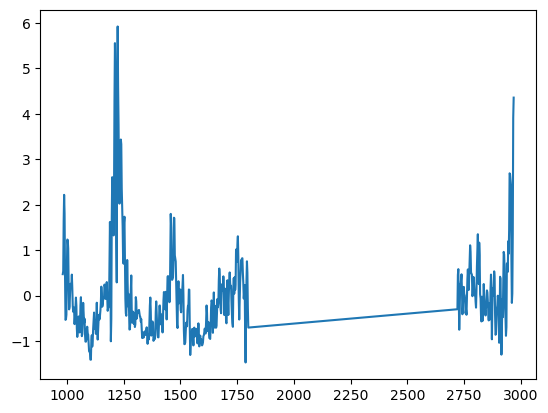

Prediction Set:  ['Calcium Stearate', 'Polyethylene', 'Polyethylene Terephthalate', 'Polystyrene', 'Polyurethane', 'Rubber', 'Silicone Rubber']


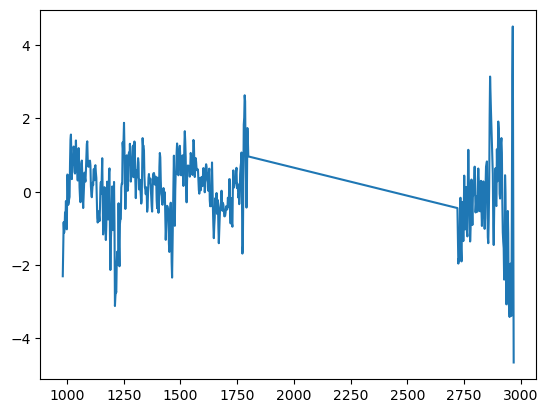

Prediction Set:  ['Calcium Stearate', 'Polyethylene', 'Rubber']


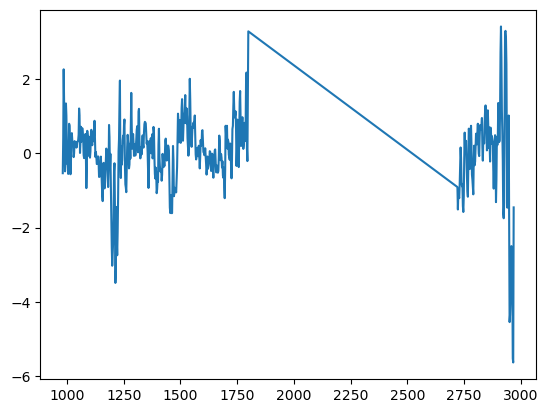

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Polypropylene', 'Zinc Stearate']


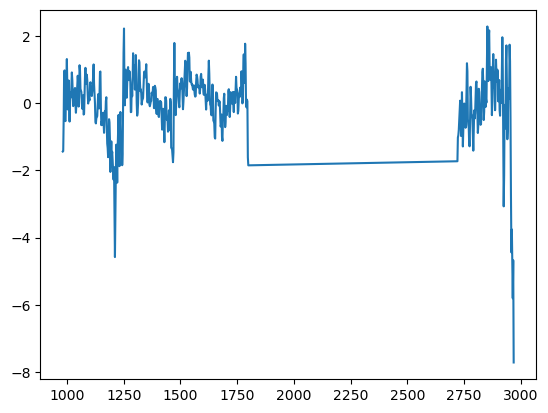

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


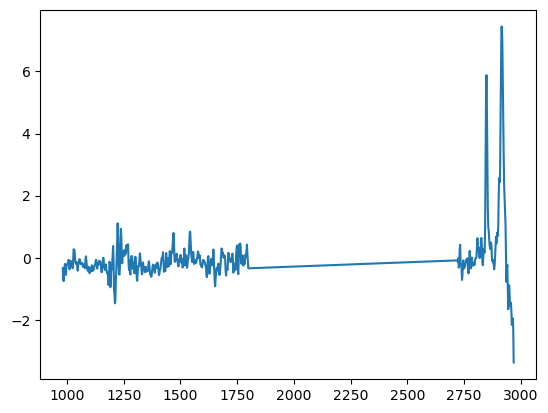

Prediction Set:  ['Calcium Stearate', 'Zinc Stearate']


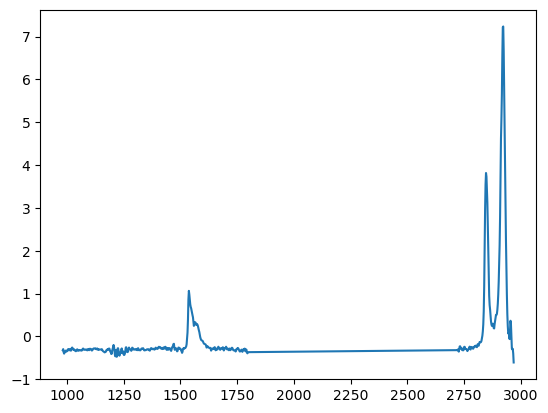

Prediction Set:  ['Polypropylene', 'Polystyrene', 'Rubber']


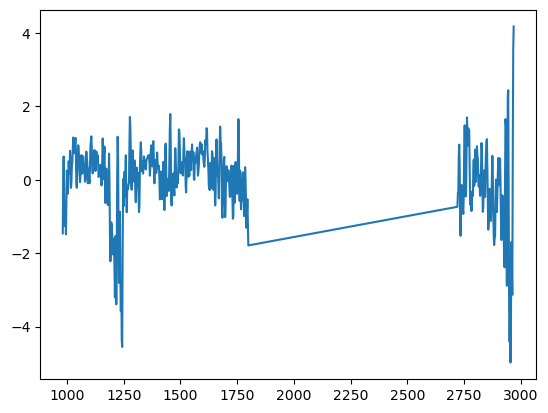

Prediction Set:  ['Polypropylene', 'Polystyrene']


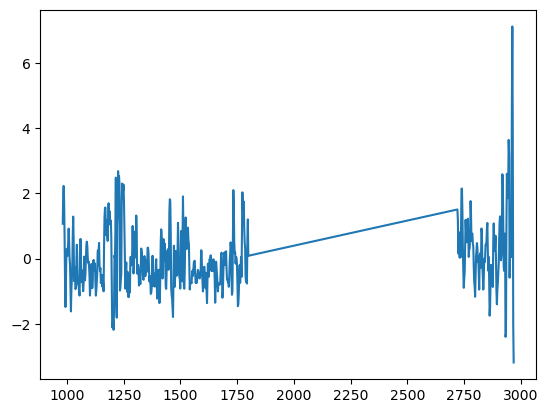

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


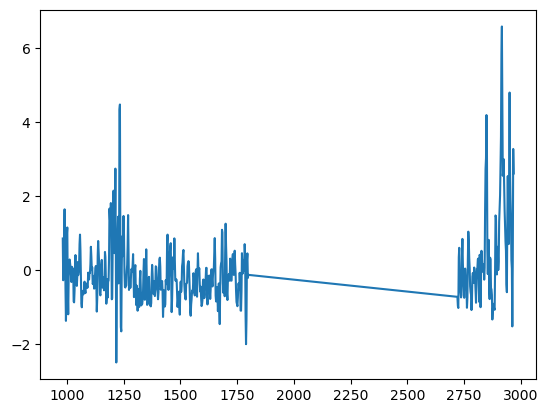

Prediction Set:  ['Polyethylene Vinyl Acetate', 'Polypropylene']


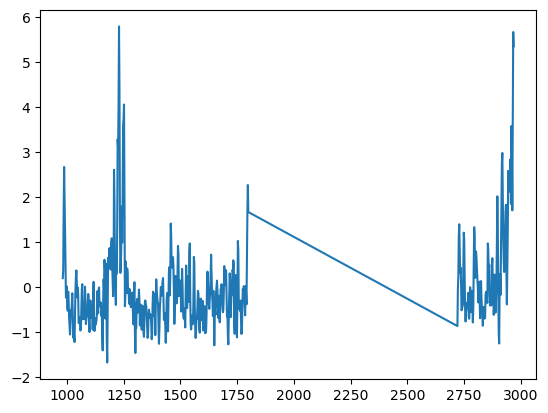

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


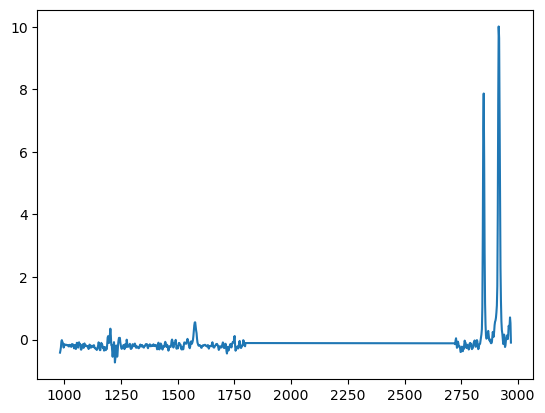

Prediction Set:  ['Polypropylene', 'Polystyrene', 'Rubber']


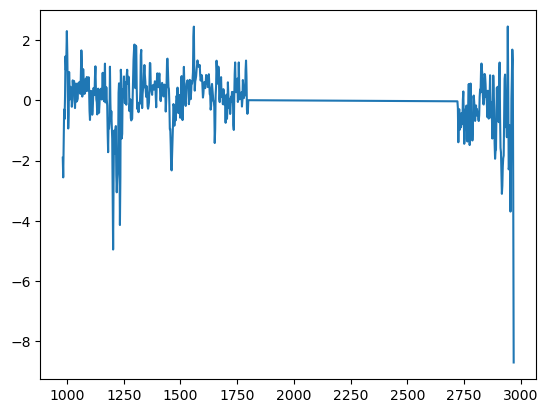

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Polyethylene', 'Rubber']


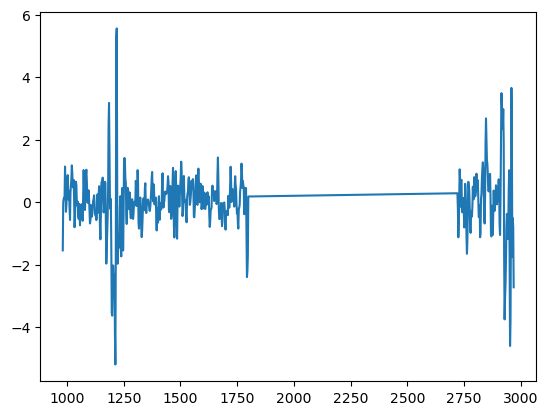

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


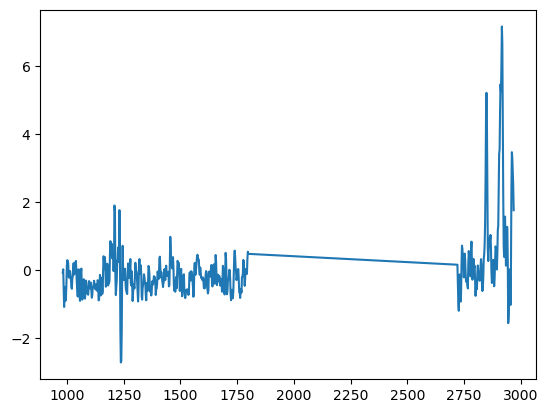

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


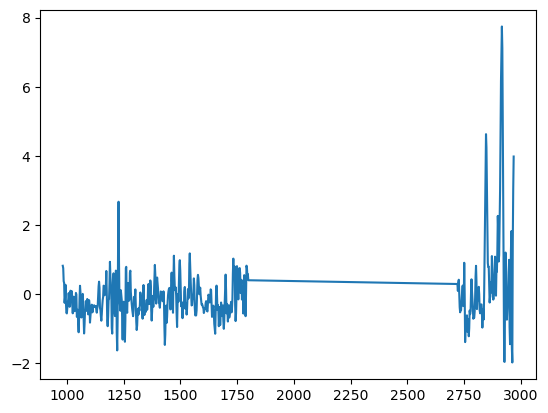

Prediction Set:  ['Polycarbonate', 'Polyethylene Vinyl Acetate']


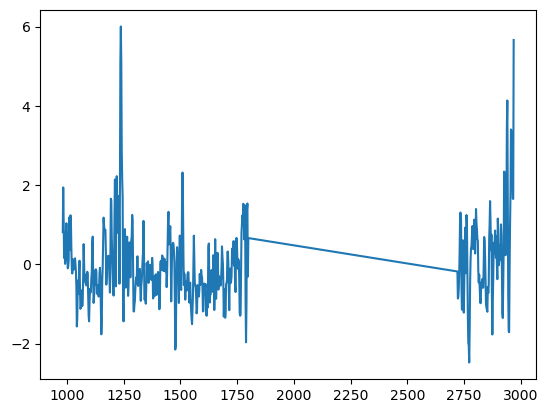

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


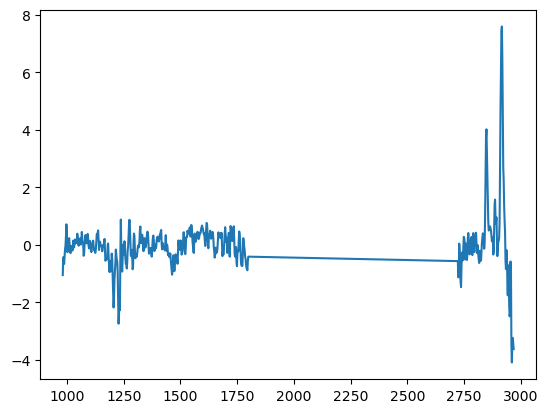

Prediction Set:  ['Polyethylene', 'Polypropylene', 'Polystyrene']


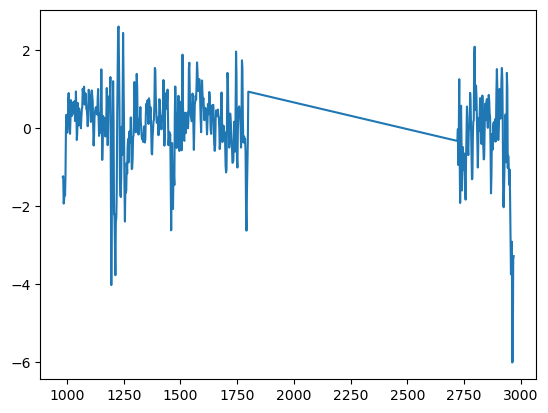

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


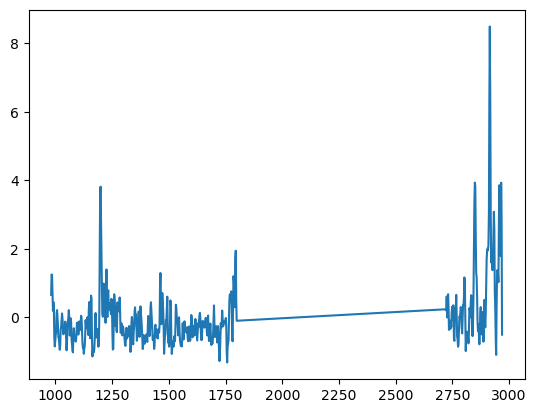

Prediction Set:  ['Calcium Stearate', 'Polyethylene', 'Rubber']


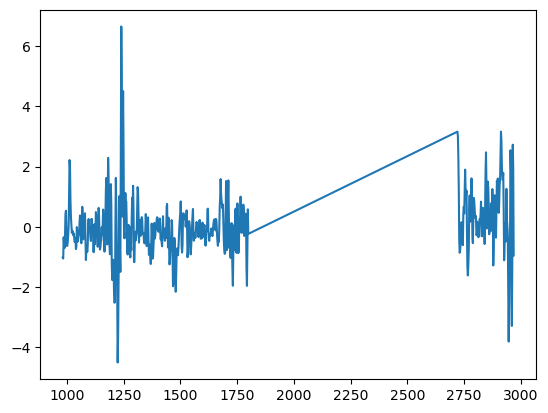

Prediction Set:  ['Magnesium Stearate v2', 'Sodium Stearate']


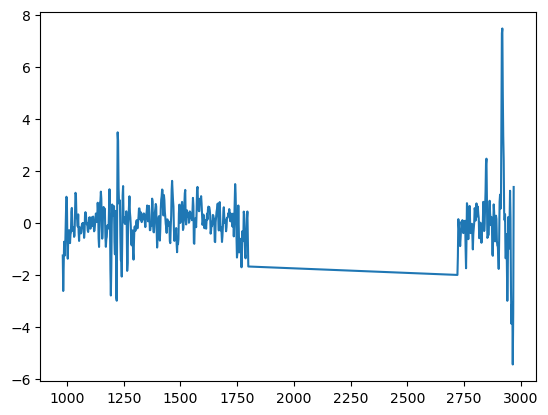

Prediction Set:  ['Magnesium Stearate v2', 'Zinc Stearate']


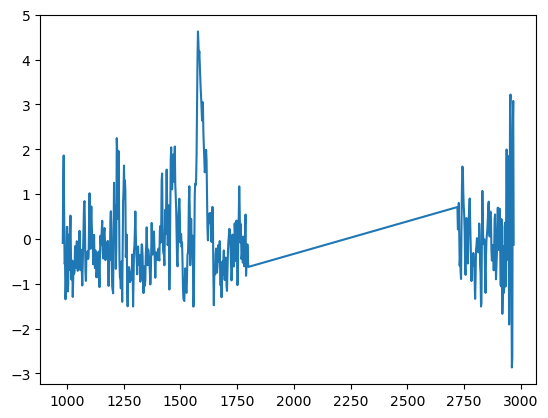

Prediction Set:  ['Polypropylene', 'Polystyrene']


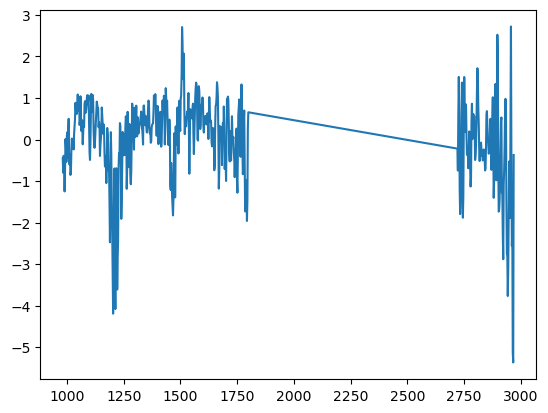

Prediction Set:  ['Polypropylene', 'Polystyrene', 'Rubber']


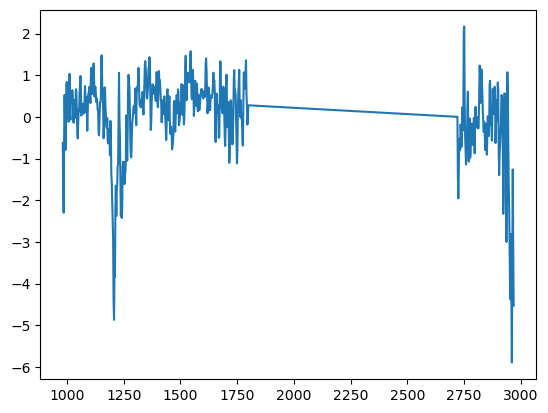

Prediction Set:  ['Magnesium Stearate v2', 'Zinc Stearate']


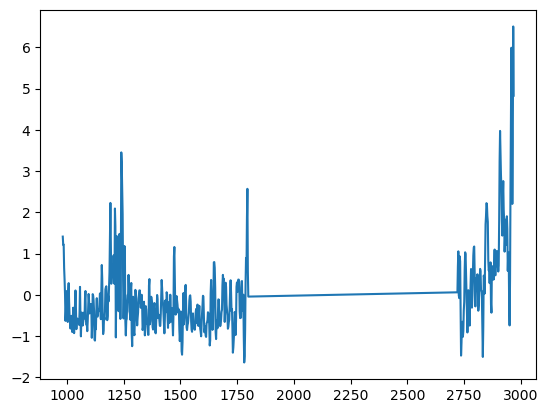

Prediction Set:  ['Polystyrene', 'Rubber']


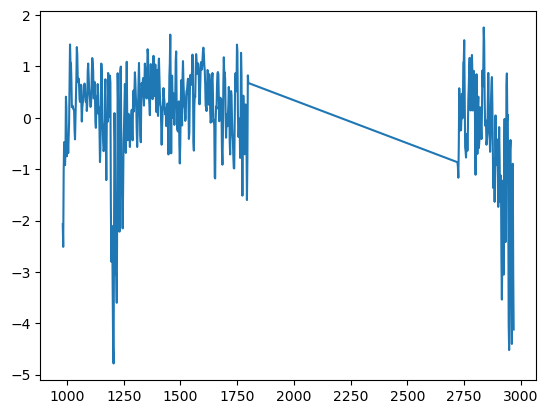

Prediction Set:  ['Polyethylene', 'Polypropylene', 'Polystyrene']


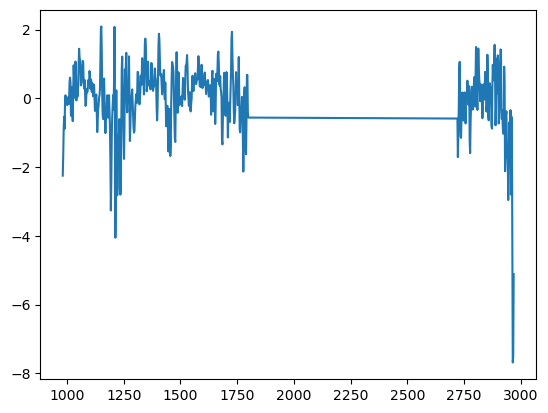

Prediction Set:  ['Calcium Stearate', 'Polyethylene', 'Polypropylene']


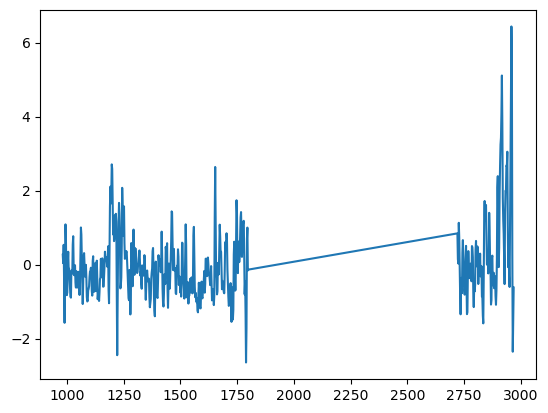

Prediction Set:  ['Polyamide', 'Polystyrene', 'Rubber']


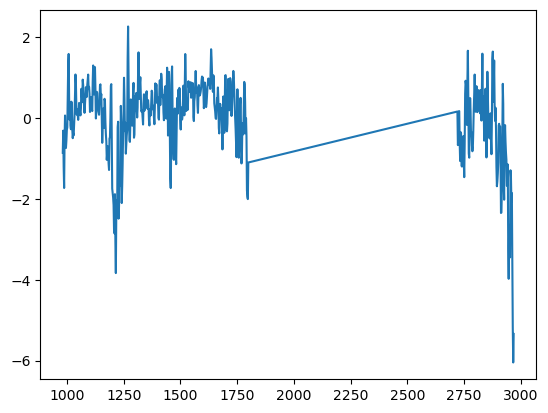

Prediction Set:  ['Calcium Stearate', 'Polyethylene', 'Rubber']


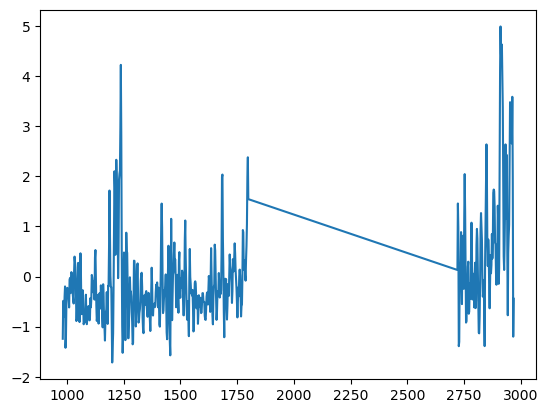

Prediction Set:  ['Polyethylene Vinyl Acetate', 'Polypropylene']


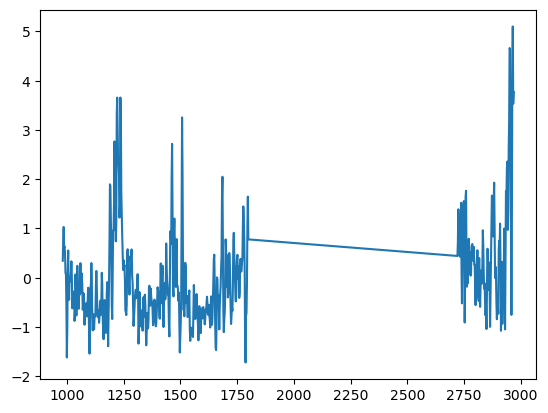

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


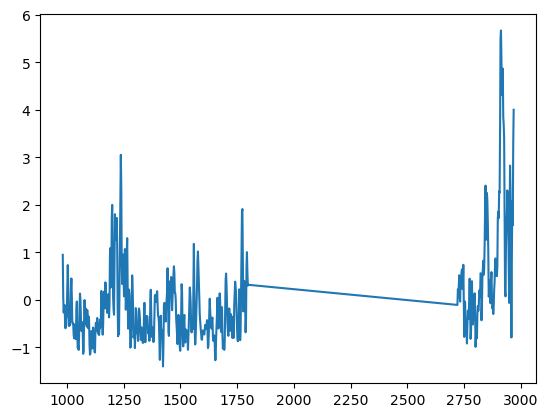

Prediction Set:  ['Calcium Stearate', 'Polypropylene']


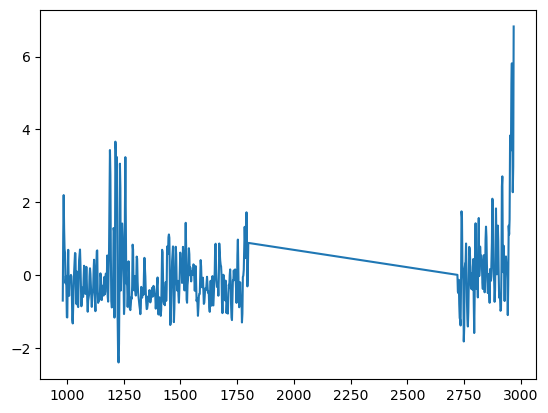

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


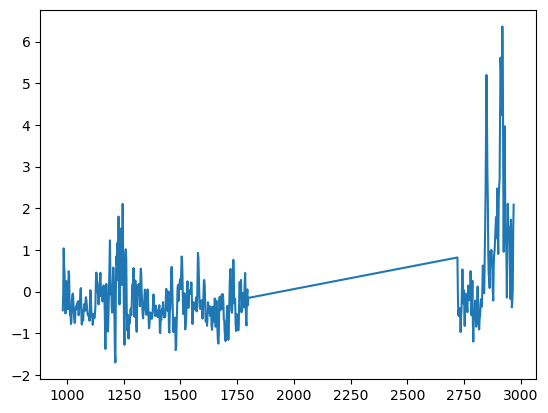

Prediction Set:  ['Magnesium Stearate v2', 'Polypropylene', 'Polystyrene', 'Zinc Stearate']


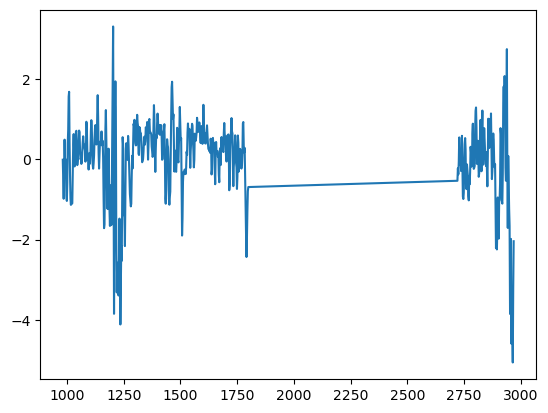

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


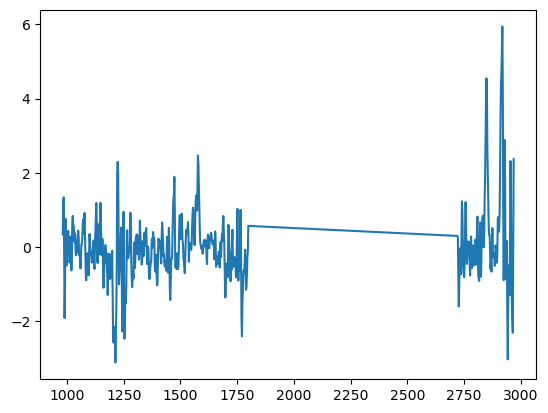

Prediction Set:  ['Polyethylene', 'Polystyrene', 'Rubber']


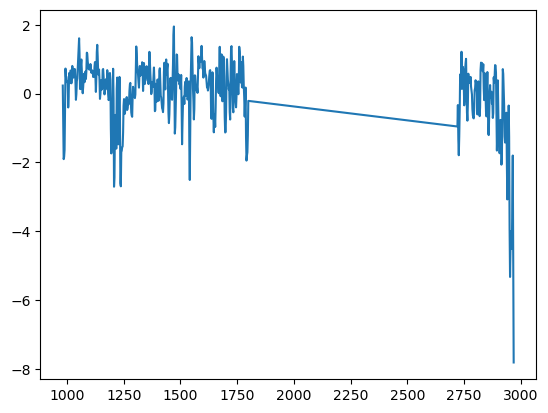

Prediction Set:  ['Polystyrene', 'Polyurethane', 'Rubber']


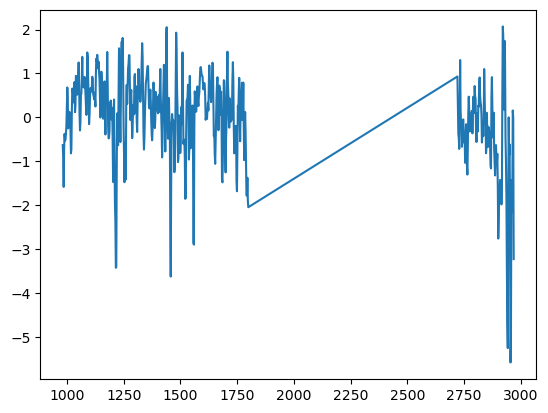

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Polypropylene']


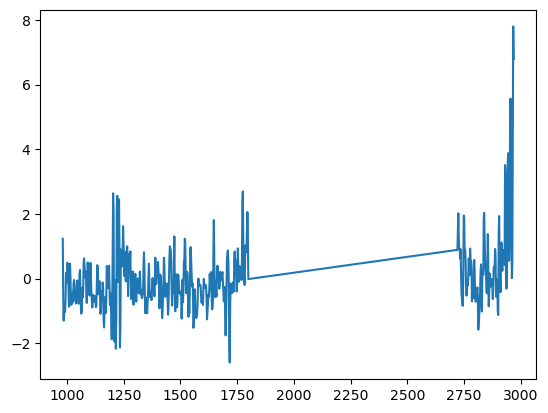

Prediction Set:  ['Polyethylene', 'Polystyrene']


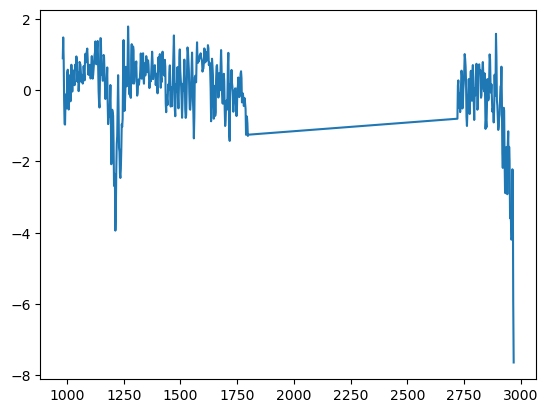

Prediction Set:  ['Calcium Stearate', 'Magnesium Stearate v2', 'Zinc Stearate']


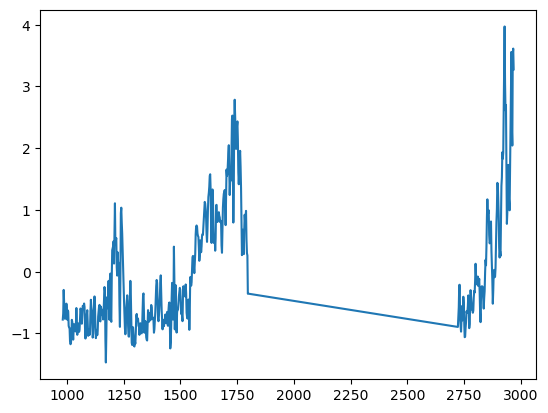

Prediction Set:  ['Calcium Stearate', 'Polypropylene']


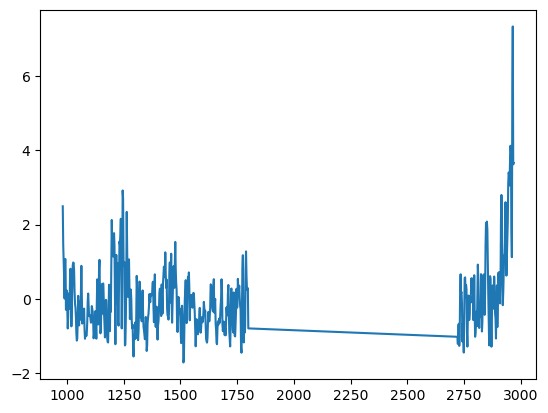

Prediction Set:  ['Calcium Stearate', 'Polyethylene', 'Sodium Stearate']


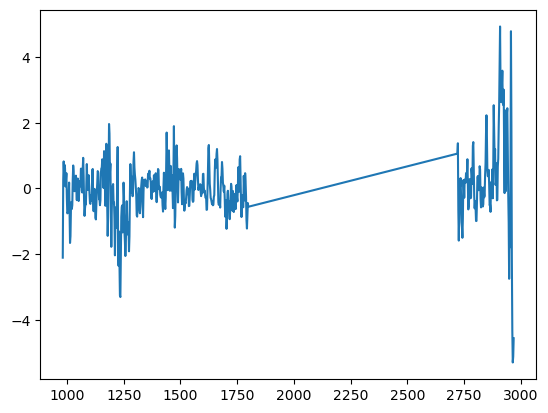

Prediction Set:  ['Calcium Stearate', 'Polypropylene']


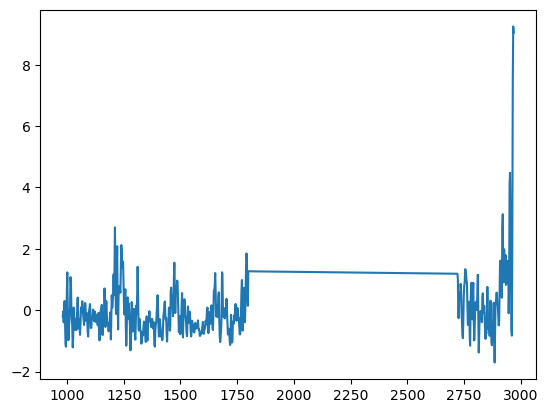

Prediction Set:  ['Magnesium Stearate v2', 'Polyethylene']


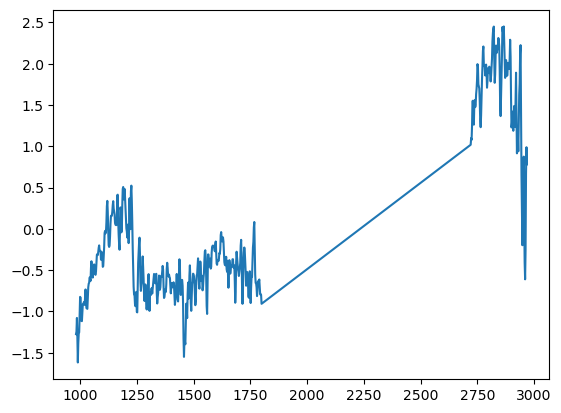

Prediction Set:  ['Polyethylene', 'Polypropylene', 'Polystyrene']


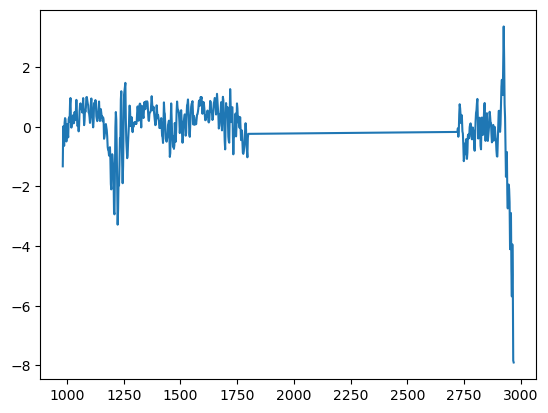

Prediction Set:  ['Calcium Stearate', 'Zinc Stearate']


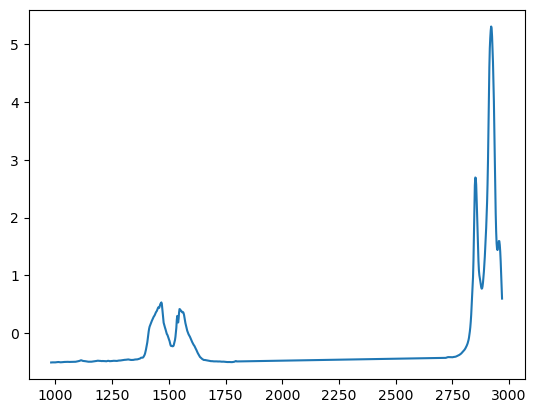

Prediction Set:  ['Calcium Stearate', 'Sodium Stearate']


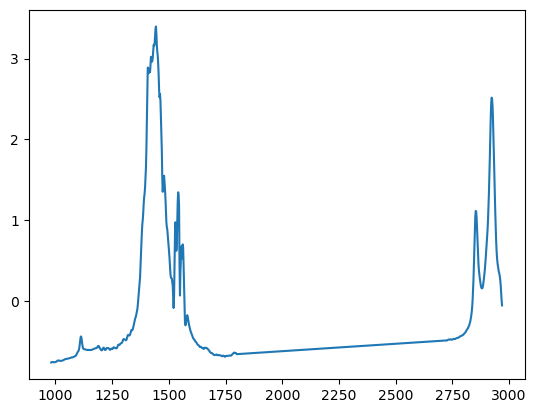

Prediction Set:  ['Magnesium Stearate v2', 'Polystyrene']


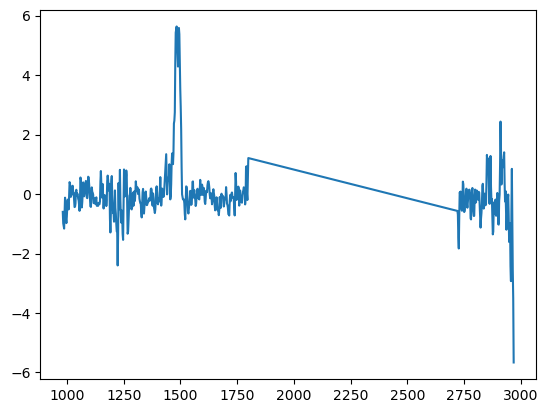

Prediction Set:  ['Polyethylene', 'Polypropylene']


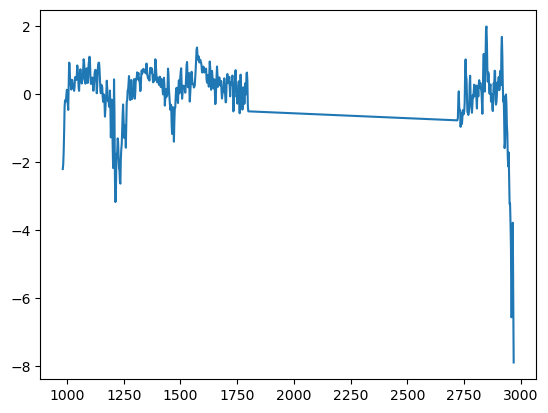

Prediction Set:  ['Polyamide', 'Polystyrene', 'Polyurethane']


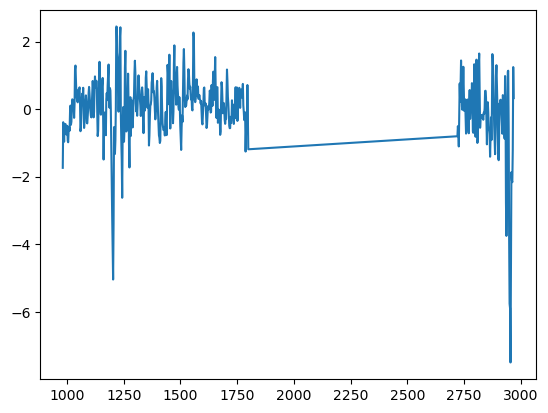

Prediction Set:  ['Calcium Stearate', 'Polyethylene']


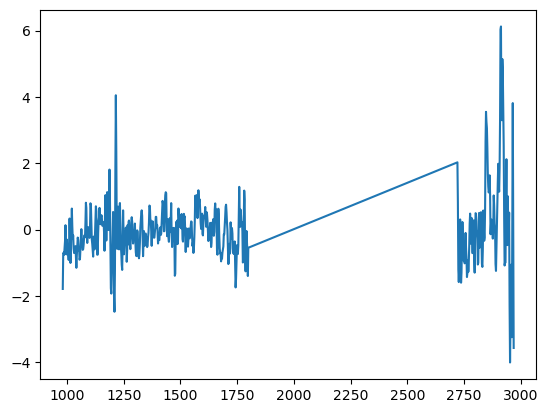

In [56]:
#i = mult_label[0]
for i in mult_label:
    print('Prediction Set: ', prediction_sets_n[i])
    plt.plot(wl_list, X_test[i])
    plt.show()

# Rebecca

In [69]:
reference_library, calibration_set, test_set, label_table = gen_data_sets(rebecca_df,
                                                                          stearates_df,
                                                                          gloves_data_ir,
                                                                          seed)

In [70]:
(X_train, X_cal, X_test, 
 y_train, y_cal, y_test, 
 label_train, label_cal, label_test, 
 n_test, wl_list) = process_data(reference_library,
                 calibration_set,
                 test_set)

In [71]:
X_test.shape, X_train.shape, X_cal.shape

((1214, 535), (213, 535), (159, 535))

PSL


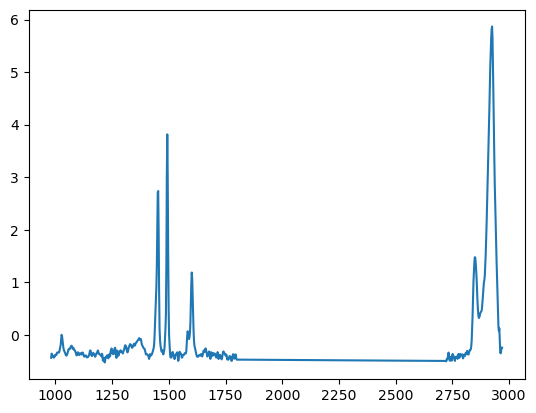

In [72]:
print(y_train[10])
_ = plt.plot(wl_list, X_train[2,:])

In [73]:
# Nearest Neighbor

# Calculate HQI for calibration set
smx_cal = smx_nn(X_train, X_cal, label_train)

# Calculate HQI for test set
smx_test = smx_nn(X_train, X_test, label_train)

In [74]:
# Set confidence level 1 - alpha
n = smx_cal.shape[0]
alpha = 0.1
for alpha in [alpha]:#np.linspace(0.01,.2):
    prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)

    # If we know to true labels of the test set, calculate the empirical confidence 
    if label_test[0] != '' and not np.isnan(label_test[0]):
        empirical_confidence = prediction_sets[np.arange(n_test),label_test].mean()
    else:
        empirical_confidence = None
    
    print('Theo Confidence: '+str(1-alpha))
    print('Threshold(s) used: '+str(np.int64(100*(1-qhat))/100))
    if empirical_confidence is not None:
        print('Empirical confidence: '+str(int(100*empirical_confidence)/100))
    print('Mean prediction set size: '+str(np.round(prediction_sets.sum(1).mean(), 2)))
    print('')

Theo Confidence: 0.9
Threshold(s) used: 0.9
Mean prediction set size: 1.43



In [75]:
prediction_sets_n = [list(label_table.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n])

In [76]:
zero_label = np.where(prediction_sets_size == 0)[0]
single_label = np.where(prediction_sets_size == 1)[0]
mult_label = np.where(prediction_sets_size > 1)[0]

print('Sets with zero labels: ' + str(zero_label.shape[0]))
print('Sets with one label: ' + str(single_label.shape[0]))
print('Sets with >1 labels: ' + str(mult_label.shape[0]))

Sets with zero labels: 0
Sets with one label: 867
Sets with >1 labels: 347


In [77]:
if y_test[0] != '' and not np.isnan(label_test[0]):
    print('accuracy of single labels: ' +str(np.mean([prediction_sets_n[i][0]==y_test[i] for i in single_label])))

In [78]:
output = [prediction_sets_n[i][0] if i in single_label else 
          '--outlier--' if i in zero_label else 
          '--manual check!--' for i in range(label_test.shape[0])]
output_df = pd.DataFrame({'id':test_set['id'],
                          'prection_set':prediction_sets_n,
                          'output':output})
output_df.to_csv('results/test_set_predictions_rebecca_stearate.csv')
output_df

,id,prection_set,output
0,MF_L_01_0514_2,[PP],PP
1,MF_L_01_0514_9,[PP],PP
2,MF_L_01_0514_12,[PE],PE
3,MF_L_01_0514_14,[PP],PP
4,MF_L_01_0514_17,"[Magnesium Stearate v2, PP]",--manual check!--
...,...,...,...
1209,KC_N_02_0328_28,[Calcium Stearate],Calcium Stearate
1210,KC_N_02_0328_29,[Zinc Stearate],Zinc Stearate
1211,KC_N_02_0328_30,"[Magnesium Stearate v2, PE, Zinc Stearate]",--manual check!--
1212,KC_N_02_0328_31,[Calcium Stearate],Calcium Stearate


In [79]:
output_df.groupby('output').count()

,id,prection_set
output,,
--manual check!--,347,347
Calcium Stearate,253,253
Magnesium Stearate v2,143,143
PE,197,197
PP,115,115
PSL,14,14
Sodium Stearate,5,5
Zinc Stearate,140,140
